# Photo Retouch — Training Environment

Advanced Mathematics for Deep Learning final project.

This notebook imports the workflow libraries and configures GPU/CPU selection. Dataset preparation and model training will be added later. Restart the kernel after changing dependencies.

## Standard library utilities

In [1]:
from pathlib import Path
import json
import platform
import random
import time


## Numerical analysis and visualization

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go


## Image processing and dataset splitting

In [3]:
import cv2
from PIL import Image, ImageDraw
from sklearn.model_selection import train_test_split
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import kagglehub


## Deep learning

In [4]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks


## Progress and memory monitoring

In [5]:
import psutil
from tqdm.auto import tqdm


## Apple Metal GPU configuration

Run this after restarting the **photo-retouch (Python 3.12)** kernel. TensorFlow automatically places supported operations on the GPU. Auxiliary operations may use the CPU. Use `jit_compile=False` when compiling the future Keras model.

In [6]:
tf.config.set_soft_device_placement(True)
gpus = tf.config.list_physical_devices("GPU")
TRAINING_DEVICE = "/GPU:0" if gpus else "/CPU:0"
print(f"TensorFlow: {tf.__version__}")
print(f"Available GPUs: {gpus}")
print(f"Preferred training device: {TRAINING_DEVICE}")
with tf.device(TRAINING_DEVICE):
    device_probe = tf.matmul(tf.ones((32, 32)), tf.ones((32, 32)))
print(f"Matrix multiplication executed on: {device_probe.device}")
if gpus and "GPU:0" not in device_probe.device:
    raise RuntimeError("GPU detected, but the probe did not execute on it.")


TensorFlow: 2.18.1
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Preferred training device: /GPU:0
Matrix multiplication executed on: /job:localhost/replica:0/task:0/device:GPU:0


2026-11-14 15:16:48.147377: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-14 15:16:48.147510: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-14 15:16:48.147536: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1794687408.148079 25240884 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794687408.148635 25240884 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


## Dataset download and inspection

We use Intel Image Classification, focusing on four scene categories:
sea, forest, street, and buildings.

Training and validation images will come from separate subsets of
seg_train. The seg_test split will remain reserved for final evaluation.

Source: https://www.kaggle.com/datasets/puneet6060/intel-image-classification

In [7]:
from pathlib import Path
import kagglehub

# Find the project root from the notebook's working directory.
current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    (
        folder
        for folder in (current_dir, *current_dir.parents)
        if (folder / "requirements.txt").is_file()
        and (folder / "notebooks").is_dir()
    ),
    None,
)

if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Open this notebook from the photo-retouch project folder."
    )

DATA_DIR = PROJECT_ROOT / "data" / "intel-image-classification"
DATA_DIR.mkdir(parents=True, exist_ok=True)

dataset_path = Path(
    kagglehub.dataset_download(
        "puneet6060/intel-image-classification",
        output_dir=str(DATA_DIR),
    )
)

print(f"Dataset location: {dataset_path}")

100%|██████████| 346M/346M [00:03<00:00, 91.5MB/s] 

Extracting files...


Dataset location: /Users/mateocordoba/dev/projects/photo-retouch/data/intel-image-classification


In [8]:
import pandas as pd

SELECTED_CLASSES = ["sea", "forest", "street", "buildings"]
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}


def find_split_directory(root, split_name):
    candidates = [
        folder
        for folder in root.rglob(split_name)
        if folder.is_dir()
        and all((folder / label).is_dir() for label in SELECTED_CLASSES)
    ]

    if len(candidates) != 1:
        raise ValueError(
            f"Expected one valid {split_name} directory; "
            f"found {len(candidates)}: {candidates}"
        )

    return candidates[0]


TRAIN_DIR = find_split_directory(dataset_path, "seg_train")
TEST_DIR = find_split_directory(dataset_path, "seg_test")

records = []

for split_name, split_dir in [
    ("seg_train", TRAIN_DIR),
    ("seg_test", TEST_DIR),
]:
    for class_name in SELECTED_CLASSES:
        image_count = sum(
            1
            for file in (split_dir / class_name).iterdir()
            if file.is_file()
            and file.suffix.lower() in IMAGE_EXTENSIONS
        )

        records.append({
            "split": split_name,
            "category": class_name,
            "image_count": image_count,
        })

dataset_summary = pd.DataFrame(records)

print(f"Training directory: {TRAIN_DIR}")
print(f"Test directory: {TEST_DIR}")

display(
    dataset_summary.pivot(
        index="category",
        columns="split",
        values="image_count",
    ).reindex(SELECTED_CLASSES)
)

Training directory: /Users/mateocordoba/dev/projects/photo-retouch/data/intel-image-classification/seg_train/seg_train
Test directory: /Users/mateocordoba/dev/projects/photo-retouch/data/intel-image-classification/seg_test/seg_test


split,seg_test,seg_train
category,,
sea,510,2274
forest,474,2271
street,501,2382
buildings,437,2191


# Visual exploration 

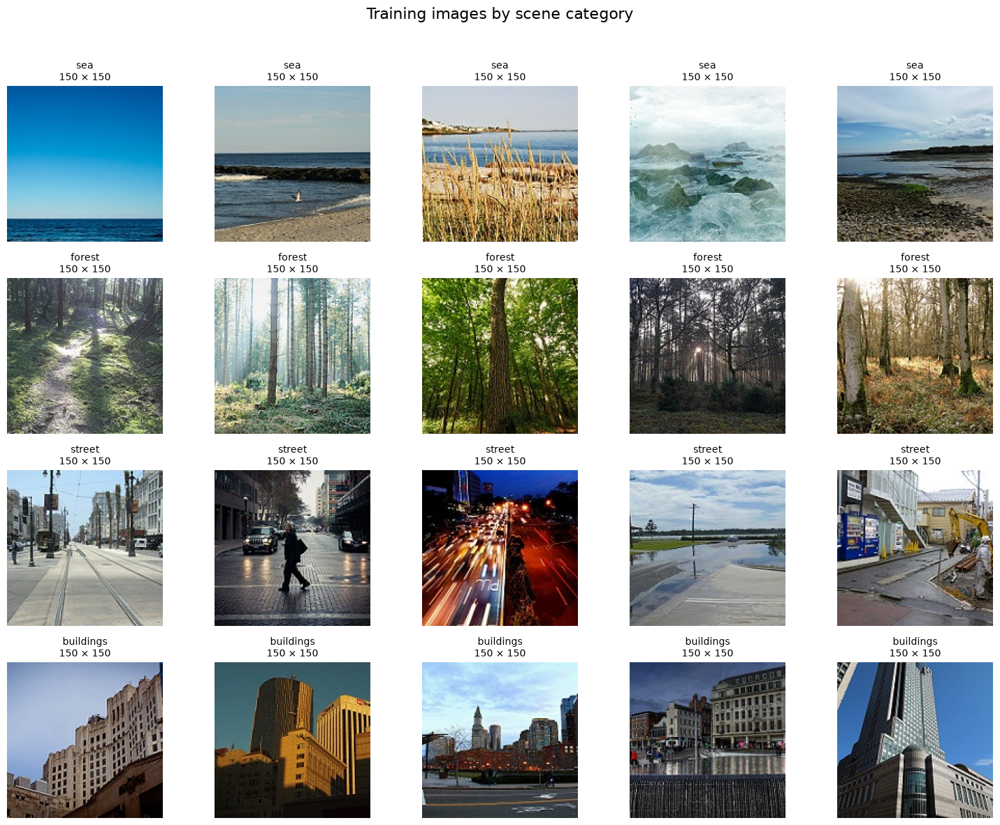

In [9]:
import random
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42
EXAMPLES_PER_CLASS = 5

# Use a local random generator for reproducible visualization.
rng = random.Random(SEED)

fig, axes = plt.subplots(
    nrows=len(SELECTED_CLASSES),
    ncols=EXAMPLES_PER_CLASS,
    figsize=(15, 12),
    squeeze=False,
)

for row, class_name in enumerate(SELECTED_CLASSES):
    image_paths = sorted(
        path
        for path in (TRAIN_DIR / class_name).iterdir()
        if path.is_file()
        and path.suffix.lower() in IMAGE_EXTENSIONS
    )

    selected_paths = rng.sample(image_paths, EXAMPLES_PER_CLASS)

    for col, image_path in enumerate(selected_paths):
        with Image.open(image_path) as image:
            image = image.convert("RGB")
            axes[row, col].imshow(image)
            axes[row, col].set_title(
                f"{class_name}\n{image.width} × {image.height}",
                fontsize=10,
            )

        axes[row, col].axis("off")

fig.suptitle("Training images by scene category", fontsize=16)
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

## Reproducible dataset splits

For each category, select 500 training images and 100 validation images
from disjoint subsets of seg_train. Select another 100 test images
from seg_test.

Split images before generating masks to prevent the same source image
from appearing in both training and validation. Save relative file paths
as manifests without copying the images.

In [10]:
import pandas as pd
from sklearn.model_selection import train_test_split

SEED = 42

train_rows, val_rows, test_rows = [], [], []

for category in SELECTED_CLASSES:
    train_files = sorted((TRAIN_DIR / category).glob("*.jpg"))
    test_files = sorted((TEST_DIR / category).glob("*.jpg"))

    train_paths, val_paths = train_test_split(
        train_files,
        train_size=500,
        test_size=100,
        random_state=SEED,
    )

    test_paths = pd.Series(test_files).sample(n=100, random_state=SEED)

    train_rows.extend((path, category) for path in train_paths)
    val_rows.extend((path, category) for path in val_paths)
    test_rows.extend((path, category) for path in test_paths)

train_df = pd.DataFrame(train_rows, columns=["path", "category"])
val_df = pd.DataFrame(val_rows, columns=["path", "category"])
test_df = pd.DataFrame(test_rows, columns=["path", "category"])

pd.DataFrame({
    "train": train_df["category"].value_counts(),
    "validation": val_df["category"].value_counts(),
    "test": test_df["category"].value_counts(),
})

,train,validation,test
category,,,
sea,500,100,100
forest,500,100,100
street,500,100,100
buildings,500,100,100


In [11]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16


def load_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    return tf.image.resize(image, IMAGE_SIZE)


train_ds = (
    tf.data.Dataset.from_tensor_slices(train_df["path"].astype(str).tolist())
    .shuffle(len(train_df), seed=SEED)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices(val_df["path"].astype(str).tolist())
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_ds = (
    tf.data.Dataset.from_tensor_slices(test_df["path"].astype(str).tolist())
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

# mask creation and hide random areas of the photos

In [12]:
import numpy as np
from PIL import Image, ImageDraw


def create_mask(rng):
    mask = Image.new("L", IMAGE_SIZE, 0)
    brush = ImageDraw.Draw(mask)
    width, height = mask.size

    for _ in range(rng.integers(1, 4)):
        x, y = rng.integers(0, width), rng.integers(0, height)
        thickness = int(rng.integers(6, 17))

        for _ in range(rng.integers(2, 5)):
            next_x = int(np.clip(x + rng.integers(-30, 31), 0, width - 1))
            next_y = int(np.clip(y + rng.integers(-30, 31), 0, height - 1))

            brush.line(
                [(int(x), int(y)), (next_x, next_y)],
                fill=255,
                width=thickness,
            )
            x, y = next_x, next_y

    return np.asarray(mask, dtype=np.float32)[..., None] / 255.0

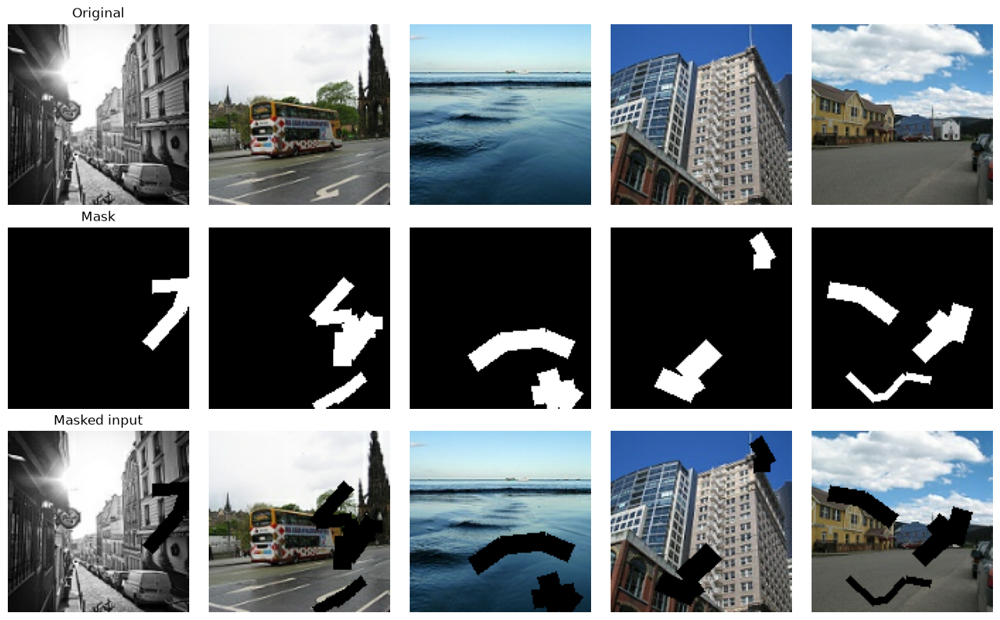

Model input shape: (5, 128, 128, 4)


In [14]:
rng = np.random.default_rng(SEED)

images = next(iter(train_ds))
originals = images[:5].numpy()
masks = np.stack([create_mask(rng) for _ in originals])
masked_images = originals * (1 - masks)

# Model input: three RGB channels plus one mask channel.
model_inputs = np.concatenate([masked_images, masks], axis=-1)

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for i in range(5):
    axes[0, i].imshow(originals[i])
    axes[1, i].imshow(masks[i, ..., 0], cmap="gray", vmin=0, vmax=1)
    axes[2, i].imshow(masked_images[i])

    for ax in axes[:, i]:
        ax.axis("off")

for row, title in enumerate(["Original", "Mask", "Masked input"]):
    axes[row, 0].set_title(title)

plt.tight_layout()
plt.show()

print("Model input shape:", model_inputs.shape)

In [15]:
train_rng = np.random.default_rng(SEED)


def prepare_batch(index, batch, training=False):
    def generate_masks(batch_size, batch_index):
        rng = (
            train_rng
            if training
            else np.random.default_rng(SEED + int(batch_index))
        )
        return np.stack([
            create_mask(rng) for _ in range(int(batch_size))
        ])

    masks = tf.numpy_function(
        generate_masks,
        [tf.shape(batch)[0], index],
        tf.float32,
    )
    masks.set_shape((None, *IMAGE_SIZE, 1))

    masked_images = batch * (1 - masks)
    inputs = tf.concat([masked_images, masks], axis=-1)

    # Keep the mask with the target to calculate masked MAE later.
    targets = tf.concat([batch, masks], axis=-1)

    return inputs, targets


train_ready = train_ds.enumerate().map(
    lambda index, batch: prepare_batch(index, batch, training=True)
)

val_ready = val_ds.enumerate().map(
    lambda index, batch: prepare_batch(index, batch)
)

test_ready = test_ds.enumerate().map(
    lambda index, batch: prepare_batch(index, batch)
)

In [16]:
inputs, targets = next(iter(train_ready))

print("Inputs:", inputs.shape)
print("Targets:", targets.shape)

Inputs: (16, 128, 128, 4)
Targets: (16, 128, 128, 4)


In [18]:
# loss function: 
def masked_mae(y_true, y_pred):
    original = y_true[..., :3]
    mask = y_true[..., 3:]

    error = tf.abs(original - y_pred) * mask

    return tf.math.divide_no_nan(
        tf.reduce_sum(error),
        3.0 * tf.reduce_sum(mask),
    )

In [19]:
with tf.device(TRAINING_DEVICE):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 4))

    # Encoder: 128 → 64 → 32
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(inputs)
    x = layers.Conv2D(
        64, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = layers.Conv2D(
        128, 3, strides=2, padding="same", activation="relu"
    )(x)
    x = layers.Dropout(0.2)(x)

    # Decoder: 32 → 64 → 128
    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)
    x = layers.UpSampling2D()(x)
    x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

    outputs = layers.Conv2D(
        3, 1, padding="same", activation="sigmoid"
    )(x)

    model = keras.Model(inputs, outputs, name="photo_retouch_autoencoder")

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=masked_mae,
        jit_compile=False,
    )

model.summary()

Model: "photo_retouch_autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 128, 128, 4)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │         1,184 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 64, 64, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 128, 128, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 3)    │            99 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 185,891 (726.14 KB)

 Trainable params: 185,891 (726.14 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
import os
import time
import psutil

process = psutil.Process(os.getpid())
memory_before = process.memory_info().rss / 1024**3
start = time.perf_counter()

with tf.device(TRAINING_DEVICE):
    history = model.fit(
        train_ready,
        validation_data=val_ready,
        epochs=1,
    )

elapsed = time.perf_counter() - start
memory_after = process.memory_info().rss / 1024**3

print(f"Training device: {TRAINING_DEVICE}")
print(f"Elapsed time: {elapsed:.1f} seconds")
print(f"Process RAM before: {memory_before:.2f} GB")
print(f"Process RAM after: {memory_after:.2f} GB")

/Users/mateocordoba/dev/projects/photo-retouch/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
2026-11-16 13:40:28.856201: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 505ms/step - loss: 0.1609 - val_loss: 0.1273
Training device: /GPU:0
Elapsed time: 65.2 seconds
Process RAM before: 0.07 GB
Process RAM after: 0.54 GB


In [21]:
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

training_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_autoencoder.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

with tf.device(TRAINING_DEVICE):
    history_more = model.fit(
        train_ready,
        validation_data=val_ready,
        initial_epoch=1,
        epochs=20,
        shuffle=False,
        callbacks=training_callbacks,
    )

Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 531ms/step - loss: 0.1187 - val_loss: 0.1166
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 536ms/step - loss: 0.1117 - val_loss: 0.1086
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 535ms/step - loss: 0.1071 - val_loss: 0.1073
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 516ms/step - loss: 0.1052 - val_loss: 0.1038
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 513ms/step - loss: 0.1041 - val_loss: 0.1019
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.1019 - val_loss: 0.1007
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.1016 - val_loss: 0.1012
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.1011 - val_loss: 0.1005
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.1002 - val_loss: 0.0987
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 405s 3s/step - loss: 0.0997 - val_loss: 0.1012
Epoch 12/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 520ms/step - loss: 0.0989 - val_loss: 0.0977
Epoch 13/20
125/125 

In [22]:
import cv2

best_model = keras.models.load_model(
    MODEL_DIR / "best_autoencoder.keras",
    compile=False,
)

inputs, targets = next(iter(val_ready))

originals = targets[:5, ..., :3].numpy()
masks = targets[:5, ..., 3:].numpy()
masked_images = inputs[:5, ..., :3].numpy()

predictions = best_model.predict(inputs[:5], verbose=0)

# Replace only the masked pixels.
reconstructed = originals * (1 - masks) + predictions * masks

opencv_results = []

for image, mask in zip(masked_images, masks):
    image_uint8 = np.round(image * 255).astype(np.uint8)
    mask_uint8 = (mask[..., 0] * 255).astype(np.uint8)

    filled = cv2.inpaint(
        image_uint8,
        mask_uint8,
        inpaintRadius=3,
        flags=cv2.INPAINT_TELEA,
    )

    opencv_results.append(filled.astype(np.float32) / 255)

opencv_results = np.stack(opencv_results)

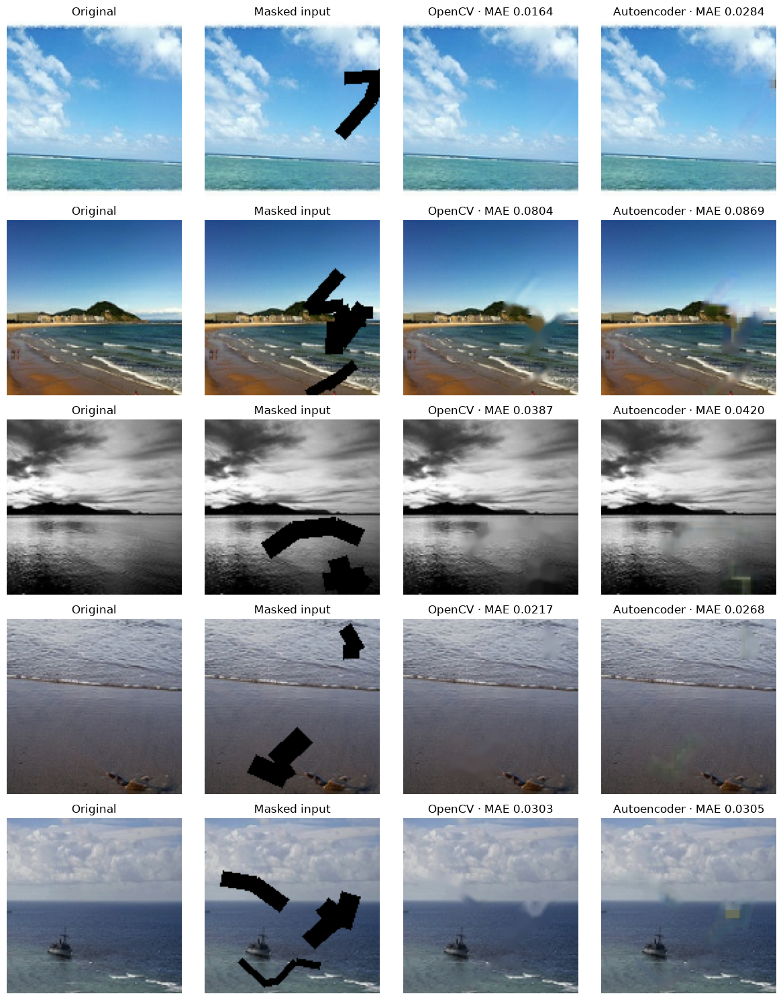

In [23]:
fig, axes = plt.subplots(5, 4, figsize=(12, 15))

for i in range(5):
    model_error = (
        np.abs(originals[i] - reconstructed[i]) * masks[i]
    ).sum() / (3 * masks[i].sum())

    opencv_error = (
        np.abs(originals[i] - opencv_results[i]) * masks[i]
    ).sum() / (3 * masks[i].sum())

    panels = [
        (originals[i], "Original"),
        (masked_images[i], "Masked input"),
        (opencv_results[i], f"OpenCV · MAE {opencv_error:.4f}"),
        (reconstructed[i], f"Autoencoder · MAE {model_error:.4f}"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

In [24]:
results = []

for inputs, targets in val_ready:
    predictions = best_model.predict(inputs, verbose=0)

    for input_image, target, prediction in zip(
        inputs.numpy(), targets.numpy(), predictions
    ):
        original = target[..., :3]
        mask = target[..., 3:]

        opencv_result = cv2.inpaint(
            np.round(input_image[..., :3] * 255).astype(np.uint8),
            (mask[..., 0] * 255).astype(np.uint8),
            inpaintRadius=3,
            flags=cv2.INPAINT_TELEA,
        ).astype(np.float32) / 255

        results.append({
            "autoencoder_mae": (
                np.abs(original - prediction) * mask
            ).sum() / (3 * mask.sum()),
            "opencv_mae": (
                np.abs(original - opencv_result) * mask
            ).sum() / (3 * mask.sum()),
        })

validation_results = pd.DataFrame(results)

# val_ready preserves the order of val_df.
validation_results["category"] = val_df["category"].to_numpy()

display(
    validation_results.groupby("category")[
        ["autoencoder_mae", "opencv_mae"]
    ].mean()
)

2026-11-16 14:31:48.060436: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,autoencoder_mae,opencv_mae
category,,
buildings,0.103797,0.098552
forest,0.101440,0.098258
sea,0.066944,0.059036
street,0.093319,0.088444


In [25]:
fine_model = keras.models.load_model(
    MODEL_DIR / "best_autoencoder.keras",
    compile=False,
)

fine_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=masked_mae,
    jit_compile=False,
)

fine_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "autoencoder_low_lr.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

with tf.device(TRAINING_DEVICE):
    history_fine = fine_model.fit(
        train_ready,
        validation_data=val_ready,
        epochs=10,
        shuffle=False,
        callbacks=fine_callbacks,
    )

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 506ms/step - loss: 0.0945 - val_loss: 0.0934
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 515ms/step - loss: 0.0942 - val_loss: 0.0934
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 527ms/step - loss: 0.0944 - val_loss: 0.0934
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 528ms/step - loss: 0.0929 - val_loss: 0.0930
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 515ms/step - loss: 0.0943 - val_loss: 0.0930
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.0938 - val_loss: 0.0929
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.0934 - val_loss: 0.0927
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.0925 - val_loss: 0.0928
Epoch 9/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 515ms/step - loss: 0.0943 - val_loss: 0.0926
Epoch 10/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 64s 514ms/step - loss: 0.0935 - val_loss: 0.0928


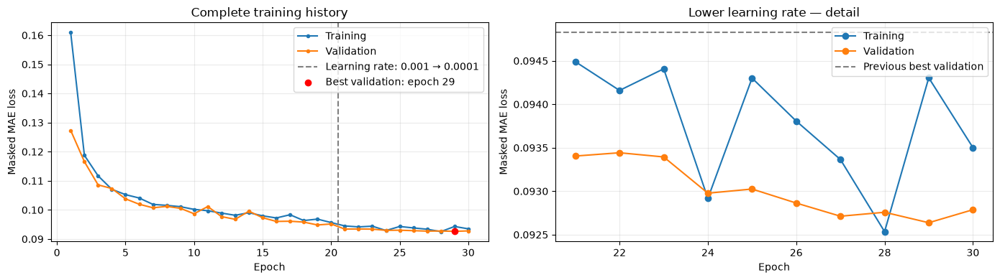

In [26]:
initial_loss = history.history["loss"] + history_more.history["loss"]
initial_val_loss = history.history["val_loss"] + history_more.history["val_loss"]

all_loss = initial_loss + history_fine.history["loss"]
all_val_loss = initial_val_loss + history_fine.history["val_loss"]

epochs = np.arange(1, len(all_loss) + 1)
fine_start = len(initial_loss)
best_epoch = int(np.argmin(all_val_loss)) + 1

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Full training history.
axes[0].plot(epochs, all_loss, label="Training", marker=".")
axes[0].plot(epochs, all_val_loss, label="Validation", marker=".")
axes[0].axvline(
    fine_start + 0.5,
    color="gray",
    linestyle="--",
    label="Learning rate: 0.001 → 0.0001",
)
axes[0].scatter(
    best_epoch,
    min(all_val_loss),
    color="red",
    zorder=5,
    label=f"Best validation: epoch {best_epoch}",
)
axes[0].set_title("Complete training history")

# Detailed view of the lower-learning-rate stage.
fine_epochs = epochs[fine_start:]

axes[1].plot(
    fine_epochs, history_fine.history["loss"],
    label="Training", marker="o",
)
axes[1].plot(
    fine_epochs, history_fine.history["val_loss"],
    label="Validation", marker="o",
)
axes[1].axhline(
    min(initial_val_loss),
    color="gray",
    linestyle="--",
    label="Previous best validation",
)
axes[1].set_title("Lower learning rate — detail")

for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Masked MAE loss")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.show()

In [27]:
base_model = keras.models.load_model(
    MODEL_DIR / "best_autoencoder.keras",
    compile=False,
)

tuned_model = keras.models.load_model(
    MODEL_DIR / "autoencoder_low_lr.keras",
    compile=False,
)

results = []

for inputs, targets in val_ready:
    base_predictions = base_model.predict(inputs, verbose=0)
    tuned_predictions = tuned_model.predict(inputs, verbose=0)

    for input_image, target, base, tuned in zip(
        inputs.numpy(), targets.numpy(),
        base_predictions, tuned_predictions,
    ):
        original = target[..., :3]
        mask = target[..., 3:]

        opencv = cv2.inpaint(
            np.round(input_image[..., :3] * 255).astype(np.uint8),
            (mask[..., 0] * 255).astype(np.uint8),
            inpaintRadius=3,
            flags=cv2.INPAINT_TELEA,
        ).astype(np.float32) / 255

        results.append({
            name: (np.abs(original - prediction) * mask).sum()
            / (3 * mask.sum())
            for name, prediction in [
                ("Base autoencoder", base),
                ("Tuned autoencoder", tuned),
                ("OpenCV", opencv),
            ]
        })

comparison = pd.DataFrame(results)
comparison["category"] = val_df["category"].to_numpy()

summary = comparison.groupby("category").mean()
summary.loc["Overall"] = comparison.drop(columns="category").mean()

display(summary)

2026-11-16 14:59:35.748340: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,Base autoencoder,Tuned autoencoder,OpenCV
category,,,
buildings,0.103797,0.101525,0.098552
forest,0.101440,0.100038,0.098258
sea,0.066944,0.063915,0.059036
street,0.093319,0.091261,0.088444
Overall,0.091375,0.089185,0.086073


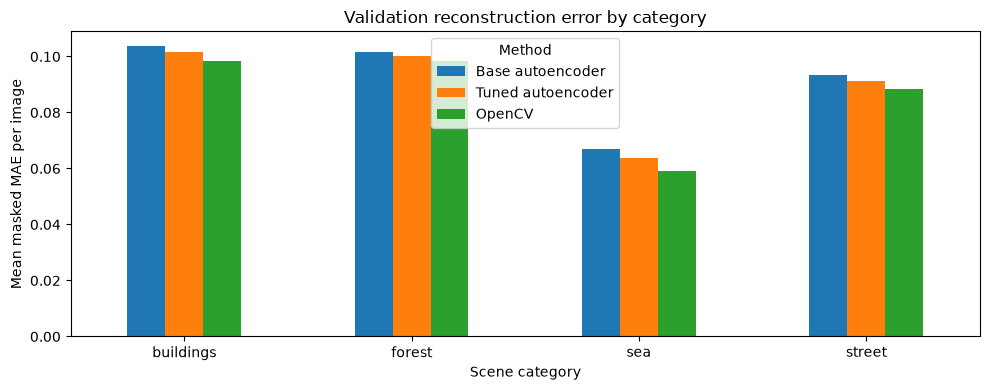

In [28]:
summary.drop(index="Overall").plot.bar(
    figsize=(10, 4),
    rot=0,
)

plt.title("Validation reconstruction error by category")
plt.xlabel("Scene category")
plt.ylabel("Mean masked MAE per image")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

### Learning-rate adjustment results

Reducing the learning rate from 0.001 to 0.0001 and training for ten
additional epochs reduced the mean per-image validation MAE from
0.091375 to 0.089185, an improvement of approximately 2.4%.

All four scene categories improved. However, OpenCV achieved the
lowest average MAE in every category, with an overall value of
0.086073. The tuned autoencoder's error remained approximately
3.6% higher.

This experiment evaluates the combined effect of additional training
and a lower learning rate; it does not isolate the learning-rate
change alone. Results apply to the selected validation images and
synthetic masks.

In [29]:
with tf.device(TRAINING_DEVICE):
    inputs = keras.Input(shape=(*IMAGE_SIZE, 4))

    # Encoder
    skip1 = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(inputs)

    skip2 = layers.Conv2D(
        64, 3, strides=2, padding="same", activation="relu"
    )(skip1)

    # Bottleneck
    x = layers.Conv2D(
        128, 3, strides=2, padding="same", activation="relu"
    )(skip2)
    x = layers.Dropout(0.2)(x)

    # Decoder with skip connections
    x = layers.UpSampling2D()(x)
    x = layers.Concatenate()([x, skip2])
    x = layers.Conv2D(
        64, 3, padding="same", activation="relu"
    )(x)

    x = layers.UpSampling2D()(x)
    x = layers.Concatenate()([x, skip1])
    x = layers.Conv2D(
        32, 3, padding="same", activation="relu"
    )(x)

    outputs = layers.Conv2D(
        3, 1, activation="sigmoid"
    )(x)

    unet_model = keras.Model(inputs, outputs, name="photo_retouch_unet")

    unet_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss=masked_mae,
        jit_compile=False,
    )

unet_model.summary()

Model: "photo_retouch_unet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 128, 128,  │      1,184 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 64, 64,    │     18,496 │ conv2d_6[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │     73,856 │ conv2d_7[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 32, 32,    │          0 │ conv2d_8[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 64, 64,    │          0 │ dropout_1[0][0]   │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d_2[… │
│ (Concatenate)       │ 192)              │            │ conv2d_7[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_3     │ (None, 128, 128,  │          0 │ conv2d_9[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_3[… │
│ (Concatenate)       │ 96)               │            │ conv2d_6[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │         99 │ conv2d_10[0][0]   │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 231,971 (906.14 KB)

 Trainable params: 231,971 (906.14 KB)

 Non-trainable params: 0 (0.00 B)

In [30]:
unet_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_unet.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

with tf.device(TRAINING_DEVICE):
    history_unet = unet_model.fit(
        train_ready,
        validation_data=val_ready,
        epochs=20,
        shuffle=False,
        callbacks=unet_callbacks,
    )

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 531ms/step - loss: 0.1607 - val_loss: 0.1233
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 524ms/step - loss: 0.1151 - val_loss: 0.1075
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 524ms/step - loss: 0.1098 - val_loss: 0.1055
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.1039 - val_loss: 0.1029
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 524ms/step - loss: 0.0999 - val_loss: 0.1033
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.0998 - val_loss: 0.0979
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.0991 - val_loss: 0.0980
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 526ms/step - loss: 0.0982 - val_loss: 0.0975
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.0968 - val_loss: 0.0976
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.0973 - val_loss: 0.0962
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 526ms/step - loss: 0.0963 - val_loss: 0.0943
Epoch 12/20
125/125

In [31]:
best_unet = keras.models.load_model(
    MODEL_DIR / "best_unet.keras",
    compile=False,
)

unet_errors = []

for inputs, targets in val_ready:
    predictions = best_unet.predict(inputs, verbose=0)

    originals = targets[..., :3].numpy()
    masks = targets[..., 3:].numpy()

    errors = (
        np.abs(originals - predictions) * masks
    ).sum(axis=(1, 2, 3)) / (
        3 * masks.sum(axis=(1, 2, 3))
    )

    unet_errors.extend(errors)

comparison["U-Net"] = unet_errors

summary = comparison.groupby("category").mean()
summary.loc["Overall"] = comparison.drop(columns="category").mean()

display(summary)

,Base autoencoder,Tuned autoencoder,OpenCV,U-Net
category,,,,
buildings,0.103797,0.101525,0.098552,0.099996
forest,0.101440,0.100038,0.098258,0.097165
sea,0.066944,0.063915,0.059036,0.063397
street,0.093319,0.091261,0.088444,0.089419
Overall,0.091375,0.089185,0.086073,0.087494


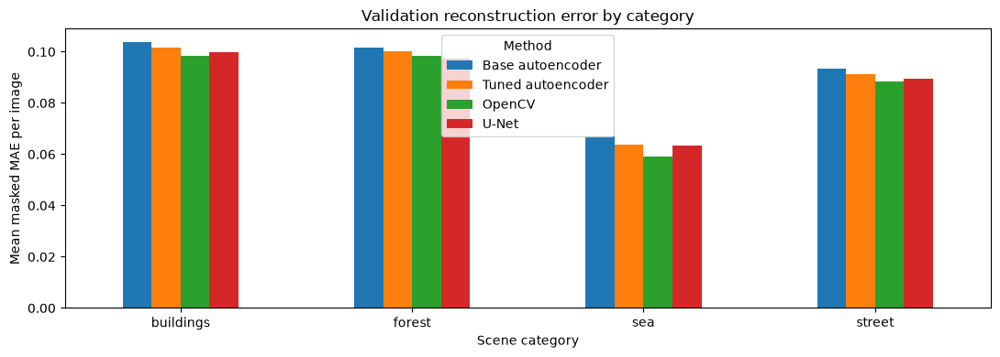

In [32]:
summary.drop(index="Overall").plot.bar(
    figsize=(11, 4),
    rot=0,
)

plt.title("Validation reconstruction error by category")
plt.xlabel("Scene category")
plt.ylabel("Mean masked MAE per image")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

In [33]:
# Select one validation example per category.
example_indices = [
    val_df.index[val_df["category"] == category][0]
    for category in SELECTED_CLASSES
]

examples = [
    (inputs.numpy(), targets.numpy())
    for i, (inputs, targets) in enumerate(val_ready.unbatch())
    if i in example_indices
]

sample_inputs = np.stack([inputs for inputs, _ in examples])
sample_targets = np.stack([targets for _, targets in examples])

originals = sample_targets[..., :3]
masks = sample_targets[..., 3:]

tuned_predictions = tuned_model.predict(sample_inputs, verbose=0)
unet_predictions = best_unet.predict(sample_inputs, verbose=0)

tuned_results = originals * (1 - masks) + tuned_predictions * masks
unet_results = originals * (1 - masks) + unet_predictions * masks

opencv_results = np.stack([
    cv2.inpaint(
        np.round(image[..., :3] * 255).astype(np.uint8),
        (mask[..., 0] * 255).astype(np.uint8),
        inpaintRadius=3,
        flags=cv2.INPAINT_TELEA,
    ).astype(np.float32) / 255
    for image, mask in zip(sample_inputs, masks)
])

2026-11-16 16:05:15.981749: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


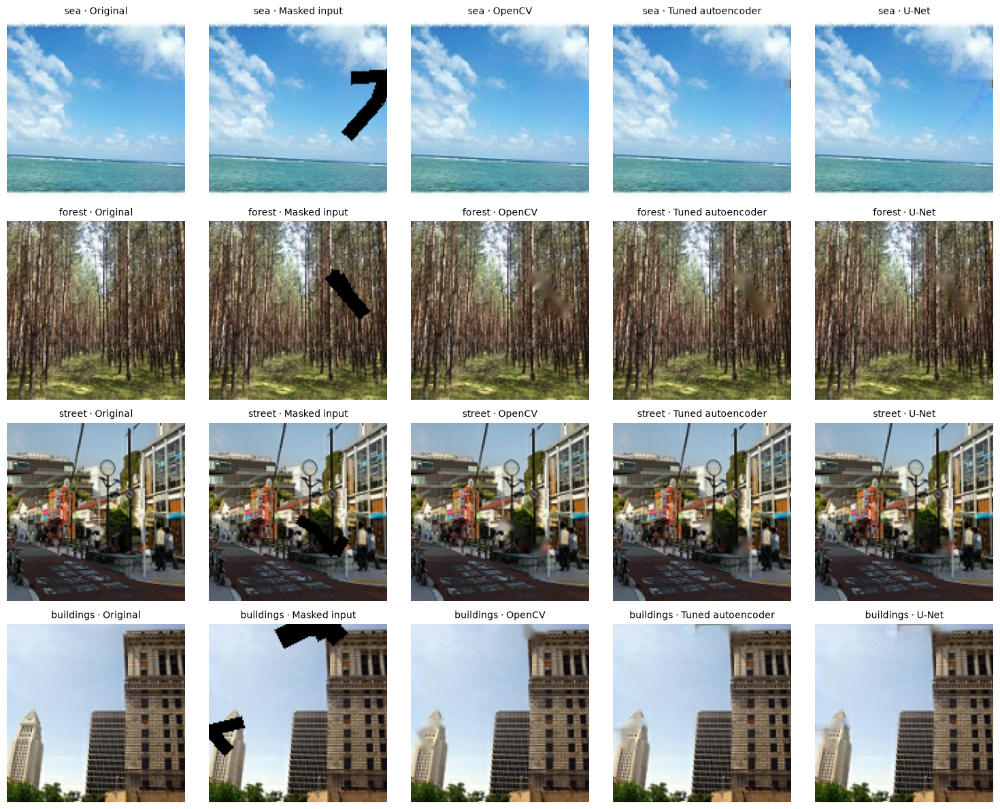

In [34]:
panels = [
    ("Original", originals),
    ("Masked input", sample_inputs[..., :3]),
    ("OpenCV", opencv_results),
    ("Tuned autoencoder", tuned_results),
    ("U-Net", unet_results),
]

fig, axes = plt.subplots(4, 5, figsize=(15, 12))

for row, category in enumerate(SELECTED_CLASSES):
    for col, (title, images) in enumerate(panels):
        ax = axes[row, col]
        ax.imshow(images[row])
        ax.set_title(f"{category} · {title}", fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Architecture comparison

The U-Net achieved the lowest mean per-image validation MAE among
the trained neural models: 0.087494. This represents a reduction
of approximately 4.2% relative to the base autoencoder and 1.9%
relative to the tuned autoencoder.

OpenCV remained the strongest method overall, with a mean MAE
of 0.086073. However, U-Net achieved a slightly lower average error
in the forest category.

Visual inspection still reveals blurred textures, color differences,
and incomplete reconstruction of fine structures. Lower average
pixel error does not guarantee a seamless result for every image.

These results describe one training run per configuration on the
selected validation set; they do not establish statistical significance.

#

2026-11-16 20:18:40.590249: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M5
2026-11-16 20:18:40.590274: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-11-16 20:18:40.590276: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
I0000 00:00:1794878320.590594 25511533 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1794878320.590630 25511533 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)
2026-11-16 20:18:41.315865: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


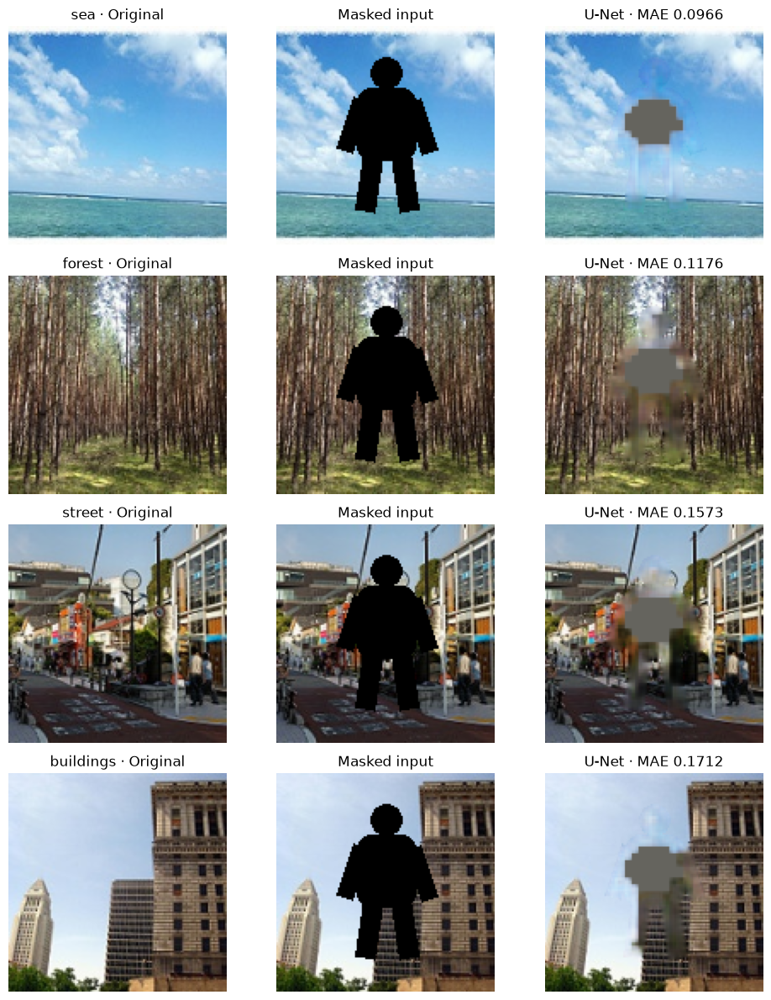

Masked area: 17.8%


In [5]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from tensorflow import keras

PROJECT_ROOT = Path.home() / "dev/projects/photo-retouch"
DATA_DIR = PROJECT_ROOT / "data/intel-image-classification"
CATEGORIES = ["sea", "forest", "street", "buildings"]

best_unet = keras.models.load_model(
    PROJECT_ROOT / "models/best_unet.keras",
    compile=False,
)

# Locate the training folder and reproduce the validation selection.
from sklearn.model_selection import train_test_split

train_dir = next(
    folder for folder in DATA_DIR.rglob("seg_train")
    if (folder / "sea").is_dir()
)

originals = []

for category in CATEGORIES:
    files = sorted((train_dir / category).glob("*.jpg"))

    _, val_files = train_test_split(
        files,
        train_size=500,
        test_size=100,
        random_state=42,
    )

    with Image.open(val_files[0]) as image:
        image = np.asarray(image.convert("RGB"), dtype=np.float32) / 255

    # Match the resizing used during training.
    from tensorflow import image as tf_image
    originals.append(tf_image.resize(image, (128, 128)).numpy())

originals = np.stack(originals)

# Create a synthetic silhouette.
mask_image = Image.new("L", (128, 128), 0)
brush = ImageDraw.Draw(mask_image)

brush.ellipse((55, 18, 73, 36), fill=255)
brush.rounded_rectangle((47, 36, 81, 78), radius=8, fill=255)
brush.line([(49, 43), (39, 73)], fill=255, width=10)
brush.line([(79, 43), (89, 73)], fill=255, width=10)
brush.line([(56, 74), (51, 108)], fill=255, width=12)
brush.line([(72, 74), (77, 108)], fill=255, width=12)

mask = np.asarray(mask_image, dtype=np.float32)[..., None] / 255
masks = np.repeat(mask[None], len(originals), axis=0)

masked_images = originals * (1 - masks)
inputs = np.concatenate([masked_images, masks], axis=-1)

predictions = best_unet.predict(inputs, verbose=0)
results = originals * (1 - masks) + predictions * masks

# Display the results.
fig, axes = plt.subplots(4, 3, figsize=(10, 12))

for i, category in enumerate(CATEGORIES):
    error = (
        np.abs(originals[i] - results[i]) * mask
    ).sum() / (3 * mask.sum())

    panels = [
        (originals[i], f"{category} · Original"),
        (masked_images[i], "Masked input"),
        (results[i], f"U-Net · MAE {error:.4f}"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

print(f"Masked area: {mask.mean():.1%}")

## Experiment: Mixed Training Masks

The current U-Net produces visible artifacts when reconstructing wide,
person-shaped holes. Its original training masks consisted mainly of
brush-like strokes.

In this experiment, we introduce three mask types:
- Irregular strokes.
- Compact blocks.
- Synthetic silhouettes with varying sizes and positions.

The goal is to expose the model to a wider range of missing regions.
We will keep the original validation masks unchanged and evaluate large
masks separately to compare performance on both types of reconstruction.

In [6]:
def create_mixed_mask(rng):
    mask = Image.new("L", (128, 128), 0)
    brush = ImageDraw.Draw(mask)
    kind = rng.choice(["strokes", "block", "silhouette"])

    if kind == "strokes":
        for _ in range(rng.integers(1, 4)):
            points = rng.integers(0, 128, size=(3, 2))
            brush.line(
                [tuple(map(int, point)) for point in points],
                fill=255,
                width=int(rng.integers(6, 18)),
            )

    else:
        width = int(rng.integers(24, 55))
        height = int(rng.integers(45, 105))
        x = int(rng.integers(0, 129 - width))
        y = int(rng.integers(0, 129 - height))

        if kind == "block":
            brush.rounded_rectangle(
                (x, y, x + width - 1, y + height - 1),
                radius=8,
                fill=255,
            )

        else:
            silhouette = Image.new("L", (64, 128), 0)
            body = ImageDraw.Draw(silhouette)

            body.ellipse((23, 0, 41, 22), fill=255)
            body.rounded_rectangle((15, 22, 49, 80), radius=8, fill=255)
            body.line([(17, 30), (5, 77)], fill=255, width=10)
            body.line([(47, 30), (59, 77)], fill=255, width=10)
            body.line([(24, 75), (20, 127)], fill=255, width=13)
            body.line([(40, 75), (44, 127)], fill=255, width=13)

            silhouette = silhouette.resize(
                (width, height),
                Image.Resampling.NEAREST,
            )
            mask.paste(silhouette, (x, y))

    return np.asarray(mask, dtype=np.float32)[..., None] / 255

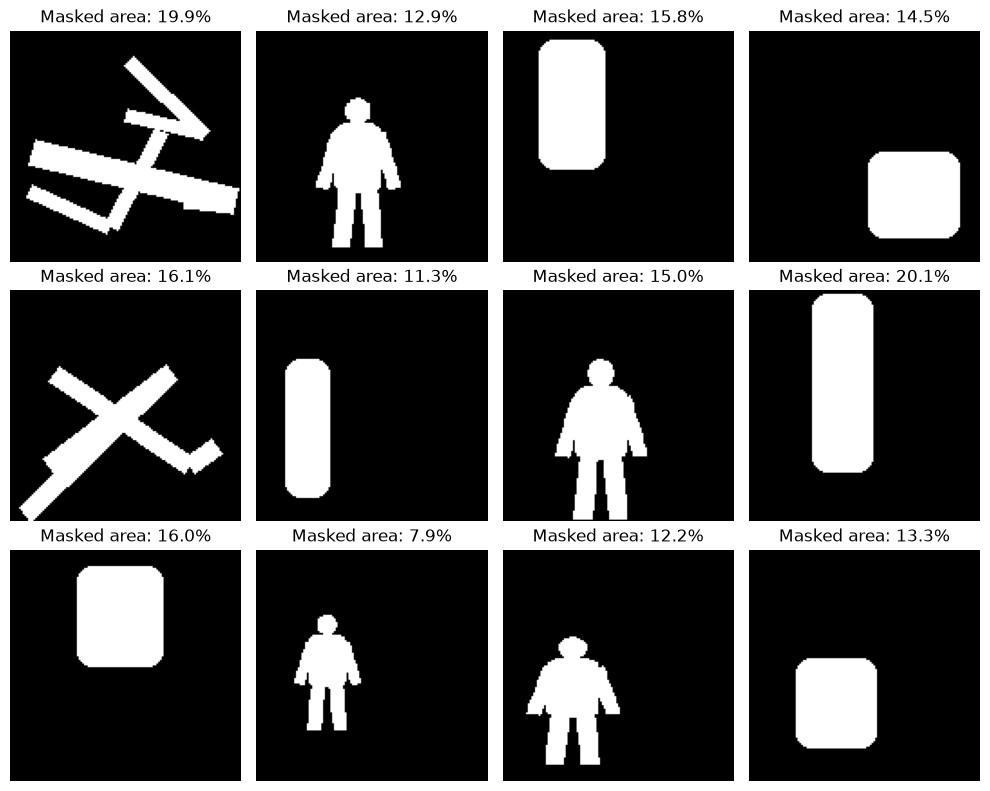

In [7]:
rng = np.random.default_rng(42)

fig, axes = plt.subplots(3, 4, figsize=(10, 8))

for ax in axes.flat:
    mask = create_mixed_mask(rng)
    ax.imshow(mask[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Masked area: {mask.mean():.1%}")
    ax.axis("off")

plt.tight_layout()
plt.show()

### Build the Mixed-Mask Data Pipelines

Apply mixed masks to the existing image splits without changing which
images belong to training and validation.

Training masks vary across iterations. A separate validation pipeline
uses reproducible mixed masks. The original validation pipeline remains
available for comparison.

Inputs contain masked RGB images and a binary mask channel. Targets
contain the original RGB images and the mask used by the loss function.

In [9]:
from pathlib import Path

import tensorflow as tf
from sklearn.model_selection import train_test_split

PROJECT_ROOT = Path.home() / "dev/projects/photo-retouch"
DATA_DIR = PROJECT_ROOT / "data/intel-image-classification"
MODEL_DIR = PROJECT_ROOT / "models"

SELECTED_CLASSES = ["sea", "forest", "street", "buildings"]
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 16
SEED = 42

train_dir = next(
    folder for folder in DATA_DIR.rglob("seg_train")
    if (folder / "sea").is_dir()
)

train_paths, val_paths = [], []

for category in SELECTED_CLASSES:
    files = sorted((train_dir / category).glob("*.jpg"))

    train_files, val_files = train_test_split(
        files,
        train_size=500,
        test_size=100,
        random_state=SEED,
    )

    train_paths.extend(str(path) for path in train_files)
    val_paths.extend(str(path) for path in val_files)


def load_image(path):
    image = tf.io.read_file(path)
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    return tf.image.resize(image, IMAGE_SIZE)


train_ds = (
    tf.data.Dataset.from_tensor_slices(train_paths)
    .shuffle(len(train_paths), seed=SEED)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    tf.data.Dataset.from_tensor_slices(val_paths)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

In [10]:
mixed_train_rng = np.random.default_rng(42)


def prepare_mixed_batch(index, batch, training=False):
    def generate_masks(batch_size, batch_index):
        rng = (
            mixed_train_rng
            if training
            else np.random.default_rng(1000 + int(batch_index))
        )

        return np.stack([
            create_mixed_mask(rng)
            for _ in range(int(batch_size))
        ])

    masks = tf.numpy_function(
        generate_masks,
        [tf.shape(batch)[0], index],
        tf.float32,
    )
    masks.set_shape((None, 128, 128, 1))

    inputs = tf.concat([batch * (1 - masks), masks], axis=-1)
    targets = tf.concat([batch, masks], axis=-1)

    return inputs, targets


train_mixed = train_ds.enumerate().map(
    lambda index, batch: prepare_mixed_batch(
        index, batch, training=True
    )
)

val_mixed = val_ds.enumerate().map(
    lambda index, batch: prepare_mixed_batch(index, batch)
)

### Inspect a Mixed-Mask Training Batch

Display clean images, masked inputs, and binary masks to verify their
alignment before training. The model must reconstruct the white regions
of each mask using the surrounding visible context.

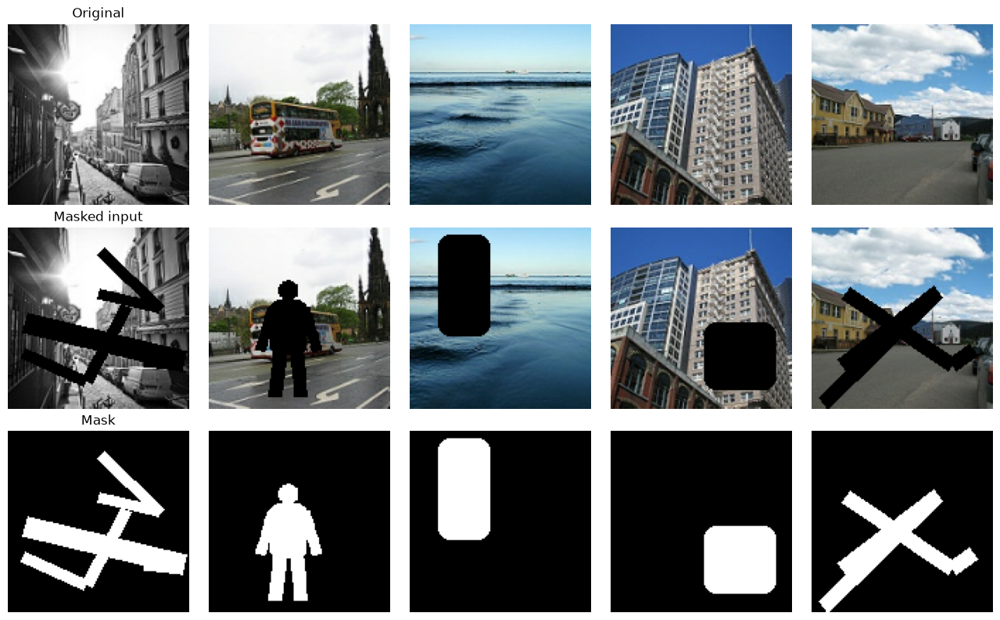

In [11]:
mixed_inputs, mixed_targets = next(iter(train_mixed))

fig, axes = plt.subplots(3, 5, figsize=(13, 8))

for i in range(5):
    axes[0, i].imshow(mixed_targets[i, ..., :3].numpy())
    axes[1, i].imshow(mixed_inputs[i, ..., :3].numpy())
    axes[2, i].imshow(
        mixed_targets[i, ..., 3].numpy(),
        cmap="gray",
        vmin=0,
        vmax=1,
    )

    for ax in axes[:, i]:
        ax.axis("off")

for row, title in enumerate(["Original", "Masked input", "Mask"]):
    axes[row, 0].set_title(title)

plt.tight_layout()
plt.show()

### Fine-Tune U-Net with Mixed Masks

Load the previously trained U-Net and continue training with a mixture
of strokes, blocks, and synthetic silhouettes.

First, measure its loss on the fixed mixed-mask validation set.
Then train for up to ten additional epochs with a lower learning rate,
saving the best checkpoint in a separate file.

This experiment evaluates adaptation through additional training with
new masks. Improvements must later be checked on both the original
and mixed-mask validation sets.

In [12]:
from tensorflow import keras


def masked_mae(y_true, y_pred):
    original = y_true[..., :3]
    mask = y_true[..., 3:]

    return tf.math.divide_no_nan(
        tf.reduce_sum(tf.abs(original - y_pred) * mask),
        3.0 * tf.reduce_sum(mask),
    )


mixed_model = keras.models.load_model(
    MODEL_DIR / "best_unet.keras",
    compile=False,
)

mixed_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=masked_mae,
    jit_compile=False,
)

baseline_mixed_loss = mixed_model.evaluate(val_mixed, verbose=0)
print(f"Mixed-mask validation loss before training: {baseline_mixed_loss:.4f}")

Mixed-mask validation loss before training: 0.1270


### Run the Adaptation Experiment

Use early stopping to stop training after three consecutive epochs
without validation improvement. Save the best checkpoint from this
training stage as best_unet_mixed.keras.

The original U-Net remains the reference model. A saved checkpoint
does not necessarily outperform it; compare against the baseline loss.

In [13]:
mixed_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_unet_mixed.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_mixed = mixed_model.fit(
    train_mixed,
    validation_data=val_mixed,
    epochs=10,
    shuffle=False,
    callbacks=mixed_callbacks,
)

print(f"Before adaptation: {baseline_mixed_loss:.4f}")
print(f"Best after adaptation: {min(history_mixed.history['val_loss']):.4f}")

Epoch 1/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 67s 527ms/step - loss: 0.1280 - val_loss: 0.1258
Epoch 2/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 519ms/step - loss: 0.1274 - val_loss: 0.1259
Epoch 3/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 521ms/step - loss: 0.1265 - val_loss: 0.1257
Epoch 4/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 523ms/step - loss: 0.1258 - val_loss: 0.1257
Epoch 5/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 65s 524ms/step - loss: 0.1266 - val_loss: 0.1255
Epoch 6/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.1259 - val_loss: 0.1257
Epoch 7/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 525ms/step - loss: 0.1262 - val_loss: 0.1258
Epoch 8/10
125/125 ━━━━━━━━━━━━━━━━━━━━ 66s 526ms/step - loss: 0.1259 - val_loss: 0.1258
Before adaptation: 0.1270
Best after adaptation: 0.1255


### Inspect Silhouette Reconstruction Before and After Adaptation

Mixed-mask validation loss decreased from approximately 0.1270
to 0.1255, a relative improvement of 1.2%.

Compare the original and adapted U-Net using the same validation
images and the same fixed silhouette. Inspect color consistency,
central artifacts, and continuity of background structures.

These examples provide a qualitative check, not a full evaluation.

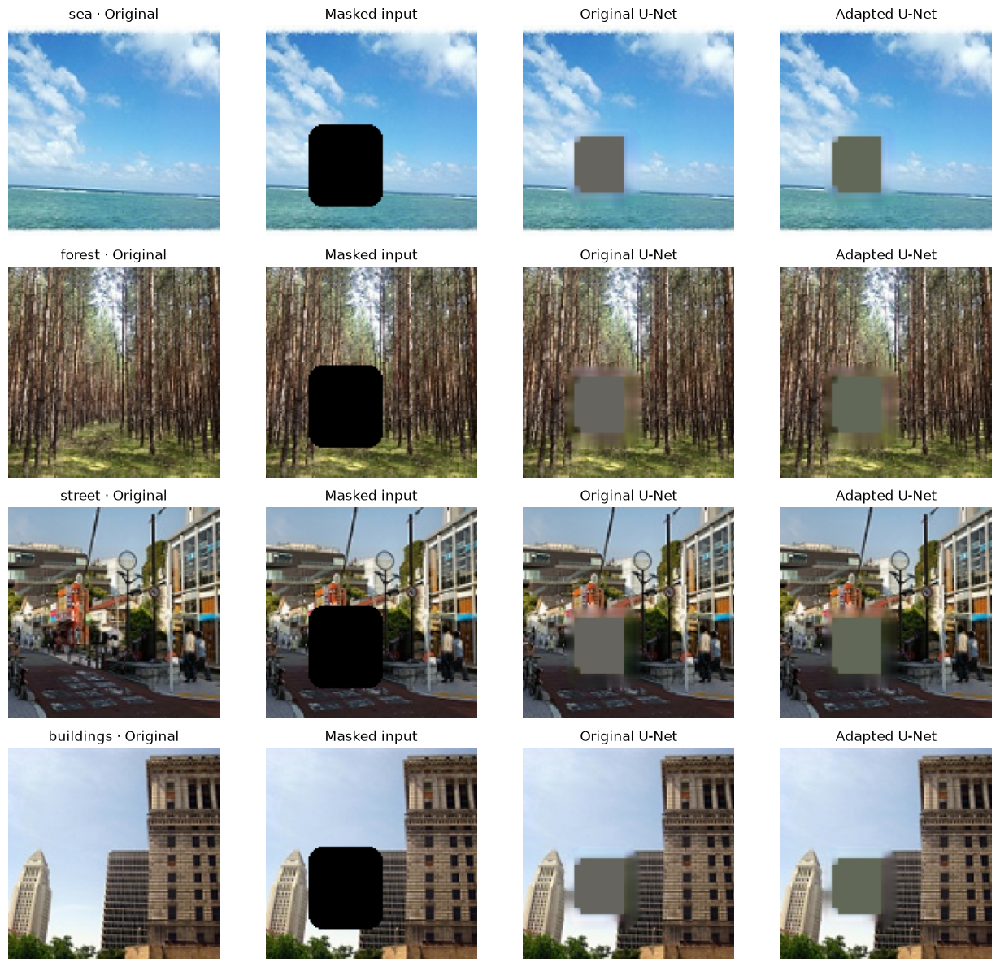

In [14]:
original_unet = keras.models.load_model(
    MODEL_DIR / "best_unet.keras",
    compile=False,
)

adapted_unet = keras.models.load_model(
    MODEL_DIR / "best_unet_mixed.keras",
    compile=False,
)

silhouette_masks = np.repeat(mask[None], len(originals), axis=0)
silhouette_inputs = np.concatenate(
    [originals * (1 - silhouette_masks), silhouette_masks],
    axis=-1,
)

before = original_unet.predict(silhouette_inputs, verbose=0)
after = adapted_unet.predict(silhouette_inputs, verbose=0)

before_results = (
    originals * (1 - silhouette_masks) + before * silhouette_masks
)
after_results = (
    originals * (1 - silhouette_masks) + after * silhouette_masks
)

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (originals[i], f"{category} · Original"),
        (silhouette_inputs[i, ..., :3], "Masked input"),
        (before_results[i], "Original U-Net"),
        (after_results[i], "Adapted U-Net"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Diagnostic: Does Visible Context Affect the Hole Center?

Apply the same fixed rectangular mask to four different validation
images. Compare the adapted U-Net's predicted RGB values at the center
of the missing region.

Nearly identical center predictions would indicate weak sensitivity
to the surrounding scene at that location. This diagnostic does not
by itself establish the cause.

In [15]:
# Use a dedicated name to avoid overwriting other masks.
context_mask = np.zeros((128, 128, 1), dtype=np.float32)
context_mask[44:84, 44:84] = 1

context_masks = np.repeat(context_mask[None], len(originals), axis=0)

context_inputs = np.concatenate(
    [originals * (1 - context_masks), context_masks],
    axis=-1,
)

context_predictions = adapted_unet.predict(context_inputs, verbose=0)

import pandas as pd

pd.DataFrame(
    context_predictions[:, 64, 64, :],
    index=SELECTED_CLASSES,
    columns=["Center R", "Center G", "Center B"],
)

,Center R,Center G,Center B
sea,0.385611,0.408455,0.34238
forest,0.385611,0.408455,0.34238
street,0.385611,0.408455,0.34238
buildings,0.385611,0.408455,0.34238


### Experiment: Expand the Model's Spatial Context

The adapted U-Net predicted identical center RGB values, to the displayed
precision, for four different scenes under the same 40 × 40 mask.

The shallow architecture has a limited receptive field. A prediction
deep inside a large hole may depend entirely on masked pixels rather
than visible background.

This variant adds bottleneck convolutions with dilation rates 2, 4,
and 8 to expand spatial context. It will be trained from scratch using
mixed masks and compared with the previous models on fixed validation
examples. Improved reconstruction is a hypothesis, not a guarantee.

In [16]:
from tensorflow import keras
from tensorflow.keras import layers

inputs = keras.Input(shape=(128, 128, 4))

# Encoder
skip1 = layers.Conv2D(
    32, 3, padding="same", activation="relu"
)(inputs)

skip2 = layers.Conv2D(
    64, 3, strides=2, padding="same", activation="relu"
)(skip1)

x = layers.Conv2D(
    128, 3, strides=2, padding="same", activation="relu"
)(skip2)

# Expand spatial context at the lowest resolution.
for dilation in [2, 4, 8]:
    x = layers.Conv2D(
        128,
        3,
        padding="same",
        dilation_rate=dilation,
        activation="relu",
    )(x)

x = layers.Dropout(0.2)(x)

# Decoder
x = layers.UpSampling2D()(x)
x = layers.Concatenate()([x, skip2])
x = layers.Conv2D(64, 3, padding="same", activation="relu")(x)

x = layers.UpSampling2D()(x)
x = layers.Concatenate()([x, skip1])
x = layers.Conv2D(32, 3, padding="same", activation="relu")(x)

outputs = layers.Conv2D(3, 1, activation="sigmoid")(x)

context_model = keras.Model(
    inputs, outputs, name="unet_expanded_context"
)

context_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_mae,
    jit_compile=False,
)

context_model.summary()

Model: "unet_expanded_context"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 128, 128,  │      1,184 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 64, 64,    │     18,496 │ conv2d[0][0]      │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 32, 32,    │     73,856 │ conv2d_1[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_2[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_3[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 32, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 32, 32,    │          0 │ conv2d_5[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d       │ (None, 64, 64,    │          0 │ dropout[0][0]     │
│ (UpSampling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 64, 64,    │          0 │ up_sampling2d[0]… │
│ (Concatenate)       │ 192)              │            │ conv2d_1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 64, 64,    │    110,656 │ concatenate[0][0] │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_1     │ (None, 128, 128,  │          0 │ conv2d_6[0][0]    │
│ (UpSampling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 128, 128,  │          0 │ up_sampling2d_1[… │
│ (Concatenate)       │ 96)               │            │ conv2d[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 128, 128,  │     27,680 │ concatenate_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 128, 128,  │         99 │ conv2d_7[0][0]    │
│                     │ 3)                │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 674,723 (2.57 MB)

 Trainable params: 674,723 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

### Train the U-Net with Expanded Context

Train the new architecture on mixed masks and monitor its loss on
the fixed mixed-mask validation set.

Save the best checkpoint separately and stop after four consecutive
epochs without validation improvement. Record total training time.

This run starts from scratch. Comparisons with the adapted U-Net
must account for their different training histories.

In [17]:
import time

context_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_context_unet.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

start = time.perf_counter()

history_context = context_model.fit(
    train_mixed,
    validation_data=val_mixed,
    epochs=20,
    shuffle=False,
    callbacks=context_callbacks,
)

elapsed = time.perf_counter() - start

print(f"Training time: {elapsed / 60:.1f} minutes")
print(f"Best mixed-mask validation loss: "
      f"{min(history_context.history['val_loss']):.4f}")

Epoch 1/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 72s 562ms/step - loss: 0.1673 - val_loss: 0.1446
Epoch 2/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 70s 562ms/step - loss: 0.1330 - val_loss: 0.1248
Epoch 3/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 566ms/step - loss: 0.1227 - val_loss: 0.1175
Epoch 4/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 564ms/step - loss: 0.1156 - val_loss: 0.1184
Epoch 5/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 568ms/step - loss: 0.1129 - val_loss: 0.1119
Epoch 6/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 569ms/step - loss: 0.1116 - val_loss: 0.1110
Epoch 7/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 566ms/step - loss: 0.1093 - val_loss: 0.1104
Epoch 8/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 569ms/step - loss: 0.1083 - val_loss: 0.1088
Epoch 9/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 72s 576ms/step - loss: 0.1083 - val_loss: 0.1091
Epoch 10/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 71s 568ms/step - loss: 0.1061 - val_loss: 0.1085
Epoch 11/20
125/125 ━━━━━━━━━━━━━━━━━━━━ 1037s 8s/step - loss: 0.1073 - val_loss: 0.1090
Epoch 12/20
125/125 

### Evaluate the Effect of Expanded Context

The best mixed-mask validation loss decreased from approximately
0.1255 for the adapted U-Net to 0.1043 for the expanded-context model,
a relative reduction of 16.9%.

Repeat the fixed rectangular-hole diagnostic on the same four
validation images. Inspect whether center predictions vary across
scenes and whether the reconstructed regions blend with the background.

The models have different training histories, so this comparison does
not isolate the effect of dilation alone.

In [18]:
context_best = keras.models.load_model(
    MODEL_DIR / "best_context_unet.keras",
    compile=False,
)

adapted_best = keras.models.load_model(
    MODEL_DIR / "best_unet_mixed.keras",
    compile=False,
)

# Recreate the diagnostic mask explicitly.
diagnostic_mask = np.zeros((128, 128, 1), dtype=np.float32)
diagnostic_mask[44:84, 44:84] = 1

diagnostic_masks = np.repeat(
    diagnostic_mask[None], len(originals), axis=0
)

diagnostic_inputs = np.concatenate(
    [originals * (1 - diagnostic_masks), diagnostic_masks],
    axis=-1,
)

old_predictions = adapted_best.predict(diagnostic_inputs, verbose=0)
new_predictions = context_best.predict(diagnostic_inputs, verbose=0)

old_results = (
    originals * (1 - diagnostic_masks)
    + old_predictions * diagnostic_masks
)

new_results = (
    originals * (1 - diagnostic_masks)
    + new_predictions * diagnostic_masks
)

display(pd.DataFrame(
    new_predictions[:, 64, 64, :],
    index=SELECTED_CLASSES,
    columns=["Center R", "Center G", "Center B"],
))

,Center R,Center G,Center B
sea,0.617163,0.792465,0.931256
forest,0.472739,0.389956,0.326556
street,0.670057,0.503467,0.387302
buildings,0.646567,0.653537,0.668967


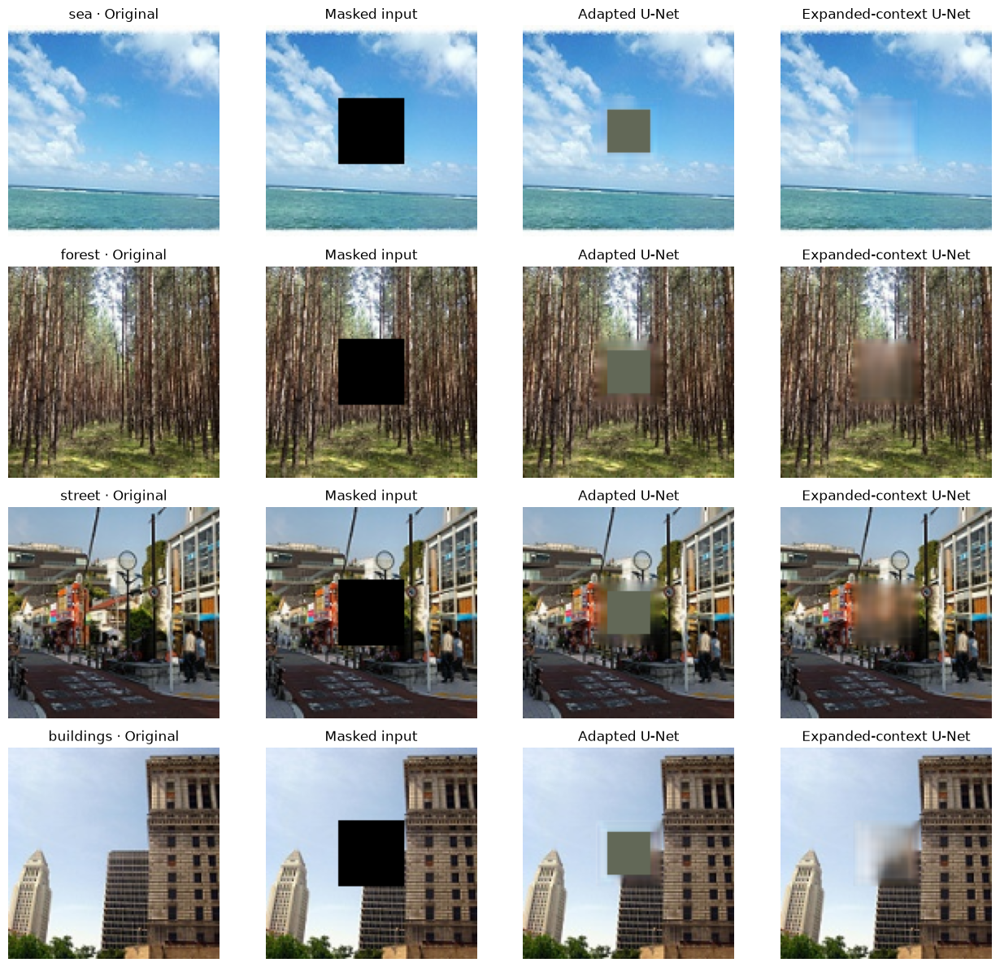

In [19]:
fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (originals[i], f"{category} · Original"),
        (diagnostic_inputs[i, ..., :3], "Masked input"),
        (old_results[i], "Adapted U-Net"),
        (new_results[i], "Expanded-context U-Net"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Expanded-Context Diagnostic Results

Under an identical mask, the expanded-context U-Net produces different
center RGB values for each scene. Unlike the previous model's nearly
constant center predictions, these outputs demonstrate sensitivity to
the surrounding image.

Visual inspection shows that the uniform central patch is replaced
by scene-dependent colors and coarse transitions. However, fine
structures such as tree trunks, street objects, and building edges
remain blurred or incomplete.

These four examples support improved use of spatial context, but do
not establish overall superiority over OpenCV. The models also have
different training histories, so the improvement cannot be attributed
to dilation alone.

### Experiment: Progressive Inpainting

Use the trained expanded-context U-Net to fill a hole from its boundary
toward its center.

At each iteration, predict the missing region but retain only a narrow
band along its boundary. Update the image and shrink the remaining mask
before the next prediction.

Compare this approach with single-pass inference using identical images
and masks. Original pixels outside the mask remain unchanged. Generated
pixels become context for later iterations, which may propagate errors.

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras

context_best = keras.models.load_model(
    MODEL_DIR / "best_context_unet.keras",
    compile=False,
)


def progressive_inpaint(model, images, masks, band_width=3):
    filled = images * (1 - masks)
    remaining = masks.copy()
    kernel = np.ones((3, 3), dtype=np.uint8)
    steps = 0

    while remaining.any():
        inputs = np.concatenate([filled, remaining], axis=-1)
        predictions = model.predict(inputs, verbose=0)

        smaller = np.stack([
            cv2.erode(
                mask[..., 0].astype(np.uint8),
                kernel,
                iterations=band_width,
                borderType=cv2.BORDER_CONSTANT,
                borderValue=1,
            )[..., None]
            for mask in remaining
        ]).astype(np.float32)

        # Accept predictions only along the current hole boundary.
        boundary = remaining - smaller
        filled = filled * (1 - boundary) + predictions * boundary
        remaining = smaller
        steps += 1

    return filled, steps

### Compare Both Inference Strategies

Apply a fixed 40 × 40 rectangular mask to the four validation examples.
Measure masked MAE per image and inspect the reconstructed structures.

The progressive version uses a three-pixel boundary band. This is an
exploratory setting, not a validated optimum.

In [22]:
progressive_mask = np.zeros((128, 128, 1), dtype=np.float32)
progressive_mask[44:84, 44:84] = 1

progressive_masks = np.repeat(
    progressive_mask[None], len(originals), axis=0
)

masked_images = originals * (1 - progressive_masks)
inputs = np.concatenate([masked_images, progressive_masks], axis=-1)

single_predictions = context_best.predict(inputs, verbose=0)
single_results = (
    originals * (1 - progressive_masks)
    + single_predictions * progressive_masks
)

progressive_results, steps = progressive_inpaint(
    context_best,
    originals,
    progressive_masks,
    band_width=3,
)

print(f"Progressive inference passes: {steps}")

Progressive inference passes: 7


### Inspect Reconstruction Quality

Compare color transitions, continuity of edges, and possible accumulated
artifacts. A lower masked MAE indicates closer pixel values, but visual
inspection is also needed to assess the usefulness of the reconstruction.

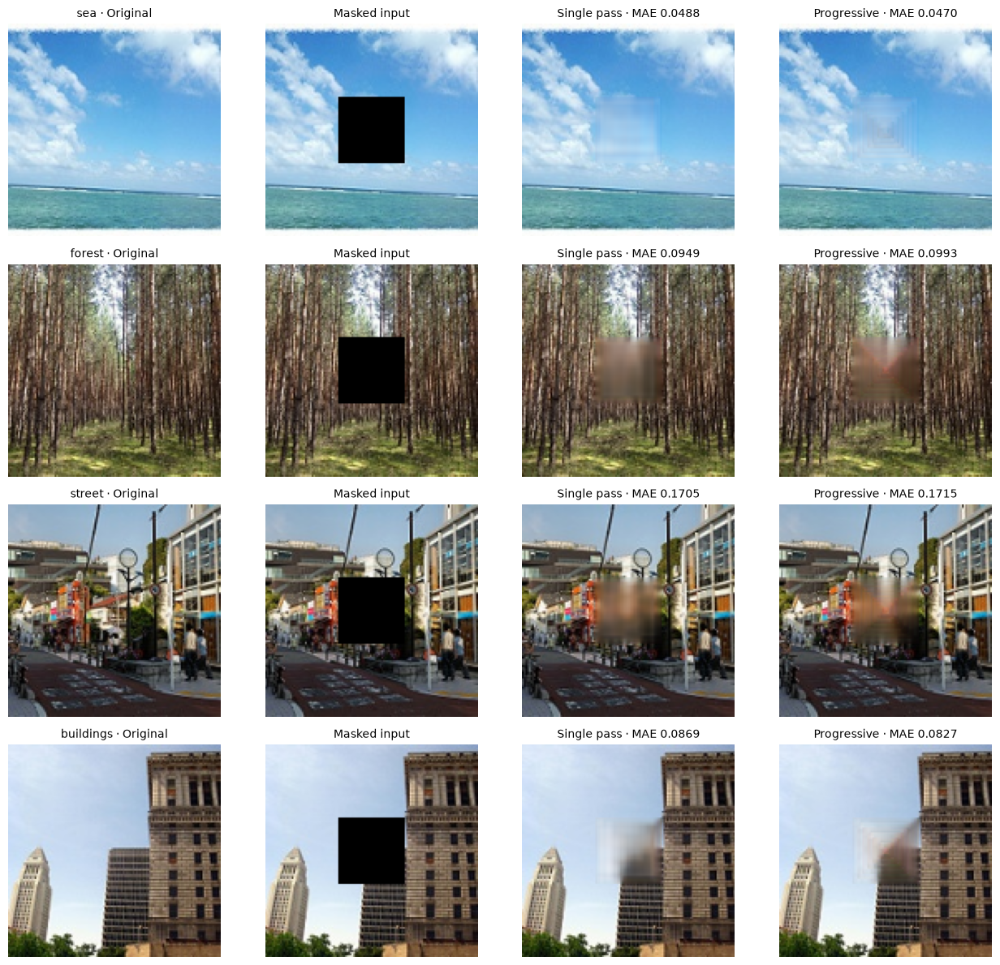

In [23]:
fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    single_error = (
        np.abs(originals[i] - single_results[i]) * progressive_mask
    ).sum() / (3 * progressive_mask.sum())

    progressive_error = (
        np.abs(originals[i] - progressive_results[i]) * progressive_mask
    ).sum() / (3 * progressive_mask.sum())

    panels = [
        (originals[i], f"{category} · Original"),
        (masked_images[i], "Masked input"),
        (single_results[i], f"Single pass · MAE {single_error:.4f}"),
        (
            progressive_results[i],
            f"Progressive · MAE {progressive_error:.4f}",
        ),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Progressive Inpainting Results

On these four validation examples, progressive inference reduced
masked MAE for sea and buildings but increased it for forest and street.

The average error was nearly unchanged, while progressive inference
required seven model passes instead of one. Visual inspection revealed
nested bands and directional artifacts consistent with error propagation.

We retain single-pass inference as the working approach. This small
diagnostic does not establish performance across the full validation set
or rule out models specifically trained for progressive reconstruction.

## Experiment: More Training Data and a Higher-Capacity U-Net

Expand training from 2,000 to 6,000 images, using 1,500 images per
category. Preserve the original training examples and exclude all
previously selected validation images.

Build a deeper U-Net with two convolutions per encoder level and
dilated bottleneck layers. Keep the image resolution, batch size,
mixed-mask generator, and masked MAE objective unchanged.

This experiment changes dataset size and architecture together.
Results will measure their combined effect.

In [24]:
from pathlib import Path
import numpy as np
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

rng = np.random.default_rng(42)

original_train_paths = set(map(str, train_paths))
reserved_val_paths = set(map(str, val_paths))
expanded_train_paths = []

for category in SELECTED_CLASSES:
    category_files = sorted(
        str(path) for path in (train_dir / category).glob("*.jpg")
    )

    existing = [
        path for path in category_files
        if path in original_train_paths
    ]

    available = [
        path for path in category_files
        if path not in original_train_paths
        and path not in reserved_val_paths
    ]

    additional = rng.choice(
        available,
        size=1500 - len(existing),
        replace=False,
    ).tolist()

    expanded_train_paths.extend(existing + additional)

print(f"Training images: {len(expanded_train_paths)}")
print(f"Reserved validation images: {len(reserved_val_paths)}")

Training images: 6000
Reserved validation images: 400


### Build the Expanded Training Pipeline

Load images in batches of 16 and apply mixed masks during training.
Keep val_mixed unchanged so that validation images and masks remain
identical to those used in the previous mixed-mask experiments.

In [25]:
mixed_train_rng = np.random.default_rng(42)

expanded_train_ds = (
    tf.data.Dataset.from_tensor_slices(expanded_train_paths)
    .shuffle(len(expanded_train_paths), seed=42)
    .map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(16)
)

expanded_train_mixed = (
    expanded_train_ds.enumerate()
    .map(
        lambda index, batch: prepare_mixed_batch(
            index, batch, training=True
        )
    )
    .prefetch(1)
)

### Build a Deeper U-Net

Use three downsampling stages, two convolutions per encoder level,
and a dilated bottleneck to increase model capacity and spatial context.

Skip connections transfer encoder features to matching decoder levels.
The model receives four channels and predicts three RGB channels.
Train this architecture from scratch.

In [26]:
keras.utils.set_random_seed(42)


def conv_block(x, filters):
    x = layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)
    return layers.Conv2D(
        filters, 3, padding="same", activation="relu"
    )(x)


inputs = keras.Input(shape=(128, 128, 4))
x = inputs
skips = []

# Encoder: 128 → 64 → 32 → 16
for filters in [32, 64, 128]:
    x = conv_block(x, filters)
    skips.append(x)
    x = layers.Conv2D(
        filters, 3, strides=2, padding="same", activation="relu"
    )(x)

# Bottleneck with expanded context.
x = conv_block(x, 256)

for dilation in [2, 4]:
    x = layers.Conv2D(
        256, 3,
        padding="same",
        dilation_rate=dilation,
        activation="relu",
    )(x)

x = layers.Dropout(0.2)(x)

# Decoder: 16 → 32 → 64 → 128
for filters, skip in zip([128, 64, 32], reversed(skips)):
    x = layers.UpSampling2D()(x)
    x = layers.Concatenate()([x, skip])
    x = conv_block(x, filters)

outputs = layers.Conv2D(3, 1, activation="sigmoid")(x)

deep_model = keras.Model(
    inputs, outputs, name="deep_unet_6000_images"
)

deep_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_mae,
    jit_compile=False,
)

deep_model.summary()

Model: "deep_unet_6000_images"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 4)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 128, 128,  │      1,184 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 128, 128,  │      9,248 │ conv2d_9[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 64, 64,    │      9,248 │ conv2d_10[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 64, 64,    │     18,496 │ conv2d_11[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     36,928 │ conv2d_12[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 32, 32,    │     36,928 │ conv2d_13[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 32,    │     73,856 │ conv2d_14[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │    147,584 │ conv2d_15[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 16, 16,    │    147,584 │ conv2d_16[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 16, 16,    │    295,168 │ conv2d_17[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_18[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_19[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 16, 16,    │    590,080 │ conv2d_20[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16, 16,    │          0 │ conv2d_21[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling2d_2     │ (None, 32, 32,    │          0 │ dropout_1[0][0]   │
│ (UpSampling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 32, 32,    │          0 │ up_sampling2d_2[

 Total params: 3,321,155 (12.67 MB)

 Trainable params: 3,321,155 (12.67 MB)

 Non-trainable params: 0 (0.00 B)

### Train and Save the Best Model

Train for up to 20 epochs and select the checkpoint with the lowest
loss on the unchanged mixed-mask validation set.

Each epoch now contains 375 batches instead of 125. Both the larger
dataset and the deeper architecture increase computational cost.
Equal epoch counts do not represent equal training budgets.

The previous expanded-context U-Net achieved a best mixed-mask
validation loss of approximately 0.1043.

In [27]:
import time

deep_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_deep_unet_6000.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

start = time.perf_counter()

history_deep = deep_model.fit(
    expanded_train_mixed,
    validation_data=val_mixed,
    epochs=20,
    shuffle=False,
    callbacks=deep_callbacks,
)

print(f"Elapsed time: {(time.perf_counter() - start) / 60:.1f} minutes")
print(f"Best validation loss: {min(history_deep.history['val_loss']):.4f}")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 630ms/step - loss: 0.1469 - val_loss: 0.1286
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 237s 633ms/step - loss: 0.1203 - val_loss: 0.1157
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 253s 675ms/step - loss: 0.1135 - val_loss: 0.1121
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3317s 9s/step - loss: 0.1106 - val_loss: 0.1135
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2243s 6s/step - loss: 0.1089 - val_loss: 0.1104
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 464s 1s/step - loss: 0.1075 - val_loss: 0.1082
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 636ms/step - loss: 0.1067 - val_loss: 0.1055
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 636ms/step - loss: 0.1048 - val_loss: 0.1050
Epoch 9/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 636ms/step - loss: 0.1032 - val_loss: 0.1050
Epoch 10/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 636ms/step - loss: 0.1020 - val_loss: 0.1052
Epoch 11/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 635ms/step - loss: 0.1013 - val_loss: 0.1049
Epoch 12/20
375

### Evaluate the Larger-Data, Higher-Capacity Model

The best mixed-mask validation loss decreased from approximately
0.1043 to 0.0998, a relative reduction of 4.3%.

This experiment increased both training-set size and model capacity,
so the result reflects their combined effect and a larger training
budget.

Compare the saved models on identical validation images and masks.
Inspect whether the numerical improvement translates into better
structure, texture, and transitions around the missing region.

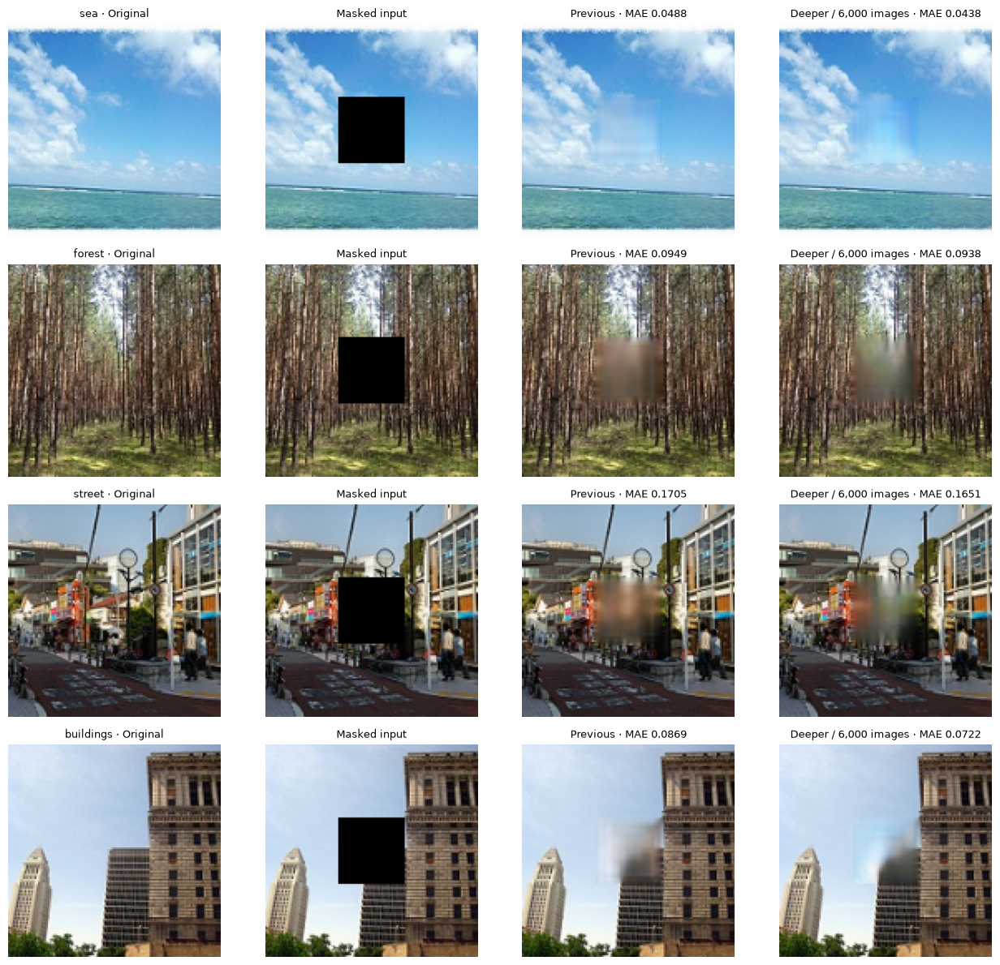

In [28]:
previous_best = keras.models.load_model(
    MODEL_DIR / "best_context_unet.keras",
    compile=False,
)

deep_best = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000.keras",
    compile=False,
)

# Fixed diagnostic mask; reuse the four validation originals.
comparison_mask = np.zeros((128, 128, 1), dtype=np.float32)
comparison_mask[44:84, 44:84] = 1

comparison_masks = np.repeat(
    comparison_mask[None], len(originals), axis=0
)

masked_images = originals * (1 - comparison_masks)
comparison_inputs = np.concatenate(
    [masked_images, comparison_masks], axis=-1
)

previous_predictions = previous_best.predict(
    comparison_inputs, verbose=0
)
deep_predictions = deep_best.predict(
    comparison_inputs, verbose=0
)

previous_results = (
    masked_images + previous_predictions * comparison_masks
)
deep_results = masked_images + deep_predictions * comparison_masks

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    previous_error = (
        np.abs(originals[i] - previous_results[i]) * comparison_mask
    ).sum() / (3 * comparison_mask.sum())

    deep_error = (
        np.abs(originals[i] - deep_results[i]) * comparison_mask
    ).sum() / (3 * comparison_mask.sum())

    panels = [
        (originals[i], f"{category} · Original"),
        (masked_images[i], "Masked input"),
        (
            previous_results[i],
            f"Previous · MAE {previous_error:.4f}",
        ),
        (
            deep_results[i],
            f"Deeper / 6,000 images · MAE {deep_error:.4f}",
        ),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Results: More Data and a Higher-Capacity Model

The deeper U-Net trained on 6,000 images reduced masked MAE in all
four diagnostic examples. The largest relative improvement occurred
in the building example.

However, lower pixel error did not eliminate visible reconstruction
artifacts. Fine textures and structures remain blurred, and some
mask boundaries are still apparent.

The full mixed-mask validation loss improved from approximately
0.1043 to 0.0998, a reduction of 4.3%. Because dataset size, architecture,
and training budget changed together, their individual contributions
cannot be isolated.

### Compare the Best Model with OpenCV on Mixed Masks

Evaluate the deeper U-Net and OpenCV Telea on identical validation
images and reproducible mixed masks.

Calculate MAE inside the missing region for each image, then average
the scores by category and across the full validation set.

This per-image average differs from the batch-aggregated validation
loss reported during training. Keep the test set reserved.

In [29]:
import cv2
import numpy as np
import pandas as pd
from pathlib import Path
from tensorflow import keras

deep_best = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000.keras",
    compile=False,
)

mixed_results = []

for inputs, targets in val_mixed:
    predictions = deep_best.predict(inputs, verbose=0)

    for input_image, target, prediction in zip(
        inputs.numpy(), targets.numpy(), predictions
    ):
        original = target[..., :3]
        mask = target[..., 3:]

        opencv_result = cv2.inpaint(
            np.round(input_image[..., :3] * 255).astype(np.uint8),
            (mask[..., 0] * 255).astype(np.uint8),
            inpaintRadius=3,
            flags=cv2.INPAINT_TELEA,
        ).astype(np.float32) / 255

        denominator = 3 * mask.sum()

        mixed_results.append({
            "Deep U-Net": (
                np.abs(original - prediction) * mask
            ).sum() / denominator,
            "OpenCV": (
                np.abs(original - opencv_result) * mask
            ).sum() / denominator,
        })

mixed_comparison = pd.DataFrame(mixed_results)

# The validation pipeline preserves the order of val_paths.
mixed_comparison["category"] = [
    Path(path).parent.name for path in val_paths
]

mixed_summary = mixed_comparison.groupby("category").mean()
mixed_summary.loc["Overall"] = (
    mixed_comparison[["Deep U-Net", "OpenCV"]].mean()
)

display(mixed_summary)

2026-11-17 13:14:10.050838: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,Deep U-Net,OpenCV
category,,
buildings,0.110408,0.121084
forest,0.098018,0.105695
sea,0.066873,0.070546
street,0.113379,0.123694
Overall,0.097169,0.105255


### Visualize Validation Performance

Compare mean masked MAE by scene category. Lower values indicate
closer reconstruction of the original pixels, but do not necessarily
imply more realistic textures or better visual quality.

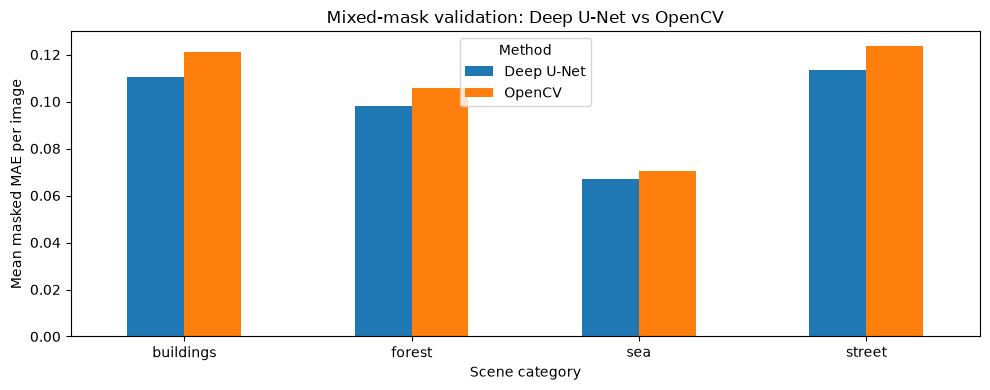

In [30]:
mixed_summary.drop(index="Overall").plot.bar(
    figsize=(10, 4),
    rot=0,
)

plt.title("Mixed-mask validation: Deep U-Net vs OpenCV")
plt.xlabel("Scene category")
plt.ylabel("Mean masked MAE per image")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

### Mixed-Mask Validation Results

The Deep U-Net achieved a mean per-image masked MAE of 0.097169,
compared with 0.105255 for OpenCV Telea: approximately 7.7% lower error.

The neural model achieved lower average error in all four categories.
These results apply to the fixed mixed-mask validation set and do not
establish superior visual quality for every image.

### Fine-Tune the Deep U-Net

Continue from the best checkpoint with a learning rate of 0.0001.
Keep all layers trainable and preserve the data, masks, architecture,
and loss function.

Train for up to ten additional epochs and save the best checkpoint
separately. This experiment combines additional training with a lower
learning rate; it does not isolate the learning-rate effect.

In [31]:
deep_tuned = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000.keras",
    compile=False,
)

deep_tuned.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=masked_mae,
    jit_compile=False,
)

baseline_deep_loss = deep_tuned.evaluate(val_mixed, verbose=0)

deep_tuned_callbacks = [
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
    ),
    keras.callbacks.ModelCheckpoint(
        filepath=str(MODEL_DIR / "best_deep_unet_6000_tuned.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

history_deep_tuned = deep_tuned.fit(
    expanded_train_mixed,
    validation_data=val_mixed,
    epochs=10,
    shuffle=False,
    callbacks=deep_tuned_callbacks,
)

print(f"Before fine-tuning: {baseline_deep_loss:.4f}")
print(
    f"Best after fine-tuning: "
    f"{min(history_deep_tuned.history['val_loss']):.4f}"
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 240s 635ms/step - loss: 0.0955 - val_loss: 0.0970
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 637ms/step - loss: 0.0949 - val_loss: 0.0970
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 637ms/step - loss: 0.0947 - val_loss: 0.0966
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 637ms/step - loss: 0.0941 - val_loss: 0.0965
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 636ms/step - loss: 0.0944 - val_loss: 0.0963
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 636ms/step - loss: 0.0943 - val_loss: 0.0963
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 239s 636ms/step - loss: 0.0939 - val_loss: 0.0960
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 636ms/step - loss: 0.0950 - val_loss: 0.0961
Epoch 9/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 636ms/step - loss: 0.0937 - val_loss: 0.0961
Epoch 10/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 238s 635ms/step - loss: 0.0935 - val_loss: 0.0958
Before fine-tuning: 0.0998
Best after fine-tuning: 0.0958


### Evaluate the Fine-Tuned Deep U-Net

Fine-tuning reduced the mixed-mask validation loss from approximately
0.0998 to 0.0958, a relative improvement of 4.0%.

Evaluate the saved checkpoint using mean masked MAE per image.
Compare it with the previous Deep U-Net and OpenCV on the same fixed
validation images and masks.

This comparison assesses numerical reconstruction accuracy.
Visual quality must also be inspected.

In [32]:
deep_tuned_best = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

tuned_errors = []

for inputs, targets in val_mixed:
    predictions = deep_tuned_best.predict(inputs, verbose=0)

    originals_batch = targets[..., :3].numpy()
    masks_batch = targets[..., 3:].numpy()

    errors = (
        np.abs(originals_batch - predictions) * masks_batch
    ).sum(axis=(1, 2, 3)) / (
        3 * masks_batch.sum(axis=(1, 2, 3))
    )

    tuned_errors.extend(errors)

mixed_comparison["Tuned Deep U-Net"] = tuned_errors

methods = ["Deep U-Net", "Tuned Deep U-Net", "OpenCV"]

mixed_summary = mixed_comparison.groupby("category")[methods].mean()
mixed_summary.loc["Overall"] = mixed_comparison[methods].mean()

display(mixed_summary)

2026-11-17 14:00:44.564679: I tensorflow/core/framework/local_rendezvous.cc:405] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


,Deep U-Net,Tuned Deep U-Net,OpenCV
category,,,
buildings,0.110408,0.106453,0.121084
forest,0.098018,0.094986,0.105695
sea,0.066873,0.061688,0.070546
street,0.113379,0.109814,0.123694
Overall,0.097169,0.093235,0.105255


### Compare Validation Error by Category

Lower bars indicate lower mean masked MAE. Check whether fine-tuning
improves all categories or whether gains are concentrated in certain
types of scenes.

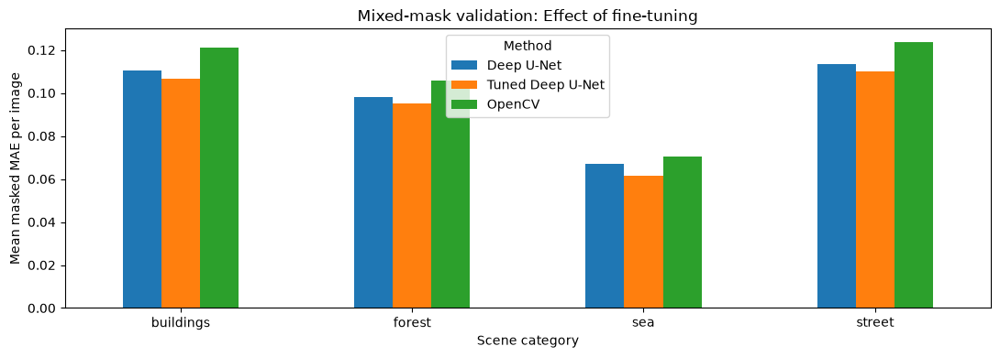

In [33]:
mixed_summary.drop(index="Overall").plot.bar(
    figsize=(11, 4),
    rot=0,
)

plt.title("Mixed-mask validation: Effect of fine-tuning")
plt.xlabel("Scene category")
plt.ylabel("Mean masked MAE per image")
plt.legend(title="Method")
plt.tight_layout()
plt.show()

### Fine-Tuning Results and Visual Inspection

The tuned Deep U-Net achieved a mean per-image masked MAE of 0.093235,
compared with 0.097169 before fine-tuning and 0.105255 for OpenCV.

This corresponds to approximately 4.0% lower error than the previous
checkpoint and 11.4% lower error than OpenCV. All four categories improved.

Inspect the same fixed rectangular-hole examples before and after
fine-tuning to assess whether lower error also improves visible
transitions and reconstruction detail.

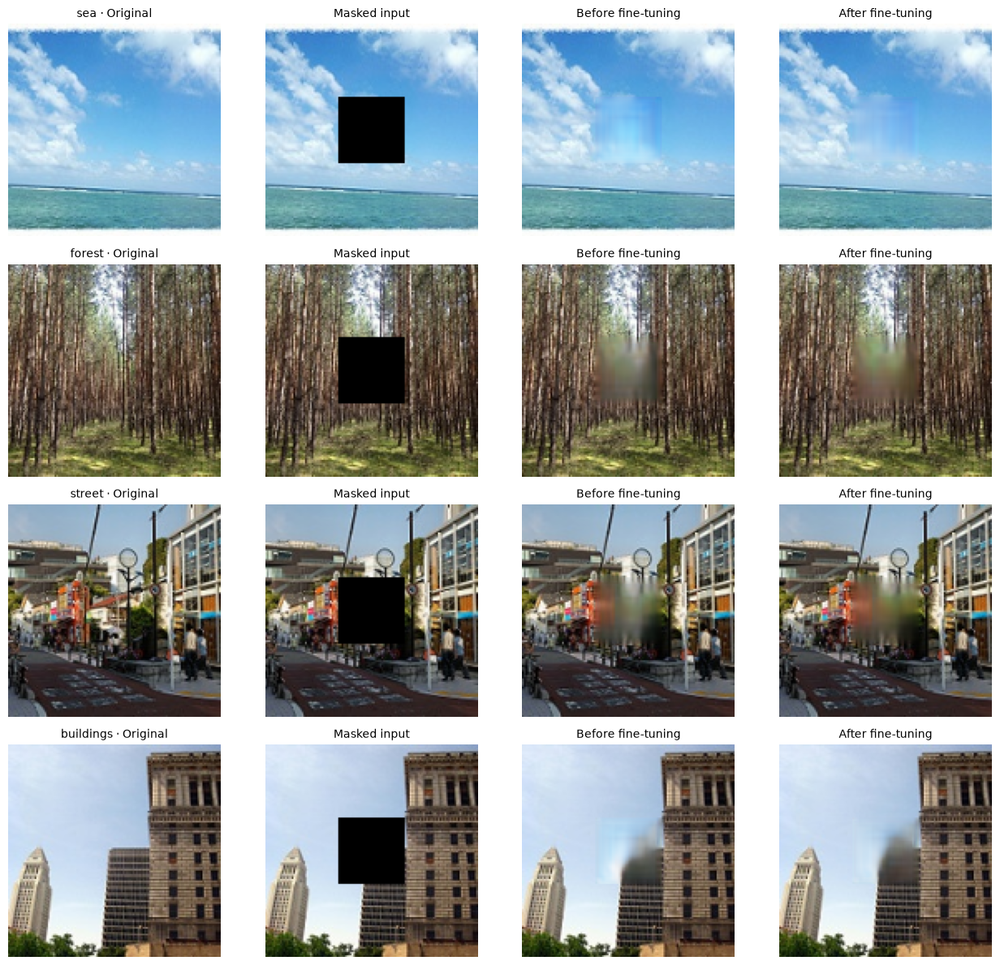

In [34]:
deep_before = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000.keras",
    compile=False,
)

deep_after = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

visual_mask = np.zeros((128, 128, 1), dtype=np.float32)
visual_mask[44:84, 44:84] = 1
visual_masks = np.repeat(visual_mask[None], len(originals), axis=0)

visual_masked = originals * (1 - visual_masks)
visual_inputs = np.concatenate([visual_masked, visual_masks], axis=-1)

before_predictions = deep_before.predict(visual_inputs, verbose=0)
after_predictions = deep_after.predict(visual_inputs, verbose=0)

before_results = visual_masked + before_predictions * visual_masks
after_results = visual_masked + after_predictions * visual_masks

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (originals[i], f"{category} · Original"),
        (visual_masked[i], "Masked input"),
        (before_results[i], "Before fine-tuning"),
        (after_results[i], "After fine-tuning"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Visual Results After Fine-Tuning

Fine-tuning improved mean masked validation MAE, but visual gains
in these four examples are limited.

Color transitions changed, while missing tree trunks, street objects,
and building details remain blurred. The sky example still shows
a visible rectangular region.

These results distinguish pixel reconstruction accuracy from visual
quality: lower MAE does not necessarily produce a convincing fill.

## Experiment: Masked MAE and Perceptual Loss

Keep the current U-Net architecture and training data unchanged.
Initialize from the best fine-tuned checkpoint.

Use a frozen ImageNet-pretrained VGG16 to compare visual features
of the original image and the reconstructed image. VGG16 is used
only during training, not as a post-processing model.

Combine pixel reconstruction error with feature reconstruction error.
Inspect their magnitudes before choosing the perceptual-loss weight.
Improved visual detail is a hypothesis, not a guaranteed outcome.

In [35]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input

perceptual_model = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

vgg = VGG16(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3),
)

feature_extractor = keras.Model(
    vgg.input,
    [
        vgg.get_layer("block1_conv2").output,
        vgg.get_layer("block2_conv2").output,
        vgg.get_layer("block3_conv3").output,
    ],
)

feature_extractor.trainable = False

### Define the Perceptual Objective

Compose the reconstructed image using predicted pixels inside the mask
and original pixels outside it.

Compare frozen VGG16 features at three levels. Resize the mask to each
feature-map resolution and weight feature differences by that mask.

The feature loss measures differences in learned representations;
it is not a direct measure of realism or correct hidden content.

In [36]:
def perceptual_loss(y_true, y_pred):
    original = y_true[..., :3]
    mask = y_true[..., 3:]

    reconstructed = original * (1 - mask) + y_pred * mask

    original_features = feature_extractor(
        preprocess_input(original * 255.0),
        training=False,
    )
    reconstructed_features = feature_extractor(
        preprocess_input(reconstructed * 255.0),
        training=False,
    )

    losses = []

    for reference, prediction in zip(
        original_features, reconstructed_features
    ):
        feature_mask = tf.image.resize(
            mask,
            tf.shape(reference)[1:3],
            method="area",
        )

        channels = tf.cast(tf.shape(reference)[-1], tf.float32)

        losses.append(tf.math.divide_no_nan(
            tf.reduce_sum(
                tf.abs(reference - prediction) * feature_mask
            ),
            tf.reduce_sum(feature_mask) * channels,
        ))

    return tf.add_n(losses) / len(losses)

### Inspect Loss Magnitudes Before Training

Measure masked MAE and perceptual loss on one training batch.
Their numerical scales differ, so they should not be added with
equal weights without inspection.

A provisional weight of 0.001 is shown for diagnosis only.
One batch does not characterize the entire training distribution.

In [37]:
probe_inputs, probe_targets = next(iter(expanded_train_mixed))
probe_predictions = perceptual_model(probe_inputs, training=False)

pixel_value = float(masked_mae(probe_targets, probe_predictions))
feature_value = float(perceptual_loss(probe_targets, probe_predictions))

print(f"Masked MAE: {pixel_value:.5f}")
print(f"Perceptual loss: {feature_value:.5f}")
print(f"Perceptual contribution at weight 0.001: "
      f"{0.001 * feature_value:.5f}")

Masked MAE: 0.10935
Perceptual loss: 193.79456
Perceptual contribution at weight 0.001: 0.19379


### Configure the Combined Loss

Use masked MAE plus perceptual loss weighted by 0.0001.

On the inspected training batch, the weighted perceptual term is
approximately 18% of masked MAE. This is an initial heuristic, not
an optimized coefficient or a measure of gradient balance.

Keep VGG16 frozen and update all U-Net layers with a learning rate
of 0.0001. Track masked MAE separately because the combined loss
is not comparable with previous MAE-only validation losses.

In [38]:
PERCEPTUAL_WEIGHT = 1e-4


def combined_loss(y_true, y_pred):
    return (
        masked_mae(y_true, y_pred)
        + PERCEPTUAL_WEIGHT * perceptual_loss(y_true, y_pred)
    )


perceptual_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss=combined_loss,
    metrics=[masked_mae],
    jit_compile=False,
)

### Run a Short Perceptual Fine-Tuning Trial

Measure the starting validation losses, then fine-tune for three epochs.

Save the starting weights and the best checkpoint according to combined
validation loss. Inspect masked MAE and visual results before deciding
whether to continue.

Save U-Net weights only; the frozen feature extractor is not needed
for inference.

In [39]:
baseline_perceptual = perceptual_model.evaluate(
    val_mixed,
    return_dict=True,
    verbose=0,
)

print("Before perceptual fine-tuning:", baseline_perceptual)

perceptual_weights = MODEL_DIR / "best_perceptual_unet.weights.h5"

# Preserve the starting model if no epoch improves validation loss.
perceptual_model.save_weights(perceptual_weights)

perceptual_callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(perceptual_weights),
        monitor="val_loss",
        save_best_only=True,
        save_weights_only=True,
        initial_value_threshold=baseline_perceptual["loss"],
    ),
]

history_perceptual = perceptual_model.fit(
    expanded_train_mixed,
    validation_data=val_mixed,
    epochs=3,
    shuffle=False,
    callbacks=perceptual_callbacks,
)

perceptual_model.load_weights(perceptual_weights)

Before perceptual fine-tuning: {'loss': 0.11404085159301758, 'masked_mae': 0.09578438103199005}
Epoch 1/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 268s 707ms/step - loss: 0.1120 - masked_mae: 0.0940 - val_loss: 0.1142 - val_masked_mae: 0.0961
Epoch 2/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 266s 710ms/step - loss: 0.1114 - masked_mae: 0.0936 - val_loss: 0.1139 - val_masked_mae: 0.0958
Epoch 3/3
375/375 ━━━━━━━━━━━━━━━━━━━━ 266s 710ms/step - loss: 0.1115 - masked_mae: 0.0937 - val_loss: 0.1141 - val_masked_mae: 0.0960


### Inspect the Perceptual Fine-Tuning Trial

After three epochs, combined validation loss improved only slightly,
while masked MAE remained approximately unchanged.

Compare the best saved perceptual checkpoint with the MAE-only model
on identical validation images and masks. Inspect texture, structure,
boundary transitions, and possible new artifacts.

Do not infer improved visual quality from combined loss alone.

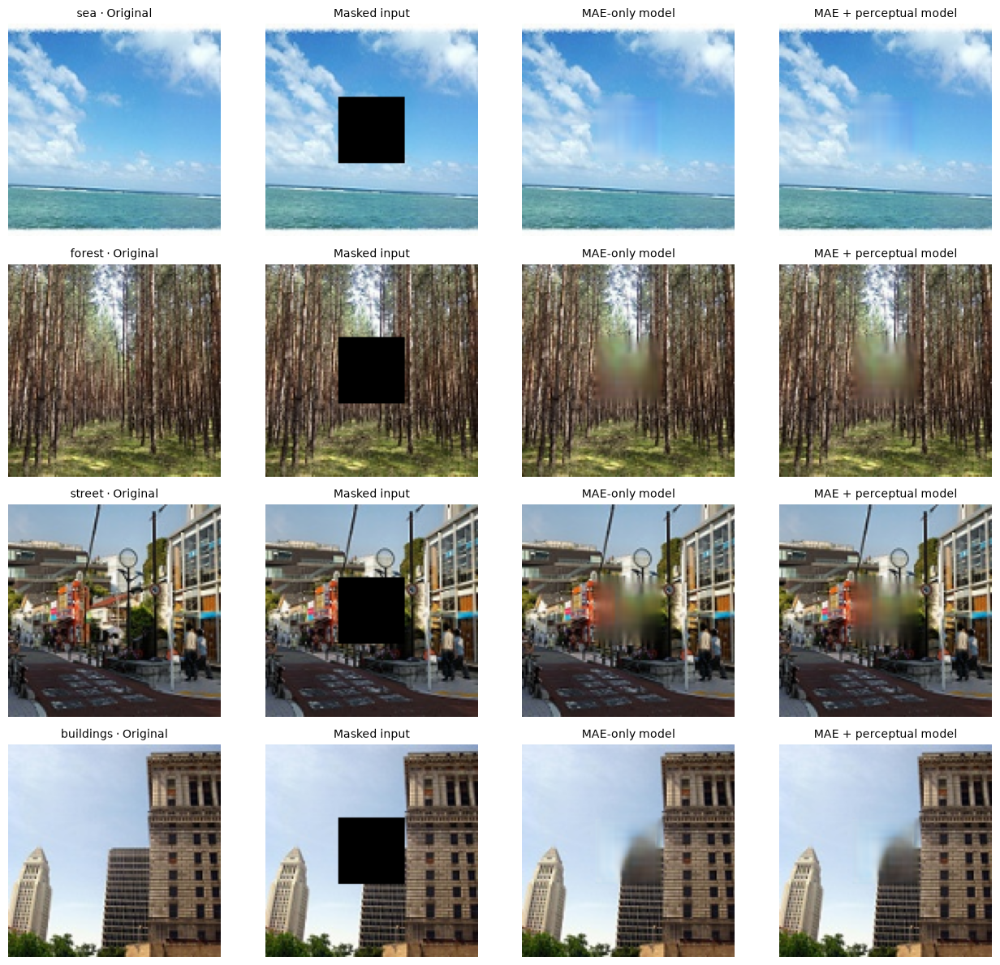

In [40]:
mae_reference = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

perceptual_candidate = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

perceptual_candidate.load_weights(
    MODEL_DIR / "best_perceptual_unet.weights.h5"
)

# Reuse the four validation images with a fixed diagnostic mask.
perceptual_mask = np.zeros((128, 128, 1), dtype=np.float32)
perceptual_mask[44:84, 44:84] = 1

perceptual_masks = np.repeat(
    perceptual_mask[None], len(originals), axis=0
)

masked = originals * (1 - perceptual_masks)
probe_inputs = np.concatenate([masked, perceptual_masks], axis=-1)

mae_predictions = mae_reference.predict(probe_inputs, verbose=0)
perceptual_predictions = perceptual_candidate.predict(
    probe_inputs, verbose=0
)

mae_results = masked + mae_predictions * perceptual_masks
perceptual_results = masked + perceptual_predictions * perceptual_masks

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (originals[i], f"{category} · Original"),
        (masked[i], "Masked input"),
        (mae_results[i], "MAE-only model"),
        (perceptual_results[i], "MAE + perceptual model"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Perceptual Fine-Tuning: Observed Results

The three-epoch trial with a perceptual-loss weight of 0.0001 produced
only a small change in combined validation loss and approximately
unchanged masked MAE.

The four diagnostic examples show no clear improvement in fine
structures or texture. Visible mask boundaries and blurred regions
remain.

We retain the MAE-only checkpoint as the working reference. This
limited trial does not rule out other perceptual-loss configurations.

## Diagnostic: Overfit Four Training Images

Train a separate model copy on four fixed training images and masks.
The purpose is to test whether the current architecture and optimization
can reconstruct these specific examples.

Disable dropout for this diagnostic and repeatedly use the same batch.
Do not use validation or test images.

Successful memorization does not demonstrate generalization. Failure
within this training budget does not prove that the architecture cannot
solve the task, but motivates further investigation.

In [41]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path
from tensorflow import keras

# Select one training image per category.
diagnostic_paths = [
    next(
        path for path in expanded_train_paths
        if Path(path).parent.name == category
    )
    for category in SELECTED_CLASSES
]

diagnostic_originals = tf.stack([
    load_image(path) for path in diagnostic_paths
]).numpy()

diagnostic_masks = np.zeros((4, 128, 128, 1), dtype=np.float32)
diagnostic_masks[:, 44:84, 44:84] = 1

diagnostic_inputs = np.concatenate(
    [
        diagnostic_originals * (1 - diagnostic_masks),
        diagnostic_masks,
    ],
    axis=-1,
)

diagnostic_targets = np.concatenate(
    [diagnostic_originals, diagnostic_masks],
    axis=-1,
)

diagnostic_model = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

# Remove stochastic regularization for the memorization test.
for layer in diagnostic_model.layers:
    if isinstance(layer, keras.layers.Dropout):
        layer.rate = 0.0

diagnostic_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=masked_mae,
    jit_compile=False,
)

### Optimize the Fixed Batch

Run 500 optimizer updates on the same four examples. Every 25 updates,
measure masked MAE with dropout disabled and retain the best measured
weights in memory.

These are optimizer steps on a tiny fixed batch, not epochs over the
full training dataset. The resulting model is for diagnosis only.

In [42]:
initial_predictions = diagnostic_model(
    diagnostic_inputs, training=False
).numpy()

initial_error = float(masked_mae(
    diagnostic_targets, initial_predictions
))

diagnostic_steps = [0]
diagnostic_errors = [initial_error]
best_error = initial_error
best_weights = diagnostic_model.get_weights()

print(f"Initial masked MAE: {initial_error:.5f}")

for step in range(1, 501):
    diagnostic_model.train_on_batch(
        diagnostic_inputs, diagnostic_targets
    )

    if step % 25 == 0:
        predictions = diagnostic_model(
            diagnostic_inputs, training=False
        ).numpy()

        error = float(masked_mae(diagnostic_targets, predictions))

        diagnostic_steps.append(step)
        diagnostic_errors.append(error)

        if error < best_error:
            best_error = error
            best_weights = diagnostic_model.get_weights()

        print(f"Step {step:3d} | Masked MAE: {error:.5f}")

diagnostic_model.set_weights(best_weights)

print(f"Best measured masked MAE: {best_error:.5f}")

Initial masked MAE: 0.08182
Step  25 | Masked MAE: 0.03970
Step  50 | Masked MAE: 0.03148
Step  75 | Masked MAE: 0.02687
Step 100 | Masked MAE: 0.02288
Step 125 | Masked MAE: 0.02145
Step 150 | Masked MAE: 0.01879
Step 175 | Masked MAE: 0.01708
Step 200 | Masked MAE: 0.01581
Step 225 | Masked MAE: 0.01469
Step 250 | Masked MAE: 0.01364
Step 275 | Masked MAE: 0.01237
Step 300 | Masked MAE: 0.01150
Step 325 | Masked MAE: 0.01179
Step 350 | Masked MAE: 0.01137
Step 375 | Masked MAE: 0.01081
Step 400 | Masked MAE: 0.00978
Step 425 | Masked MAE: 0.00907
Step 450 | Masked MAE: 0.00921
Step 475 | Masked MAE: 0.00896
Step 500 | Masked MAE: 0.00842
Best measured masked MAE: 0.00842


### Inspect Memorization

Plot the error trajectory and compare reconstructions before and after
optimization on the fixed batch.

Look for recovered structures inside the hole, rather than color
changes alone. These results concern memorization of training examples
and must not be reported as validation or test performance.

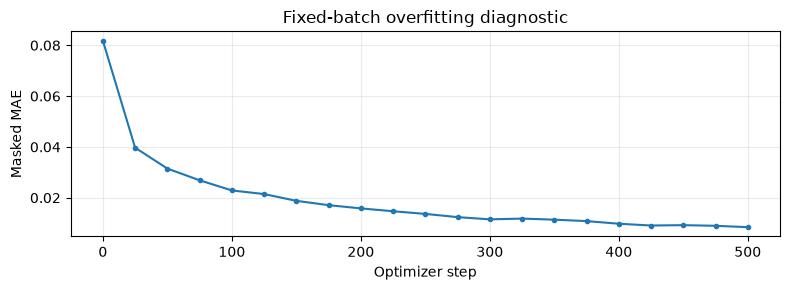

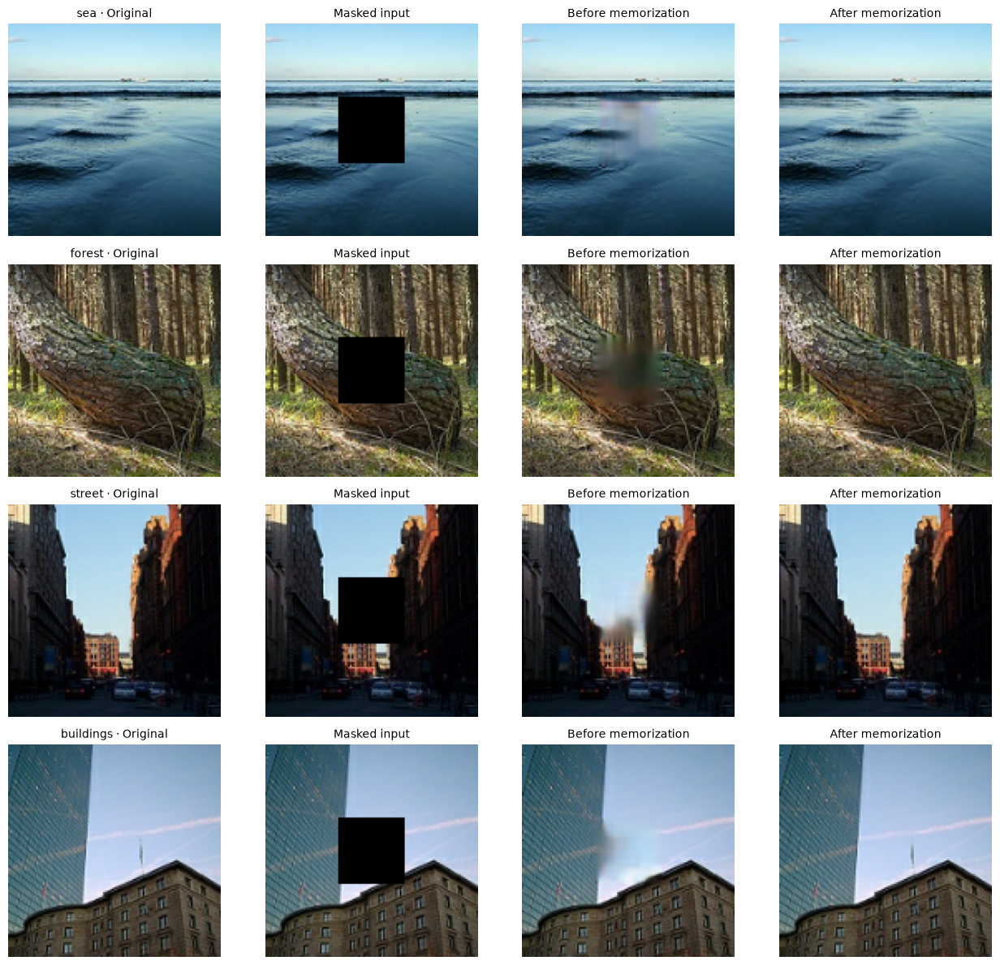

In [43]:
plt.figure(figsize=(8, 3))
plt.plot(diagnostic_steps, diagnostic_errors, marker=".")
plt.xlabel("Optimizer step")
plt.ylabel("Masked MAE")
plt.title("Fixed-batch overfitting diagnostic")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

final_predictions = diagnostic_model(
    diagnostic_inputs, training=False
).numpy()

before = (
    diagnostic_originals * (1 - diagnostic_masks)
    + initial_predictions * diagnostic_masks
)
after = (
    diagnostic_originals * (1 - diagnostic_masks)
    + final_predictions * diagnostic_masks
)

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (diagnostic_originals[i], f"{category} · Original"),
        (diagnostic_inputs[i, ..., :3], "Masked input"),
        (before[i], "Before memorization"),
        (after[i], "After memorization"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=10)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Fixed-Batch Diagnostic Results

Masked MAE decreased from 0.08182 to 0.00842 after 500 updates,
a reduction of approximately 89.7%.

The model recovered substantial detail in the four training examples,
including tree texture, water patterns, and building boundaries.
This demonstrates that the architecture and MAE objective can fit
these specific reconstructions.

The result measures memorization, not generalization. The diagnostic
used fixed examples, fixed masks, and disabled dropout. It does not
establish which factor limits performance on unseen images.

## Diagnostic: Training–Validation Reconstruction Gap

Evaluate the general-purpose checkpoint on balanced samples of
400 training images and 400 validation images.

Use the same fixed mask for each training–validation pair within
a category. Run inference with dropout disabled and calculate
masked MAE separately for each image.

This comparison measures the gap between seen and unseen images
under matched mask conditions. Do not use the model that memorized
the four diagnostic examples.

In [44]:
from pathlib import Path
import numpy as np
import pandas as pd
from tensorflow import keras

general_model = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras",
    compile=False,
)

sample_rng = np.random.default_rng(2026)

train_probe_paths = []
val_probe_paths = []
probe_categories = []

for category in SELECTED_CLASSES:
    training_candidates = sorted(
        str(path) for path in expanded_train_paths
        if Path(path).parent.name == category
    )

    validation_candidates = sorted(
        str(path) for path in val_paths
        if Path(path).parent.name == category
    )

    train_probe_paths.extend(
        sample_rng.choice(
            training_candidates, size=100, replace=False
        ).tolist()
    )

    val_probe_paths.extend(validation_candidates)
    probe_categories.extend([category] * 100)

# Identical masks for both groups, paired by row.
mask_rng = np.random.default_rng(2027)

probe_masks = np.stack([
    create_mixed_mask(mask_rng)
    for _ in train_probe_paths
])

### Evaluate Both Groups Under Matched Conditions

Load images in batches and use the same preprocessing for both groups.
Measure mean masked MAE per image rather than training-time batch loss.

A larger validation error may indicate a generalization gap.
Similar errors do not establish a single cause, but help distinguish
that gap from broader reconstruction limitations.

In [45]:
def evaluate_probe(paths, masks):
    errors = []

    for start in range(0, len(paths), 16):
        images = np.stack([
            load_image(path).numpy()
            for path in paths[start:start + 16]
        ])

        batch_masks = masks[start:start + 16]

        inputs = np.concatenate(
            [images * (1 - batch_masks), batch_masks],
            axis=-1,
        )

        predictions = general_model(inputs, training=False).numpy()

        batch_errors = (
            np.abs(images - predictions) * batch_masks
        ).sum(axis=(1, 2, 3)) / (
            3 * batch_masks.sum(axis=(1, 2, 3))
        )

        errors.extend(batch_errors)

    return np.asarray(errors)


gap_results = pd.DataFrame({
    "category": probe_categories,
    "Training MAE": evaluate_probe(train_probe_paths, probe_masks),
    "Validation MAE": evaluate_probe(val_probe_paths, probe_masks),
})

gap_summary = gap_results.groupby("category").mean()
gap_summary.loc["Overall"] = gap_results[
    ["Training MAE", "Validation MAE"]
].mean()

gap_summary["Validation - Training"] = (
    gap_summary["Validation MAE"] - gap_summary["Training MAE"]
)

display(gap_summary)

,Training MAE,Validation MAE,Validation - Training
category,,,
buildings,0.098742,0.102885,0.004142
forest,0.093257,0.095847,0.002590
sea,0.057920,0.058155,0.000235
street,0.111493,0.110679,-0.000814
Overall,0.090353,0.091891,0.001538


### Training–Validation Gap Results

Mean masked MAE was 0.090353 on the training sample and 0.091891
on validation, an absolute difference of 0.001538.

Under these matched mask conditions, the model does not exhibit
a large average training–validation gap. Reconstruction limitations
also occur on training images with newly generated masks.

This diagnostic does not isolate their cause. Optimization, model
capacity, objective design, and ambiguity in the missing content
may all contribute. Results are based on one sample and mask set.

## Freeze the Experiment Records

Save the current training and validation manifests, fixed mixed-mask
validation masks, available training histories, and reference checkpoint
information.

Validation masks are stored in the same order as the validation manifest.
Paths are relative to the project directory.

This snapshot preserves the current evaluation setup. It does not
retroactively reproduce the random masks used in previous training runs.

In [46]:
import json
import hashlib
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd

snapshot_name = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S_%fZ")
RECORD_DIR = PROJECT_ROOT / "records" / snapshot_name
RECORD_DIR.mkdir(parents=True)


def save_manifest(paths, filename):
    pd.DataFrame({
        "path": [
            Path(path).resolve().relative_to(
                PROJECT_ROOT.resolve()
            ).as_posix()
            for path in paths
        ],
        "category": [Path(path).parent.name for path in paths],
    }).to_csv(RECORD_DIR / filename, index=False)


save_manifest(expanded_train_paths, "train_6000.csv")
save_manifest(val_paths, "validation_400.csv")

# Preserve the masks in the current validation pipeline order.
fixed_val_masks = np.concatenate([
    targets[..., 3:].numpy()
    for _, targets in val_mixed
])

assert len(fixed_val_masks) == len(val_paths)

np.savez_compressed(
    RECORD_DIR / "validation_mixed_masks.npz",
    masks=fixed_val_masks.astype(bool),
)

# Save the existing test selection only if it is still in memory.
# Do not create a new test split.
if "test_df" in globals():
    save_manifest(test_df["path"].tolist(), "test_reserved.csv")

print(f"Snapshot saved to: {RECORD_DIR}")

Snapshot saved to: /Users/mateocordoba/dev/projects/photo-retouch/records/20261117T213223_080287Z


### Preserve Histories and Reference Model Identity

Save the training histories still available in memory. Missing histories
cannot be recovered by this cell.

Record software versions and a SHA-256 fingerprint of the reference
checkpoint so future comparisons can identify the exact starting model.
The model file itself remains in the models directory.

In [47]:
history_names = [
    "history",
    "history_more",
    "history_fine",
    "history_unet",
    "history_mixed",
    "history_context",
    "history_deep",
    "history_deep_tuned",
    "history_perceptual",
]

saved_histories = {
    name: {
        "epochs": list(globals()[name].epoch),
        "metrics": {
            metric: [float(value) for value in values]
            for metric, values in globals()[name].history.items()
        },
    }
    for name in history_names
    if name in globals()
}

(RECORD_DIR / "training_histories.json").write_text(
    json.dumps(saved_histories, indent=2),
    encoding="utf-8",
)

reference_checkpoint = MODEL_DIR / "best_deep_unet_6000_tuned.keras"

metadata = {
    "reference_checkpoint": reference_checkpoint.relative_to(
        PROJECT_ROOT
    ).as_posix(),
    "checkpoint_sha256": hashlib.sha256(
        reference_checkpoint.read_bytes()
    ).hexdigest(),
    "packages": {
        package: version(package)
        for package in [
            "tensorflow", "keras", "tensorflow-metal",
            "numpy", "pillow", "opencv-python",
        ]
    },
    "mask_convention": "1 = missing, 0 = visible",
    "image_size": [128, 128],
    "batch_size": 16,
    "validation_mask_order": "Matches validation_400.csv row order",
    "test_manifest_saved": (RECORD_DIR / "test_reserved.csv").exists(),
}

(RECORD_DIR / "metadata.json").write_text(
    json.dumps(metadata, indent=2),
    encoding="utf-8",
)

print("Saved histories:", list(saved_histories))
print("Unavailable histories:", [
    name for name in history_names if name not in saved_histories
])
print("Existing test manifest saved:", metadata["test_manifest_saved"])

Saved histories: ['history_mixed', 'history_context', 'history_deep', 'history_deep_tuned', 'history_perceptual']
Unavailable histories: ['history', 'history_more', 'history_fine', 'history_unet']
Existing test manifest saved: False


## Define the Fixed Visual Evaluation Panel

Select 60 validation examples before inspecting the new model results:
15 per scene category.

Within each category, sort examples by mask coverage, divide them into
three similarly sized groups, and sample five examples from each group.

These groups represent relative coverage within each category, not mask
types. Save the selected indices so all methods use identical examples.
This is a development panel, not an independent final test set.

In [48]:
# Read the saved evaluation setup rather than regenerating masks.
panel_manifest = pd.read_csv(RECORD_DIR / "validation_400.csv")
panel_masks = np.load(
    RECORD_DIR / "validation_mixed_masks.npz"
)["masks"]

panel_manifest["mask_index"] = np.arange(len(panel_manifest))
panel_manifest["coverage"] = panel_masks.mean(axis=(1, 2, 3))

panel_rng = np.random.default_rng(2028)
panel_parts = []

for category in SELECTED_CLASSES:
    category_rows = panel_manifest[
        panel_manifest["category"] == category
    ].sort_values(["coverage", "mask_index"])

    coverage_groups = np.array_split(
        category_rows.index.to_numpy(), 3
    )

    for label, indices in zip(
        ["Lower coverage", "Middle coverage", "Higher coverage"],
        coverage_groups,
    ):
        selected_indices = panel_rng.choice(
            indices, size=5, replace=False
        )

        selected = panel_manifest.loc[selected_indices].copy()
        selected["coverage_group"] = label
        panel_parts.append(selected)

visual_panel = pd.concat(panel_parts, ignore_index=True)

# Shuffle presentation order reproducibly.
visual_panel = visual_panel.sample(
    frac=1, random_state=2028
).reset_index(drop=True)

visual_panel.insert(0, "panel_id", np.arange(1, len(visual_panel) + 1))

visual_panel.to_csv(
    RECORD_DIR / "visual_panel_60.csv",
    index=False,
)

display(pd.crosstab(
    visual_panel["category"],
    visual_panel["coverage_group"],
))

print(f"Selected examples: {len(visual_panel)}")

coverage_group,Higher coverage,Lower coverage,Middle coverage
category,,,
buildings,5,5,5
forest,5,5,5
sea,5,5,5
street,5,5,5


Selected examples: 60


## Controlled Experiment: L1 versus L1 + PatchGAN

Initialize two generators from the same MAE-trained checkpoint.

Both arms will use identical training images, masks, batch size, and
optimizer-update budgets. Disable dropout in both generators to keep
this setting matched.

The discriminator learns to distinguish real images from reconstructed
images, conditioned on the missing-region mask. It is used during
training only; inference will require only the generator.

Use a fixed budget of 1,500 generator updates per arm.

In [49]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(2029)

reference_path = MODEL_DIR / "best_deep_unet_6000_tuned.keras"

l1_generator = keras.models.load_model(reference_path, compile=False)
gan_generator = keras.models.load_model(reference_path, compile=False)

for generator in [l1_generator, gan_generator]:
    generator.trainable = True

    for layer in generator.layers:
        if isinstance(layer, layers.Dropout):
            layer.rate = 0.0

EXPERIMENT_STEPS = 1500
EXPERIMENT_BATCH_SIZE = 16

### Reproduce Training Batches by Step

Construct each batch deterministically from its global step number.
Shuffle image order once per epoch and generate masks using a separate
step-specific random seed.

Requesting the same step again returns the same images and masks,
regardless of which experimental arm is running.

In [50]:
experiment_manifest = pd.read_csv(RECORD_DIR / "train_6000.csv")

experiment_paths = [
    str(PROJECT_ROOT / path)
    for path in experiment_manifest["path"]
]

steps_per_epoch = (
    len(experiment_paths) + EXPERIMENT_BATCH_SIZE - 1
) // EXPERIMENT_BATCH_SIZE


def experiment_batch(step):
    epoch, batch_index = divmod(step, steps_per_epoch)

    order = np.random.default_rng(
        np.random.SeedSequence([2029, epoch])
    ).permutation(len(experiment_paths))

    start = batch_index * EXPERIMENT_BATCH_SIZE
    indices = order[start:start + EXPERIMENT_BATCH_SIZE]

    images = np.stack([
        load_image(experiment_paths[index]).numpy()
        for index in indices
    ])

    mask_rng = np.random.default_rng(
        np.random.SeedSequence([2030, step])
    )

    masks = np.stack([
        create_mixed_mask(mask_rng)
        for _ in indices
    ])

    inputs = np.concatenate([images * (1 - masks), masks], axis=-1)
    targets = np.concatenate([images, masks], axis=-1)

    return (
        tf.convert_to_tensor(inputs, dtype=tf.float32),
        tf.convert_to_tensor(targets, dtype=tf.float32),
    )

### Build the Patch Discriminator

Receive a complete RGB image and its binary hole mask.
Output a spatial grid of real/fake scores rather than a single score.

Real examples use the original image. Generated examples preserve
original pixels outside the mask and use generator predictions inside.

The final layer outputs logits without a sigmoid. The next section
will define hinge losses and verify gradient flow before training.

In [51]:
discriminator_input = keras.Input(shape=(128, 128, 4))
x = discriminator_input

for filters in [32, 64, 128]:
    x = layers.Conv2D(
        filters, 4, strides=2, padding="same"
    )(x)
    x = layers.LeakyReLU(negative_slope=0.2)(x)

x = layers.Conv2D(256, 3, padding="same")(x)
x = layers.LeakyReLU(negative_slope=0.2)(x)

patch_scores = layers.Conv2D(1, 3, padding="same")(x)

discriminator = keras.Model(
    discriminator_input,
    patch_scores,
    name="inpainting_patch_discriminator",
)

discriminator.summary()

Model: "inpainting_patch_discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 128, 128, 4)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 64, 64, 32)     │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_30 (Conv2D)              │ (None, 32, 32, 64)     │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 16, 16, 128)    │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 16, 16, 1)      │         2,305 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 463,585 (1.77 MB)

 Trainable params: 463,585 (1.77 MB)

 Non-trainable params: 0 (0.00 B)

### Define the Adversarial Objectives

Use hinge loss for the discriminator and masked MAE plus an adversarial
term for the generator.

Score only discriminator patches whose receptive fields intersect
the missing region. Construct fake images by preserving the original
pixels outside the mask.

The generator should produce patches that the discriminator scores
as real while remaining close to the reconstruction target.

In [52]:
def discriminator_patch_mask(mask):
    # Match the spatial support of the discriminator's convolutions.
    weights = mask

    for _ in range(3):
        weights = tf.nn.max_pool2d(
            weights, ksize=4, strides=2, padding="SAME"
        )

    for _ in range(2):
        weights = tf.nn.max_pool2d(
            weights, ksize=3, strides=1, padding="SAME"
        )

    return weights


def patch_mean(values, weights):
    return tf.math.divide_no_nan(
        tf.reduce_sum(values * weights),
        tf.reduce_sum(weights),
    )


def discriminator_loss(real_scores, fake_scores, weights):
    real_loss = patch_mean(tf.nn.relu(1.0 - real_scores), weights)
    fake_loss = patch_mean(tf.nn.relu(1.0 + fake_scores), weights)

    return real_loss + fake_loss


def generator_adversarial_loss(fake_scores, weights):
    return -patch_mean(fake_scores, weights)

### Calibrate an Initial Adversarial Weight

Measure gradients of masked MAE and adversarial loss with respect to
the predicted RGB image on one fixed training batch.

Choose an initial coefficient that makes the weighted adversarial
gradient norm approximately 20% of the MAE gradient norm.

This is a starting heuristic, not an optimal balance. The discriminator
is randomly initialized, and its gradients will change during training.
No weights are updated in this diagnostic.

In [53]:
probe_inputs, probe_targets = experiment_batch(0)

probe_originals = probe_targets[..., :3]
probe_masks = probe_targets[..., 3:]
probe_patch_weights = discriminator_patch_mask(probe_masks)

probe_predictions = tf.stop_gradient(
    gan_generator(probe_inputs, training=False)
)

with tf.GradientTape(persistent=True) as tape:
    tape.watch(probe_predictions)

    probe_composite = (
        probe_originals * (1 - probe_masks)
        + probe_predictions * probe_masks
    )

    probe_fake_scores = discriminator(
        tf.concat([probe_composite, probe_masks], axis=-1),
        training=False,
    )

    probe_l1 = masked_mae(probe_targets, probe_predictions)
    probe_adv = generator_adversarial_loss(
        probe_fake_scores, probe_patch_weights
    )

l1_gradient = tape.gradient(probe_l1, probe_predictions)
adv_gradient = tape.gradient(probe_adv, probe_predictions)
del tape

l1_gradient_norm = tf.linalg.norm(l1_gradient)
adv_gradient_norm = tf.linalg.norm(adv_gradient)

# A zero or non-finite gradient would invalidate the calibration.
tf.debugging.assert_positive(l1_gradient_norm)
tf.debugging.assert_positive(adv_gradient_norm)

ADV_WEIGHT = float(
    0.2 * l1_gradient_norm / adv_gradient_norm
)
tf.debugging.assert_all_finite(
    tf.constant(ADV_WEIGHT), "Invalid adversarial weight."
)

print(f"Masked MAE: {float(probe_l1):.5f}")
print(f"L1 gradient norm: {float(l1_gradient_norm):.6f}")
print(f"Adversarial gradient norm: {float(adv_gradient_norm):.6f}")
print(f"Initial adversarial weight: {ADV_WEIGHT:.6f}")
print(
    "Weighted gradient ratio:",
    ADV_WEIGHT * float(adv_gradient_norm) / float(l1_gradient_norm),
)

Masked MAE: 0.07517
L1 gradient norm: 0.003111
Adversarial gradient norm: 0.000663
Initial adversarial weight: 0.937780
Weighted gradient ratio: 0.19999999227052329


### Initialize Independent Optimizers

Use separate Adam optimizers for the control generator, adversarial
generator, and discriminator. Both generators use identical optimizer
settings and start from the same checkpoint.

In [54]:
l1_optimizer = keras.optimizers.Adam(learning_rate=1e-4)
gan_optimizer = keras.optimizers.Adam(learning_rate=1e-4)
discriminator_optimizer = keras.optimizers.Adam(learning_rate=1e-4)

### Define Matched Training Updates

For each fixed batch, update the L1-only generator once.

For the adversarial arm, update the discriminator once using real
and generated composites, then update the generator once using
masked MAE plus the weighted adversarial objective.

Keep original pixels outside the mask unchanged. Discriminator updates
must not update generator weights, and generator updates must not
update discriminator weights.

In [55]:
@tf.function
def train_l1_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = l1_generator(inputs, training=True)
        loss = masked_mae(targets, predictions)

    gradients = tape.gradient(loss, l1_generator.trainable_variables)
    l1_optimizer.apply_gradients(
        zip(gradients, l1_generator.trainable_variables)
    )

    return loss


@tf.function
def train_gan_step(inputs, targets):
    originals = targets[..., :3]
    masks = targets[..., 3:]
    weights = discriminator_patch_mask(masks)

    # Discriminator update: generator output is treated as fixed.
    predictions = tf.stop_gradient(
        gan_generator(inputs, training=False)
    )
    composite = originals * (1 - masks) + predictions * masks

    with tf.GradientTape() as tape:
        real_scores = discriminator(
            tf.concat([originals, masks], axis=-1),
            training=True,
        )
        fake_scores = discriminator(
            tf.concat([composite, masks], axis=-1),
            training=True,
        )

        d_loss = discriminator_loss(real_scores, fake_scores, weights)

    gradients = tape.gradient(
        d_loss, discriminator.trainable_variables
    )
    discriminator_optimizer.apply_gradients(
        zip(gradients, discriminator.trainable_variables)
    )

    # Generator update: gradients pass through the discriminator,
    # but only generator variables are updated.
    with tf.GradientTape() as tape:
        predictions = gan_generator(inputs, training=True)
        composite = originals * (1 - masks) + predictions * masks

        generated_scores = discriminator(
            tf.concat([composite, masks], axis=-1),
            training=False,
        )

        g_mae = masked_mae(targets, predictions)
        g_adv = generator_adversarial_loss(generated_scores, weights)
        g_loss = g_mae + ADV_WEIGHT * g_adv

    gradients = tape.gradient(g_loss, gan_generator.trainable_variables)
    gan_optimizer.apply_gradients(
        zip(gradients, gan_generator.trainable_variables)
    )

    return {
        "discriminator_loss": d_loss,
        "gan_mae": g_mae,
        "generator_adversarial_loss": g_adv,
        "generator_total_loss": g_loss,
        "real_score": patch_mean(real_scores, weights),
        "fake_score": patch_mean(fake_scores, weights),
    }

### Run the First 50 Updates

Give both generators the same batch at every step. Record losses,
discriminator scores, and elapsed time.

These updates count toward the 1,500-step budget; they are not an
extra training run. Initial execution includes graph tracing overhead.

This stage checks numerical behavior and runtime. It does not establish
visual improvement or convergence.

In [56]:
import time

experiment_log = []
experiment_start = time.perf_counter()

for step in range(50):
    batch_inputs, batch_targets = experiment_batch(step)

    control_loss = train_l1_step(batch_inputs, batch_targets)
    gan_values = train_gan_step(batch_inputs, batch_targets)

    row = {
        "step": step + 1,
        "control_mae": float(control_loss),
        **{
            name: float(value)
            for name, value in gan_values.items()
        },
        "elapsed_seconds": time.perf_counter() - experiment_start,
    }

    experiment_log.append(row)

    if (step + 1) % 10 == 0:
        print(
            f"Step {step + 1:3d} | "
            f"Control MAE: {row['control_mae']:.4f} | "
            f"GAN MAE: {row['gan_mae']:.4f} | "
            f"D loss: {row['discriminator_loss']:.4f} | "
            f"G adv: {row['generator_adversarial_loss']:.4f}"
        )

pd.DataFrame(experiment_log).to_csv(
    RECORD_DIR / "adversarial_training_log.csv",
    index=False,
)

print(
    f"Time for both arms: "
    f"{(time.perf_counter() - experiment_start) / 60:.2f} minutes"
)

Step  10 | Control MAE: 0.1087 | GAN MAE: 0.1080 | D loss: 1.9938 | G adv: -0.2774
Step  20 | Control MAE: 0.1133 | GAN MAE: 0.1140 | D loss: 1.9823 | G adv: -0.2179
Step  30 | Control MAE: 0.0881 | GAN MAE: 0.1030 | D loss: 1.9883 | G adv: -0.2828
Step  40 | Control MAE: 0.1054 | GAN MAE: 0.1217 | D loss: 1.9691 | G adv: -0.1765
Step  50 | Control MAE: 0.0909 | GAN MAE: 0.1149 | D loss: 1.9588 | G adv: -0.1060
Time for both arms: 1.16 minutes


### Check Adversarial Influence After 50 Updates

Revisit the same training batch used for the initial gradient calibration.
Measure the current weighted adversarial-to-MAE gradient norm ratio
without updating either network.

The initial ratio was 0.2, but the discriminator has since changed.
A higher reconstruction error is acceptable only if it accompanies a
useful perceptual improvement. Training losses alone cannot establish this.

In [57]:
check_inputs, check_targets = experiment_batch(0)
check_originals = check_targets[..., :3]
check_masks = check_targets[..., 3:]
check_weights = discriminator_patch_mask(check_masks)

check_predictions = tf.stop_gradient(
    gan_generator(check_inputs, training=False)
)

with tf.GradientTape(persistent=True) as tape:
    tape.watch(check_predictions)

    check_composite = (
        check_originals * (1 - check_masks)
        + check_predictions * check_masks
    )

    check_scores = discriminator(
        tf.concat([check_composite, check_masks], axis=-1),
        training=False,
    )

    check_mae = masked_mae(check_targets, check_predictions)
    check_adv = generator_adversarial_loss(
        check_scores, check_weights
    )

current_l1_norm = tf.linalg.norm(
    tape.gradient(check_mae, check_predictions)
)
current_adv_norm = tf.linalg.norm(
    tape.gradient(check_adv, check_predictions)
)
del tape

current_ratio = tf.math.divide_no_nan(
    ADV_WEIGHT * current_adv_norm,
    current_l1_norm,
)

control_predictions = l1_generator(check_inputs, training=False)

print(
    f"Control MAE on calibration batch: "
    f"{float(masked_mae(check_targets, control_predictions)):.5f}"
)
print(f"GAN MAE on calibration batch: {float(check_mae):.5f}")
print(f"Current weighted gradient ratio: {float(current_ratio):.3f}")
print("Initial weighted gradient ratio: 0.200")

Control MAE on calibration batch: 0.07377
GAN MAE on calibration batch: 0.10359
Current weighted gradient ratio: 4.106
Initial weighted gradient ratio: 0.200


### Inspect Fixed Validation Examples

Select one higher-coverage example per category from the saved visual
panel. Compare the control and adversarial generators after the same
number of updates.

Inspect texture, color drift, repeated patterns, and mask boundaries.
This labeled preview is a diagnostic, not the final blinded comparison.

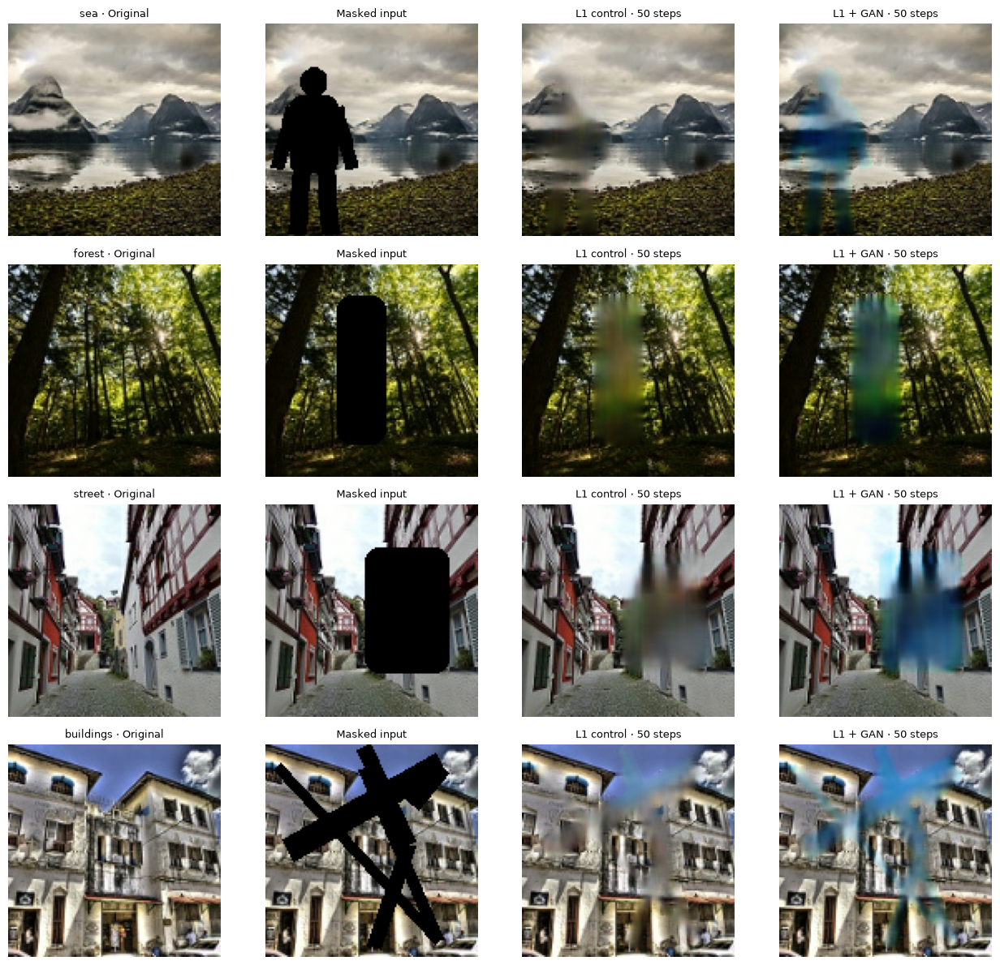

In [58]:
saved_panel = pd.read_csv(RECORD_DIR / "visual_panel_60.csv")
saved_masks = np.load(
    RECORD_DIR / "validation_mixed_masks.npz"
)["masks"]

preview_rows = pd.concat([
    saved_panel[
        (saved_panel["category"] == category)
        & (saved_panel["coverage_group"] == "Higher coverage")
    ].sort_values("panel_id").head(1)
    for category in SELECTED_CLASSES
])

preview_originals = np.stack([
    load_image(str(PROJECT_ROOT / path)).numpy()
    for path in preview_rows["path"]
])

preview_masks = saved_masks[
    preview_rows["mask_index"].to_numpy()
].astype(np.float32)

preview_masked = preview_originals * (1 - preview_masks)
preview_inputs = np.concatenate(
    [preview_masked, preview_masks], axis=-1
)

control_preview = l1_generator(preview_inputs, training=False).numpy()
gan_preview = gan_generator(preview_inputs, training=False).numpy()

control_preview = preview_masked + control_preview * preview_masks
gan_preview = preview_masked + gan_preview * preview_masks

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (preview_originals[i], f"{category} · Original"),
        (preview_masked[i], "Masked input"),
        (control_preview[i], "L1 control · 50 steps"),
        (gan_preview[i], "L1 + GAN · 50 steps"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Adversarial Pilot: Early Deterioration

After 50 updates, the weighted adversarial-to-MAE gradient norm ratio
on the calibration batch increased from 0.2 to 4.106.

The adversarial generator's masked MAE on that batch was 0.10359,
compared with 0.07377 for the L1 control. Visual examples show strong
color shifts without a clear improvement in texture.

The initial calibration using a randomly initialized discriminator
did not maintain a stable gradient balance. Stop this pilot and
retain it as an unsuccessful configuration, not as evidence that
adversarial training cannot work.

In [59]:
pd.DataFrame(experiment_log).to_csv(
    RECORD_DIR / "gan_pilot_50_steps.csv",
    index=False,
)

pilot_findings = {
    "generator_updates": 50,
    "adversarial_weight": float(ADV_WEIGHT),
    "initial_gradient_ratio": 0.2,
    "measured_gradient_ratio": float(current_ratio),
    "control_calibration_mae": float(
        masked_mae(check_targets, control_predictions)
    ),
    "gan_calibration_mae": float(check_mae),
    "decision": "Stop pilot: color artifacts and increased reconstruction error",
}

(RECORD_DIR / "gan_pilot_findings.json").write_text(
    json.dumps(pilot_findings, indent=2),
    encoding="utf-8",
)

329

## Adversarial Retry: Lower Weight and Gradient Monitoring

Restart both generators from the same MAE-trained checkpoint.
Create a fresh discriminator and fresh optimizers.

Use an adversarial weight of 0.03 and pass it explicitly as a tensor
to the training function. Monitor the adversarial-to-MAE gradient
norm ratio during the pilot.

This retry also uses a new discriminator initialization, so differences
from the failed pilot cannot be attributed exclusively to the weight.
Run 50 updates per arm before deciding whether to continue.

In [60]:
keras.utils.set_random_seed(2031)

retry_control = keras.models.load_model(reference_path, compile=False)
retry_generator = keras.models.load_model(reference_path, compile=False)

for generator in [retry_control, retry_generator]:
    for layer in generator.layers:
        if isinstance(layer, keras.layers.Dropout):
            layer.rate = 0.0

# Same discriminator architecture, fresh random weights.
retry_discriminator = keras.models.clone_model(discriminator)

retry_control_optimizer = keras.optimizers.Adam(learning_rate=1e-4)
retry_generator_optimizer = keras.optimizers.Adam(learning_rate=1e-4)
retry_discriminator_optimizer = keras.optimizers.Adam(learning_rate=1e-4)

RETRY_ADV_WEIGHT = tf.constant(0.03, dtype=tf.float32)

### Define Fresh Training Functions

Use separate traced functions for this retry to avoid retaining models,
optimizers, or Python constants from the previous experiment.

Measure gradient norms with respect to the predicted image after the
discriminator update and before the generator update. These ratios
describe the current training batch, not the full dataset.

In [61]:
@tf.function
def retry_control_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = retry_control(inputs, training=True)
        loss = masked_mae(targets, predictions)

    gradients = tape.gradient(loss, retry_control.trainable_variables)
    retry_control_optimizer.apply_gradients(
        zip(gradients, retry_control.trainable_variables)
    )
    return loss


@tf.function
def retry_gan_step(inputs, targets, adv_weight):
    originals = targets[..., :3]
    masks = targets[..., 3:]
    weights = discriminator_patch_mask(masks)

    predictions = tf.stop_gradient(
        retry_generator(inputs, training=False)
    )
    composite = originals * (1 - masks) + predictions * masks

    # Update discriminator.
    with tf.GradientTape() as tape:
        real_scores = retry_discriminator(
            tf.concat([originals, masks], axis=-1), training=True
        )
        fake_scores = retry_discriminator(
            tf.concat([composite, masks], axis=-1), training=True
        )
        d_loss = discriminator_loss(real_scores, fake_scores, weights)

    gradients = tape.gradient(
        d_loss, retry_discriminator.trainable_variables
    )
    retry_discriminator_optimizer.apply_gradients(
        zip(gradients, retry_discriminator.trainable_variables)
    )

    # Update generator and measure its loss-gradient balance.
    with tf.GradientTape(persistent=True) as tape:
        predictions = retry_generator(inputs, training=True)
        tape.watch(predictions)

        composite = originals * (1 - masks) + predictions * masks

        fake_scores = retry_discriminator(
            tf.concat([composite, masks], axis=-1), training=False
        )

        g_mae = masked_mae(targets, predictions)
        g_adv = generator_adversarial_loss(fake_scores, weights)
        g_total = g_mae + adv_weight * g_adv

    l1_norm = tf.linalg.norm(tape.gradient(g_mae, predictions))
    adv_norm = tf.linalg.norm(tape.gradient(g_adv, predictions))

    gradients = tape.gradient(
        g_total, retry_generator.trainable_variables
    )
    del tape

    retry_generator_optimizer.apply_gradients(
        zip(gradients, retry_generator.trainable_variables)
    )

    ratio = tf.math.divide_no_nan(adv_weight * adv_norm, l1_norm)

    return {
        "gan_mae": g_mae,
        "discriminator_loss": d_loss,
        "generator_adversarial_loss": g_adv,
        "weighted_gradient_ratio": ratio,
    }

### Run the Retry Pilot

Train both arms on the same first 50 deterministic batches.
Log reconstruction error, discriminator loss, and gradient balance.

Keep the adversarial coefficient fixed during this pilot. Review the
logs and fixed validation previews before extending the run.

In [62]:
retry_log = []
retry_start = time.perf_counter()

for step in range(50):
    batch_inputs, batch_targets = experiment_batch(step)

    control_loss = retry_control_step(batch_inputs, batch_targets)
    gan_values = retry_gan_step(
        batch_inputs, batch_targets, RETRY_ADV_WEIGHT
    )

    row = {
        "step": step + 1,
        "control_mae": float(control_loss),
        **{name: float(value) for name, value in gan_values.items()},
        "elapsed_seconds": time.perf_counter() - retry_start,
    }
    retry_log.append(row)

    if (step + 1) % 10 == 0:
        print(
            f"Step {step + 1:3d} | "
            f"Control MAE: {row['control_mae']:.4f} | "
            f"GAN MAE: {row['gan_mae']:.4f} | "
            f"D loss: {row['discriminator_loss']:.4f} | "
            f"Gradient ratio: {row['weighted_gradient_ratio']:.3f}"
        )

pd.DataFrame(retry_log).to_csv(
    RECORD_DIR / "gan_retry_training_log.csv",
    index=False,
)

Step  10 | Control MAE: 0.1087 | GAN MAE: 0.1086 | D loss: 1.9935 | Gradient ratio: 0.016
Step  20 | Control MAE: 0.1133 | GAN MAE: 0.1133 | D loss: 1.9897 | Gradient ratio: 0.023
Step  30 | Control MAE: 0.0881 | GAN MAE: 0.0881 | D loss: 1.9815 | Gradient ratio: 0.043
Step  40 | Control MAE: 0.1054 | GAN MAE: 0.1054 | D loss: 1.9579 | Gradient ratio: 0.083
Step  50 | Control MAE: 0.0909 | GAN MAE: 0.0911 | D loss: 1.9472 | Gradient ratio: 0.182


### Inspect the Lower-Weight Adversarial Pilot

After 50 updates, the adversarial generator's training MAE remains
close to the matched L1 control.

The weighted gradient norm ratio increased from 0.016 to 0.182 across
the reported batches. Continue monitoring this trend; the pilot does
not yet establish stable long-term training or perceptual improvement.

Inspect the same fixed validation examples used in the previous pilot,
looking for color shifts, new artifacts, and useful texture.

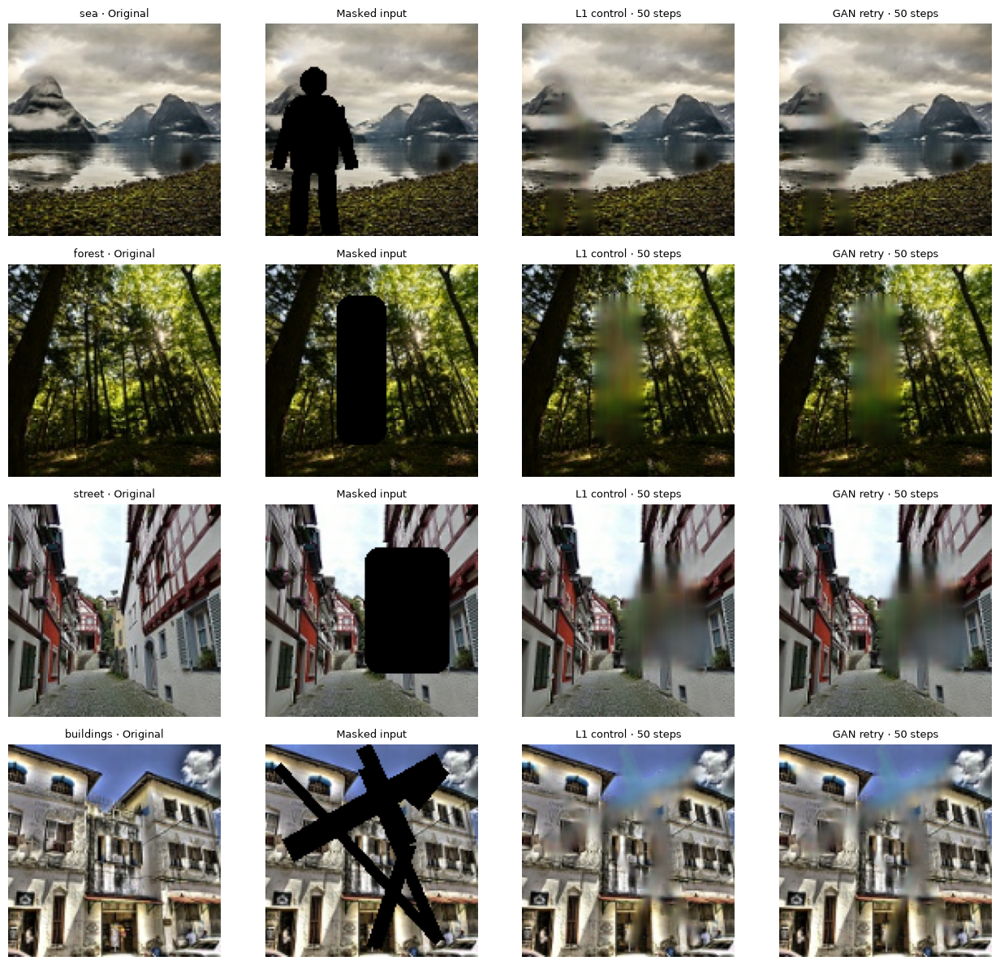

In [63]:
retry_control_predictions = retry_control(
    preview_inputs, training=False
).numpy()

retry_gan_predictions = retry_generator(
    preview_inputs, training=False
).numpy()

retry_visible = preview_originals * (1 - preview_masks)

retry_control_results = (
    retry_visible + retry_control_predictions * preview_masks
)
retry_gan_results = (
    retry_visible + retry_gan_predictions * preview_masks
)

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (preview_originals[i], f"{category} · Original"),
        (retry_visible[i], "Masked input"),
        (retry_control_results[i], "L1 control · 50 steps"),
        (retry_gan_results[i], "GAN retry · 50 steps"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Continue the Adversarial Retry to 200 Updates

The 50-step preview shows no obvious color shifts like those observed
in the failed pilot, but no clear texture improvement either.

Continue both arms with identical batches and a fixed adversarial
weight of 0.03. Report averages over 50-step windows rather than
judging individual batches.

Save both generators, the discriminator, optimizer states, and the
completed-step counter. This is an intermediate checkpoint within
the planned 1,500-update budget.

In [64]:
retry_checkpoint_dir = MODEL_DIR / "gan_retry"
retry_checkpoint_dir.mkdir(exist_ok=True)

retry_completed_steps = tf.Variable(
    len(retry_log), dtype=tf.int64, trainable=False
)

retry_checkpoint = tf.train.Checkpoint(
    step=retry_completed_steps,
    adversarial_weight=tf.Variable(RETRY_ADV_WEIGHT, trainable=False),
    control=retry_control,
    generator=retry_generator,
    discriminator=retry_discriminator,
    control_optimizer=retry_control_optimizer,
    generator_optimizer=retry_generator_optimizer,
    discriminator_optimizer=retry_discriminator_optimizer,
)

retry_manager = tf.train.CheckpointManager(
    retry_checkpoint,
    directory=str(retry_checkpoint_dir),
    max_to_keep=3,
)

retry_manager.save(
    checkpoint_number=int(retry_completed_steps.numpy())
)

'/Users/mateocordoba/dev/projects/photo-retouch/models/gan_retry/ckpt-50'

In [65]:
for step in range(int(retry_completed_steps.numpy()), 200):
    batch_inputs, batch_targets = experiment_batch(step)

    control_loss = retry_control_step(batch_inputs, batch_targets)
    gan_values = retry_gan_step(
        batch_inputs,
        batch_targets,
        retry_checkpoint.adversarial_weight,
    )

    row = {
        "step": step + 1,
        "control_mae": float(control_loss),
        **{name: float(value) for name, value in gan_values.items()},
        "elapsed_seconds": time.perf_counter() - retry_start,
    }

    retry_log.append(row)
    retry_completed_steps.assign(step + 1)

    if (step + 1) % 50 == 0:
        window = pd.DataFrame(retry_log[-50:])

        print(
            f"Steps {step - 48}–{step + 1} | "
            f"Control MAE: {window['control_mae'].mean():.4f} | "
            f"GAN MAE: {window['gan_mae'].mean():.4f} | "
            f"D loss: {window['discriminator_loss'].mean():.4f} | "
            f"Gradient ratio mean/max: "
            f"{window['weighted_gradient_ratio'].mean():.3f}/"
            f"{window['weighted_gradient_ratio'].max():.3f}"
        )

        pd.DataFrame(retry_log).to_csv(
            RECORD_DIR / "gan_retry_training_log.csv",
            index=False,
        )

        retry_manager.save(checkpoint_number=step + 1)

Steps 51–100 | Control MAE: 0.0933 | GAN MAE: 0.0935 | D loss: 1.8667 | Gradient ratio mean/max: 0.296/0.485
Steps 101–150 | Control MAE: 0.0923 | GAN MAE: 0.0927 | D loss: 1.8039 | Gradient ratio mean/max: 0.474/0.851
Steps 151–200 | Control MAE: 0.0943 | GAN MAE: 0.0950 | D loss: 1.7583 | Gradient ratio mean/max: 0.614/0.835


### Visual Check After 200 Updates

The adversarial generator's training MAE remains close to the control,
while its relative adversarial gradient magnitude has increased.

Inspect the fixed validation examples for useful texture, color drift,
and repeated artifacts. Training statistics alone do not establish
perceptual improvement.

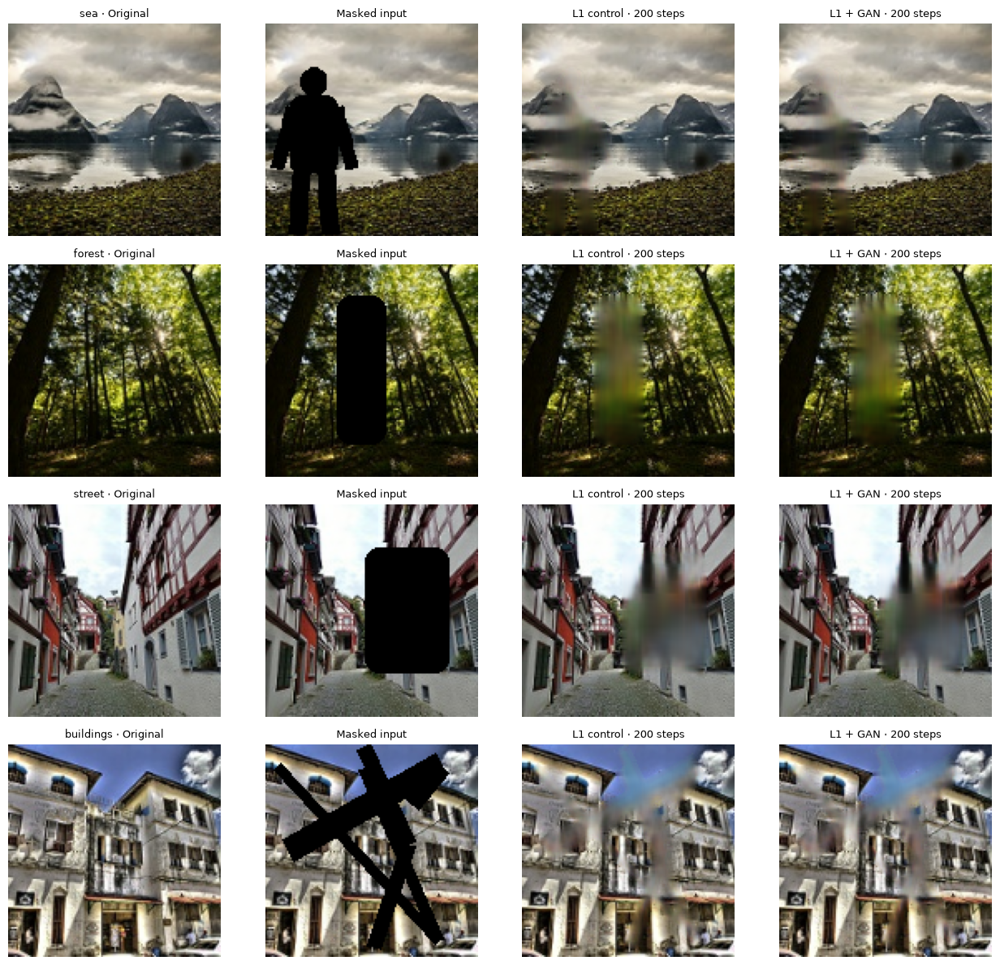

In [66]:
control_200 = retry_control(
    preview_inputs, training=False
).numpy()

gan_200 = retry_generator(
    preview_inputs, training=False
).numpy()

visible_200 = preview_originals * (1 - preview_masks)
control_200 = visible_200 + control_200 * preview_masks
gan_200 = visible_200 + gan_200 * preview_masks

fig, axes = plt.subplots(4, 4, figsize=(13, 12))

for i, category in enumerate(SELECTED_CLASSES):
    panels = [
        (preview_originals[i], f"{category} · Original"),
        (visible_200[i], "Masked input"),
        (control_200[i], "L1 control · 200 steps"),
        (gan_200[i], "L1 + GAN · 200 steps"),
    ]

    for ax, (image, title) in zip(axes[i], panels):
        ax.imshow(image)
        ax.set_title(title, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Complete the Fixed Training Budget

The 200-step preview shows no clear perceptual advantage for the
adversarial model, but also no obvious color failure like the first pilot.

Continue both arms to 1,500 total generator updates without changing
the adversarial weight, learning rates, or data schedule.

Save intermediate checkpoints and logs. Judge the final result using
the predefined evaluation panel rather than repeatedly tuning settings
against the same four examples.

In [67]:
for step in range(int(retry_completed_steps.numpy()), 1500):
    step_start = time.perf_counter()
    batch_inputs, batch_targets = experiment_batch(step)

    control_loss = retry_control_step(batch_inputs, batch_targets)
    gan_values = retry_gan_step(
        batch_inputs,
        batch_targets,
        retry_checkpoint.adversarial_weight,
    )

    row = {
        "step": step + 1,
        "control_mae": float(control_loss),
        **{name: float(value) for name, value in gan_values.items()},
        "update_seconds": time.perf_counter() - step_start,
    }

    retry_log.append(row)
    retry_completed_steps.assign(step + 1)

    if (step + 1) % 50 == 0:
        window = pd.DataFrame(retry_log[-50:])

        print(
            f"Steps {step - 48}–{step + 1} | "
            f"Control MAE: {window['control_mae'].mean():.4f} | "
            f"GAN MAE: {window['gan_mae'].mean():.4f} | "
            f"D loss: {window['discriminator_loss'].mean():.4f} | "
            f"Gradient ratio mean/max: "
            f"{window['weighted_gradient_ratio'].mean():.3f}/"
            f"{window['weighted_gradient_ratio'].max():.3f}"
        )

        pd.DataFrame(retry_log).to_csv(
            RECORD_DIR / "gan_retry_training_log.csv",
            index=False,
        )

        retry_manager.save(checkpoint_number=step + 1)

Steps 201–250 | Control MAE: 0.0936 | GAN MAE: 0.0950 | D loss: 1.7232 | Gradient ratio mean/max: 0.831/1.106
Steps 251–300 | Control MAE: 0.0948 | GAN MAE: 0.0966 | D loss: 1.7511 | Gradient ratio mean/max: 0.778/1.212
Steps 301–350 | Control MAE: 0.0973 | GAN MAE: 0.0995 | D loss: 1.7174 | Gradient ratio mean/max: 0.853/1.100
Steps 351–400 | Control MAE: 0.0942 | GAN MAE: 0.0976 | D loss: 1.7328 | Gradient ratio mean/max: 0.941/1.136
Steps 401–450 | Control MAE: 0.0931 | GAN MAE: 0.0976 | D loss: 1.7612 | Gradient ratio mean/max: 0.891/1.100
Steps 451–500 | Control MAE: 0.0938 | GAN MAE: 0.0992 | D loss: 1.7560 | Gradient ratio mean/max: 0.943/1.133
Steps 501–550 | Control MAE: 0.0967 | GAN MAE: 0.1017 | D loss: 1.7237 | Gradient ratio mean/max: 0.924/1.172
Steps 551–600 | Control MAE: 0.0934 | GAN MAE: 0.1000 | D loss: 1.7470 | Gradient ratio mean/max: 1.125/1.598
Steps 601–650 | Control MAE: 0.0941 | GAN MAE: 0.1009 | D loss: 1.7534 | Gradient ratio mean/max: 1.182/1.525
Steps 651–

### Export the Final Generators

Save both generators after the same number of updates.
The discriminator is not needed for inference. Full training state
remains available in the experiment checkpoints.

In [68]:
retry_control.save(
    MODEL_DIR / "l1_control_1500.keras"
)

retry_generator.save(
    MODEL_DIR / "gan_retry_1500.keras"
)

print("Completed updates per generator:", int(retry_completed_steps.numpy()))

Completed updates per generator: 1500


## Evaluate the Completed Adversarial Experiment

Compare both generators after 1,500 matched updates using the saved
validation images and masks.

Report mean masked MAE per image and a gradient-magnitude ratio inside
the eroded hole, relative to the original image.

The gradient ratio is a texture diagnostic, not a quality score:
noise and artifacts can increase it. A ratio near one does not imply
correct reconstruction. Visual evaluation remains necessary.

In [69]:
import cv2

# Preserve the final generators.
retry_control.save(MODEL_DIR / "l1_control_1500.keras")
retry_generator.save(MODEL_DIR / "gan_retry_1500.keras")

evaluation_manifest = pd.read_csv(RECORD_DIR / "validation_400.csv")
evaluation_masks = np.load(
    RECORD_DIR / "validation_mixed_masks.npz"
)["masks"].astype(np.float32)


def hole_gradient_ratio(original, reconstructed, mask):
    interior = cv2.erode(
        mask[..., 0].astype(np.uint8),
        np.ones((5, 5), np.uint8),
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    ).astype(bool)

    if interior.sum() < 20:
        return np.nan

    def gradient_magnitude(image):
        gray = image.mean(axis=-1)
        dy, dx = np.gradient(gray)
        return np.sqrt(dx**2 + dy**2)

    reference = gradient_magnitude(original)[interior].mean()

    if reference < 1e-6:
        return np.nan

    return gradient_magnitude(reconstructed)[interior].mean() / reference


evaluation_rows = []

for start in range(0, len(evaluation_manifest), 16):
    batch_manifest = evaluation_manifest.iloc[start:start + 16]

    images = np.stack([
        load_image(str(PROJECT_ROOT / path)).numpy()
        for path in batch_manifest["path"]
    ])

    masks = evaluation_masks[start:start + len(images)]
    visible = images * (1 - masks)
    inputs = np.concatenate([visible, masks], axis=-1)

    for method, generator in [
        ("L1 control", retry_control),
        ("L1 + GAN", retry_generator),
    ]:
        predictions = generator(inputs, training=False).numpy()
        reconstructed = visible + predictions * masks

        for i in range(len(images)):
            evaluation_rows.append({
                "image_index": start + i,
                "category": batch_manifest.iloc[i]["category"],
                "method": method,
                "masked_mae": (
                    np.abs(images[i] - reconstructed[i]) * masks[i]
                ).sum() / (3 * masks[i].sum()),
                "gradient_ratio": hole_gradient_ratio(
                    images[i], reconstructed[i], masks[i]
                ),
            })

adversarial_evaluation = pd.DataFrame(evaluation_rows)

adversarial_evaluation.to_csv(
    RECORD_DIR / "adversarial_validation_1500.csv",
    index=False,
)

### Summarize Reconstruction Error and Texture

Compare mean per-image MAE and median gradient ratio across methods.
Report the number of valid texture measurements because nearly uniform
reference regions and very small mask interiors are excluded.

Use paired visual comparisons to determine whether increased texture
is useful or consists of artifacts.

In [70]:
display(
    adversarial_evaluation.groupby("method").agg(
        mean_masked_mae=("masked_mae", "mean"),
        median_gradient_ratio=("gradient_ratio", "median"),
        valid_gradient_measurements=("gradient_ratio", "count"),
    )
)

display(
    adversarial_evaluation.pivot_table(
        index="category",
        columns="method",
        values="masked_mae",
        aggfunc="mean",
    )
)

,mean_masked_mae,median_gradient_ratio,valid_gradient_measurements
method,,,
L1 + GAN,0.104539,0.758928,399
L1 control,0.092902,0.288068,399


method,L1 + GAN,L1 control
category,,
buildings,0.116099,0.106282
forest,0.112739,0.094834
sea,0.067098,0.060971
street,0.122221,0.109520


### Blind Visual Comparison

The adversarial model increased median gradient magnitude but also
increased mean masked MAE by approximately 12.5% relative to the control.

Evaluate the predefined 60-image panel with randomized A/B placement.
Use the original and masked input as references. Judge overall usefulness:
plausible structure, texture, color consistency, and visible artifacts.

Record A, B, or Tie before opening the method key. More texture alone
is not sufficient to prefer a reconstruction.

In [71]:
blind_panel = pd.read_csv(RECORD_DIR / "visual_panel_60.csv")

blind_originals = np.stack([
    load_image(str(PROJECT_ROOT / path)).numpy()
    for path in blind_panel["path"]
])

blind_masks = evaluation_masks[
    blind_panel["mask_index"].to_numpy()
]

blind_visible = blind_originals * (1 - blind_masks)
blind_inputs = np.concatenate([blind_visible, blind_masks], axis=-1)

blind_control = retry_control.predict(
    blind_inputs, batch_size=16, verbose=0
)
blind_gan = retry_generator.predict(
    blind_inputs, batch_size=16, verbose=0
)

blind_control = blind_visible + blind_control * blind_masks
blind_gan = blind_visible + blind_gan * blind_masks

blind_rng = np.random.default_rng(2032)
gan_on_a = blind_rng.integers(0, 2, len(blind_panel)).astype(bool)

BLIND_DIR = RECORD_DIR / "blind_review"
BLIND_DIR.mkdir(exist_ok=True)

# Save the key without displaying it.
pd.DataFrame({
    "panel_id": blind_panel["panel_id"],
    "A": np.where(gan_on_a, "GAN", "L1"),
    "B": np.where(gan_on_a, "L1", "GAN"),
}).to_csv(BLIND_DIR / "method_key.csv", index=False)

ratings_path = BLIND_DIR / "ratings.csv"

if not ratings_path.exists():
    pd.DataFrame({
        "panel_id": blind_panel["panel_id"],
        "choice": "",
        "notes": "",
    }).to_csv(ratings_path, index=False)

### Export the Review Pages

Create ten pages with six examples each. Show the masked region with
a surrounding margin, using the same crop for all four columns.

Record preferences in ratings.csv. Keep method_key.csv closed until
the ratings are complete. These are development-set judgments, not
independent final-test results.

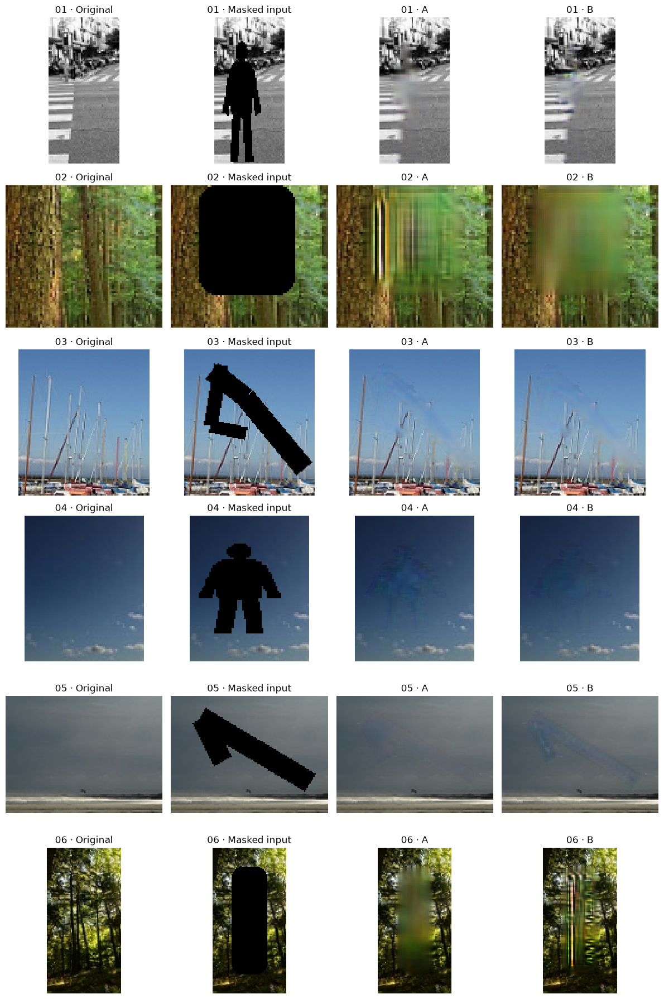

Review pages and ratings file: /Users/mateocordoba/dev/projects/photo-retouch/records/20261117T213223_080287Z/blind_review


In [72]:
for page_start in range(0, len(blind_panel), 6):
    fig, axes = plt.subplots(6, 4, figsize=(12, 18))

    for row, i in enumerate(range(page_start, page_start + 6)):
        ys, xs = np.where(blind_masks[i, ..., 0] > 0)

        y0, y1 = max(0, ys.min() - 16), min(128, ys.max() + 17)
        x0, x1 = max(0, xs.min() - 16), min(128, xs.max() + 17)

        image_a = blind_gan[i] if gan_on_a[i] else blind_control[i]
        image_b = blind_control[i] if gan_on_a[i] else blind_gan[i]

        panels = [
            (blind_originals[i], "Original"),
            (blind_visible[i], "Masked input"),
            (image_a, "A"),
            (image_b, "B"),
        ]

        panel_id = int(blind_panel.iloc[i]["panel_id"])

        for ax, (image, title) in zip(axes[row], panels):
            ax.imshow(image[y0:y1, x0:x1], interpolation="nearest")
            ax.set_title(f"{panel_id:02d} · {title}")
            ax.axis("off")

    plt.tight_layout()

    page_number = page_start // 6 + 1
    fig.savefig(
        BLIND_DIR / f"page_{page_number:02d}.png",
        dpi=150,
        bbox_inches="tight",
    )

    if page_start == 0:
        plt.show()

    plt.close(fig)

print(f"Review pages and ratings file: {BLIND_DIR}")

## Diagnostic: Evaluation Metrics and the L1 Ceiling

Mean masked MAE has guided every decision so far. When the hidden content
is uncertain, an L1 objective is minimized by the per-pixel median of the
plausible fills, which favors blur. MAE as an evaluation metric rewards
the same behavior, so a sharper but slightly misplaced texture scores worse
than a smooth average.

The inpainting literature reports perceptual and distribution metrics
alongside pixel error. This section adds two of them and tests whether
L1 training is approaching the limit of what pixel error can reward.

No model is trained. All methods use the frozen validation images and
mixed masks from the experiment snapshot. The blind-review key is not read.

### Load the Frozen Validation Setup

Read the 400 validation images and their saved mixed masks from the most
recent snapshot. The section defines its own paths and loader so it can
run after a kernel restart without re-executing earlier experiments.

Preprocessing matches the training pipeline: decode, convert to [0, 1],
and resize to 128 × 128.

In [ ]:
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

current_dir = Path.cwd().resolve()
PROJECT_ROOT = next(
    folder
    for folder in (current_dir, *current_dir.parents)
    if (folder / "requirements.txt").is_file()
    and (folder / "notebooks").is_dir()
)
MODEL_DIR = PROJECT_ROOT / "models"

# Most recent snapshot that contains the fixed validation masks.
EVAL_RECORD_DIR = sorted(
    path.parent
    for path in (PROJECT_ROOT / "records").glob(
        "*/validation_mixed_masks.npz"
    )
)[-1]
DIAGNOSTIC_DIR = EVAL_RECORD_DIR / "diagnostics"
DIAGNOSTIC_DIR.mkdir(exist_ok=True)

eval_manifest = pd.read_csv(EVAL_RECORD_DIR / "validation_400.csv")
eval_masks = np.load(
    EVAL_RECORD_DIR / "validation_mixed_masks.npz"
)["masks"].astype(np.float32)


def load_eval_image(path):
    image = tf.io.read_file(str(path))
    image = tf.io.decode_jpeg(image, channels=3)
    image = tf.image.convert_image_dtype(image, tf.float32)
    return tf.image.resize(image, (128, 128)).numpy()


eval_originals = np.stack([
    load_eval_image(PROJECT_ROOT / path)
    for path in eval_manifest["path"]
])
eval_visible = eval_originals * (1 - eval_masks)
eval_inputs = np.concatenate([eval_visible, eval_masks], axis=-1)

assert len(eval_originals) == len(eval_masks) == 400

print(f"Snapshot: {EVAL_RECORD_DIR.name}")
print(f"Validation images: {len(eval_originals)}")
print(f"Mean hole coverage: {eval_masks.mean():.1%}")

Snapshot: 20261117T213223_080287Z
Validation images: 400
Mean hole coverage: 13.7%


### Reconstruct the Validation Set with Every Method

Run the saved generators and OpenCV Telea on identical inputs. Every
result is composed the same way as in the application: original pixels
outside the hole, method output inside it.

The perceptual model is the MAE reference architecture with the weights
saved by the three-epoch perceptual trial.

In [ ]:
def compose(fill):
    # Keep original pixels outside the hole.
    return eval_visible + fill * eval_masks


generator_files = {
    "Deep U-Net (MAE reference)": (
        "best_deep_unet_6000_tuned.keras", None
    ),
    "MAE + perceptual": (
        "best_deep_unet_6000_tuned.keras",
        "best_perceptual_unet.weights.h5",
    ),
    "L1 control (1,500 updates)": ("l1_control_1500.keras", None),
    "L1 + GAN (1,500 updates)": ("gan_retry_1500.keras", None),
}

method_results = {}

for name, (filename, weights) in generator_files.items():
    generator = keras.models.load_model(
        MODEL_DIR / filename, compile=False
    )
    if weights is not None:
        generator.load_weights(MODEL_DIR / weights)

    method_results[name] = compose(
        generator.predict(eval_inputs, batch_size=16, verbose=0)
    )
    del generator

method_results["OpenCV Telea"] = compose(np.stack([
    cv2.inpaint(
        np.round(visible * 255).astype(np.uint8),
        (mask[..., 0] * 255).astype(np.uint8),
        inpaintRadius=3,
        flags=cv2.INPAINT_TELEA,
    ).astype(np.float32) / 255
    for visible, mask in zip(eval_visible, eval_masks)
]))

print("Methods:", list(method_results))

Methods: ['Deep U-Net (MAE reference)', 'MAE + perceptual', 'L1 control (1,500 updates)', 'L1 + GAN (1,500 updates)', 'OpenCV Telea']


### Build Reference Fills from the Ground Truth

These oracles use the hidden pixels, so no real method can produce them.
They show how each metric responds to known kinds of error:

- **Blurred truth:** the correct image blurred with a Gaussian of width σ.
  It has the right colors and layout but progressively less texture.
- **Constant truth median:** the per-image, per-channel median of the
  hidden pixels. It is the best constant fill under L1.
- **Shifted truth:** the same photograph moved 16 pixels. Its texture is
  realistic but misaligned with the true content.

If a metric prefers heavy blur over realistic but shifted texture, it
cannot be used alone to judge visual quality.

In [ ]:
def gaussian_blur(images, sigma):
    return np.stack([
        cv2.GaussianBlur(
            image, (0, 0), sigmaX=sigma,
            borderType=cv2.BORDER_REFLECT,
        )
        for image in images
    ])


ORACLE_SIGMAS = [0.5, 1, 2, 3, 4, 6, 8, 12]
oracle_results = {}

for sigma in ORACLE_SIGMAS:
    oracle_results[f"Blurred truth σ={sigma:g}"] = compose(
        gaussian_blur(eval_originals, sigma)
    )

constant_fill = np.stack([
    np.broadcast_to(
        np.median(image[mask[..., 0] > 0.5], axis=0),
        image.shape,
    )
    for image, mask in zip(eval_originals, eval_masks)
])
oracle_results["Constant truth median"] = compose(constant_fill)

oracle_results["Shifted truth (16 px)"] = compose(
    np.roll(eval_originals, shift=(16, 16), axis=(1, 2))
)

print("Oracles:", list(oracle_results))

Oracles: ['Blurred truth σ=0.5', 'Blurred truth σ=1', 'Blurred truth σ=2', 'Blurred truth σ=3', 'Blurred truth σ=4', 'Blurred truth σ=6', 'Blurred truth σ=8', 'Blurred truth σ=12', 'Constant truth median', 'Shifted truth (16 px)']


### Pixel Error and Its Frequency Components

Compute masked MAE per image, as in earlier sections.

Then split each image into a low-frequency part (Gaussian blur, σ = 2)
and a high-frequency residual. Measuring the error of each part inside
the hole separates wrong colors and layout from missing or wrong texture.

The texture ratio compares the high-frequency energy of the fill with
that of the true image inside the eroded hole. Values well below one
indicate a smoothed fill; values near one do not guarantee correct texture.

In [ ]:
FREQUENCY_SIGMA = 2.0

original_low = gaussian_blur(eval_originals, FREQUENCY_SIGMA)
original_high = eval_originals - original_low
hole_values = 3 * eval_masks.sum(axis=(1, 2, 3))

# Exclude the seam, where the high-pass filter mixes both sides.
eval_interior = np.stack([
    cv2.erode(
        mask[..., 0].astype(np.uint8),
        np.ones((5, 5), np.uint8),
        borderType=cv2.BORDER_CONSTANT,
        borderValue=0,
    )
    for mask in eval_masks
]).astype(np.float32)[..., None]
interior_pixels = eval_interior.sum(axis=(1, 2, 3))


def masked_mae_per_image(results):
    error = np.abs(results - eval_originals) * eval_masks
    return error.sum(axis=(1, 2, 3)) / hole_values


def frequency_errors(results):
    low = gaussian_blur(results, FREQUENCY_SIGMA)
    high = results - low

    low_error = (
        np.abs(low - original_low) * eval_masks
    ).sum(axis=(1, 2, 3)) / hole_values
    high_error = (
        np.abs(high - original_high) * eval_masks
    ).sum(axis=(1, 2, 3)) / hole_values

    with np.errstate(divide="ignore", invalid="ignore"):
        texture_ratio = (
            (np.abs(high) * eval_interior).sum(axis=(1, 2, 3))
            / (np.abs(original_high) * eval_interior).sum(axis=(1, 2, 3))
        )
    texture_ratio[interior_pixels < 20] = np.nan

    return low_error, high_error, texture_ratio

### Perceptual Distance

Compare frozen VGG16 activations of each composed image and its original
at five depths. Following the LPIPS formulation, normalize every feature
vector to unit length, take squared differences, average over space, and
add the layers with equal weights.

This is the unlearned variant of LPIPS: the official metric adds linear
weights calibrated on human judgments, which are distributed for PyTorch
only. Lower is closer. The MAE + perceptual model was trained with VGG16
features, so its score on this metric is not fully independent.

In [ ]:
vgg = keras.applications.VGG16(
    include_top=False, weights="imagenet", input_shape=(128, 128, 3)
)
DISTANCE_LAYERS = [
    "block1_conv2", "block2_conv2", "block3_conv3",
    "block4_conv3", "block5_conv3",
]
distance_features = keras.Model(
    vgg.input, [vgg.get_layer(name).output for name in DISTANCE_LAYERS]
)
distance_features.trainable = False

VGG_MEAN_BGR = tf.constant([103.939, 116.779, 123.68])


def vgg_preprocess(images):
    return images[..., ::-1] * 255.0 - VGG_MEAN_BGR


@tf.function
def feature_distance_batch(results, originals):
    result_features = distance_features(
        vgg_preprocess(results), training=False
    )
    original_features = distance_features(
        vgg_preprocess(originals), training=False
    )

    total = 0.0
    for a, b in zip(result_features, original_features):
        a = a / (tf.norm(a, axis=-1, keepdims=True) + 1e-10)
        b = b / (tf.norm(b, axis=-1, keepdims=True) + 1e-10)
        total += tf.reduce_mean(
            tf.reduce_sum(tf.square(a - b), axis=-1), axis=[1, 2]
        )
    return total


def feature_distance(results, batch_size=50):
    return np.concatenate([
        feature_distance_batch(
            tf.constant(results[start:start + batch_size]),
            tf.constant(eval_originals[start:start + batch_size]),
        ).numpy()
        for start in range(0, len(results), batch_size)
    ])

### Kernel Inception Distance

KID compares the distribution of InceptionV3 features of the composed
images with that of the original images. Unlike FID, its estimator is
unbiased, which matters with only 400 validation images.

Use a cubic polynomial kernel, 100 random subsets of 100 images, and the
same subset indices for every method. Report KID × 1000 with its standard
deviation across subsets. The standard deviation describes subset-sampling
variability, not a confidence interval. Images are upsampled from 128 to 299 pixels, so
values are only comparable within this notebook.

In [ ]:
inception = keras.applications.InceptionV3(
    include_top=False,
    weights="imagenet",
    pooling="avg",
    input_shape=(299, 299, 3),
)


@tf.function
def inception_batch(images):
    resized = tf.image.resize(images, (299, 299), method="bilinear")
    return inception(resized * 2.0 - 1.0, training=False)


def inception_features(images, batch_size=50):
    return np.concatenate([
        inception_batch(
            tf.constant(images[start:start + batch_size])
        ).numpy()
        for start in range(0, len(images), batch_size)
    ]).astype(np.float64)


def kernel_inception_distance(
    real, fake, subset_size=100, subsets=100, seed=2033
):
    rng = np.random.default_rng(seed)
    dimension = real.shape[1]
    m = subset_size
    estimates = []

    for _ in range(subsets):
        x = real[rng.choice(len(real), m, replace=False)]
        y = fake[rng.choice(len(fake), m, replace=False)]

        # NumPy 2.0 with Apple Accelerate emits spurious floating-point
        # warnings in matmul; the products are checked explicitly instead.
        with np.errstate(divide="ignore", over="ignore", invalid="ignore"):
            k_xx = (x @ x.T / dimension + 1) ** 3
            k_yy = (y @ y.T / dimension + 1) ** 3
            k_xy = (x @ y.T / dimension + 1) ** 3
        assert np.isfinite([k_xx, k_yy, k_xy]).all()

        estimates.append(
            (k_xx.sum() - np.trace(k_xx)) / (m * (m - 1))
            + (k_yy.sum() - np.trace(k_yy)) / (m * (m - 1))
            - 2 * k_xy.mean()
        )

    # Same seed for every method, so estimates are paired by subset.
    return np.array(estimates)


real_inception = inception_features(eval_originals)

### Evaluate Methods and Oracles

Apply every metric to the same 400 composed images. Save one row per
image and method, plus the summary table, to the snapshot's diagnostics
folder.

In [ ]:
method_kind = {
    **{name: "Model" for name in generator_files},
    "OpenCV Telea": "Baseline",
    **{name: "Oracle" for name in oracle_results},
}

summary_rows = []
per_image_rows = []
kid_estimates = {}

for name, results in {**method_results, **oracle_results}.items():
    mae = masked_mae_per_image(results)
    low_error, high_error, texture_ratio = frequency_errors(results)
    distance = feature_distance(results)
    kid_estimates[name] = kernel_inception_distance(
        real_inception, inception_features(results)
    )

    per_image_rows.append(pd.DataFrame({
        "method": name,
        "image_index": np.arange(len(results)),
        "category": eval_manifest["category"],
        "masked_mae": mae,
        "feature_distance": distance,
        "low_freq_error": low_error,
        "high_freq_error": high_error,
        "texture_ratio": texture_ratio,
    }))

    summary_rows.append({
        "method": name,
        "kind": method_kind[name],
        "masked_mae": mae.mean(),
        "feature_distance": distance.mean(),
        "kid_x1000": 1000 * kid_estimates[name].mean(),
        "kid_x1000_std": 1000 * kid_estimates[name].std(),
        "low_freq_error": low_error.mean(),
        "high_freq_error": high_error.mean(),
        "texture_ratio_median": np.nanmedian(texture_ratio),
    })

metric_summary = pd.DataFrame(summary_rows).set_index("method")
per_image_metrics = pd.concat(per_image_rows, ignore_index=True)

metric_summary.to_csv(DIAGNOSTIC_DIR / "metric_summary.csv")
per_image_metrics.to_csv(
    DIAGNOSTIC_DIR / "metric_per_image.csv", index=False
)

with pd.option_context("display.width", 160):
    display(metric_summary.round(4))

,kind,masked_mae,feature_distance,kid_x1000,kid_x1000_std,low_freq_error,high_freq_error,texture_ratio_median
method,,,,,,,,
Deep U-Net (MAE reference),Model,0.0932,0.8803,4.7893,2.2259,0.0517,0.0627,0.2146
MAE + perceptual,Model,0.0933,0.8603,4.2150,2.2066,0.0520,0.0627,0.2273
"L1 control (1,500 updates)",Model,0.0929,0.8774,4.9107,2.2409,0.0516,0.0626,0.2121
"L1 + GAN (1,500 updates)",Model,0.1045,0.8383,2.8346,2.3573,0.0537,0.0767,0.7481
OpenCV Telea,Baseline,0.1053,1.0610,13.3130,3.5004,0.0625,0.0665,0.2347
Blurred truth σ=0.5,Oracle,0.0173,0.0298,-1.8469,1.8740,0.0012,0.0170,0.7998
Blurred truth σ=1,Oracle,0.0455,0.2904,0.0292,1.9400,0.0048,0.0440,0.4795
Blurred truth σ=2,Oracle,0.0667,0.6962,4.8138,2.2960,0.0143,0.0593,0.2239
Blurred truth σ=3,Oracle,0.0783,0.8919,9.9117,2.8660,0.0237,0.0642,0.1203


### Paired Comparison with the MAE Reference

Averages can hide inconsistent differences. Compare each method with the
MAE reference image by image, on the same masks.

Report the mean difference with a 95% bootstrap interval over images
(2,000 resamples) and the share of images where the method is better.
For KID, report the mean paired difference across the shared subsets and
the share of subsets where the method is lower. Subsets overlap, so that
share is descriptive, not a significance test.

In [ ]:
reference_name = "Deep U-Net (MAE reference)"
reference_rows = per_image_metrics[
    per_image_metrics["method"] == reference_name
].set_index("image_index")

bootstrap_index = np.random.default_rng(2034).integers(
    0, len(reference_rows), size=(2000, len(reference_rows))
)

paired_rows = []

for name in [*generator_files, "OpenCV Telea"]:
    if name == reference_name:
        continue

    method_rows = per_image_metrics[
        per_image_metrics["method"] == name
    ].set_index("image_index")
    row = {"method": name}

    for metric in ["masked_mae", "feature_distance"]:
        difference = (
            method_rows[metric] - reference_rows[metric]
        ).to_numpy()
        low, high = np.percentile(
            difference[bootstrap_index].mean(axis=1), [2.5, 97.5]
        )
        row[f"{metric} Δ"] = difference.mean()
        row[f"{metric} 95% CI"] = f"[{low:+.4f}, {high:+.4f}]"
        row[f"{metric} images better"] = f"{(difference < 0).mean():.0%}"

    kid_difference = 1000 * (
        kid_estimates[name] - kid_estimates[reference_name]
    )
    row["KID×1000 Δ"] = kid_difference.mean()
    row["KID subsets lower"] = f"{(kid_difference < 0).mean():.0%}"
    paired_rows.append(row)

paired_comparison = pd.DataFrame(paired_rows).set_index("method")
paired_comparison.to_csv(DIAGNOSTIC_DIR / "paired_vs_reference.csv")

with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(paired_comparison.round(4))

,masked_mae Δ,masked_mae 95% CI,masked_mae images better,feature_distance Δ,feature_distance 95% CI,feature_distance images better,KID×1000 Δ,KID subsets lower
method,,,,,,,,
MAE + perceptual,0.0001,"[-0.0002, +0.0003]",48%,-0.0200,"[-0.0236, -0.0162]",82%,-0.5743,100%
"L1 control (1,500 updates)",-0.0003,"[-0.0005, -0.0001]",59%,-0.0029,"[-0.0052, -0.0008]",53%,0.1214,25%
"L1 + GAN (1,500 updates)",0.0113,"[+0.0104, +0.0122]",5%,-0.0420,"[-0.0558, -0.0278]",68%,-1.9547,96%
OpenCV Telea,0.0120,"[+0.0108, +0.0133]",12%,0.1807,"[+0.1630, +0.1998]",10%,8.5237,0%


### Pixel Error versus Perceptual Distance

Place every method and oracle on the same axes. The gray curve follows
the blurred-truth oracle as σ increases. Points below and to the left
are better on both metrics.

A method on the curve behaves like a blurred version of the truth.
A method to the right of the curve has more pixel error than a blurred
truth with the same perceptual distance; a method below it is perceptually
closer than a blurred truth with the same pixel error.

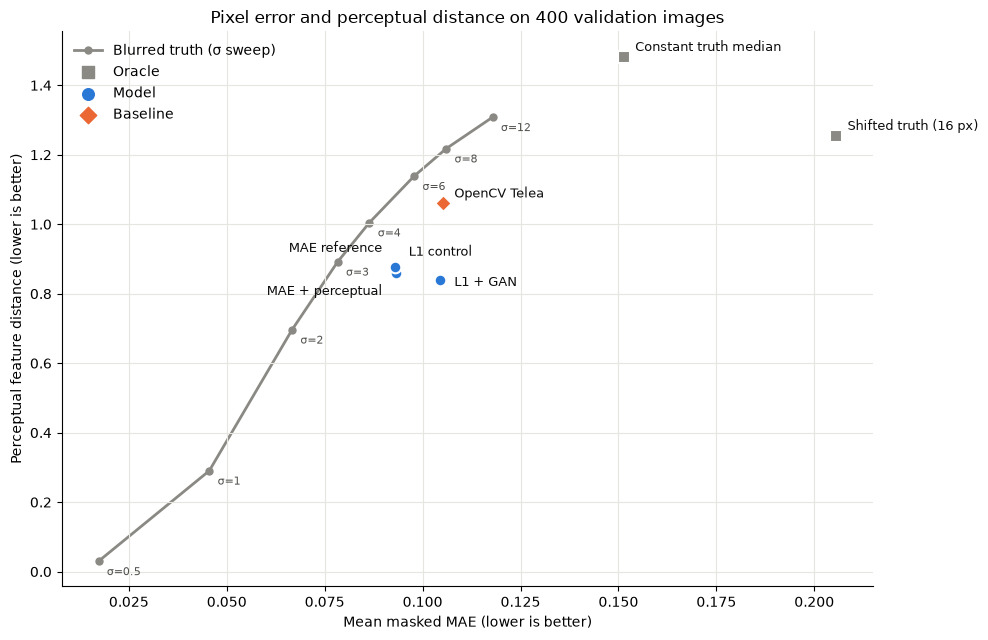

In [ ]:
NEUTRAL = "#8a8984"
MODEL_COLOR = "#2a78d6"
BASELINE_COLOR = "#eb6834"

blur_names = [f"Blurred truth σ={sigma:g}" for sigma in ORACLE_SIGMAS]
blur_points = metric_summary.loc[
    blur_names, ["masked_mae", "feature_distance"]
]

fig, ax = plt.subplots(figsize=(10, 6.5))

ax.plot(
    blur_points["masked_mae"], blur_points["feature_distance"],
    color=NEUTRAL, linewidth=2, marker="o", markersize=5,
    label="Blurred truth (σ sweep)", zorder=1,
)
for sigma, (x, y) in zip(ORACLE_SIGMAS, blur_points.to_numpy()):
    ax.annotate(
        f"σ={sigma:g}", (x, y), textcoords="offset points",
        xytext=(6, -10), fontsize=8, color="#52514e",
    )

short_labels = {
    "Deep U-Net (MAE reference)": ("MAE reference", (-10, 10), "right"),
    "L1 control (1,500 updates)": ("L1 control", (10, 8), "left"),
    "MAE + perceptual": ("MAE + perceptual", (-10, -16), "right"),
    "L1 + GAN (1,500 updates)": ("L1 + GAN", (10, -4), "left"),
}

marker_styles = {
    "Oracle": dict(color=NEUTRAL, marker="s"),
    "Model": dict(color=MODEL_COLOR, marker="o"),
    "Baseline": dict(color=BASELINE_COLOR, marker="D"),
}

for name, row in metric_summary.iterrows():
    if name in blur_names:
        continue
    style = marker_styles[row["kind"]]
    ax.scatter(
        row["masked_mae"], row["feature_distance"], s=70,
        edgecolor="white", linewidth=1.5, zorder=3, **style,
    )
    label, offset, align = short_labels.get(name, (name, (8, 4), "left"))
    ax.annotate(
        label, (row["masked_mae"], row["feature_distance"]),
        textcoords="offset points", xytext=offset, ha=align,
        fontsize=9, color="#0b0b0b",
    )

for kind, style in marker_styles.items():
    ax.scatter([], [], s=70, label=kind, **style)

ax.set_xlabel("Mean masked MAE (lower is better)")
ax.set_ylabel("Perceptual feature distance (lower is better)")
ax.set_title("Pixel error and perceptual distance on 400 validation images")
ax.grid(color="#e6e5e0", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

### Locate the Models on the Blur Scale

For each model, find the blur width σ at which the blurred-truth oracle
has the same masked MAE. This expresses the model's pixel error as
"equivalent to knowing the true image, blurred by σ pixels".

Compare the low- and high-frequency error of each model with the
oracle at that σ. If the model's low-frequency error is much larger,
its MAE is driven by wrong colors and layout rather than missing texture.

In [ ]:
blur_mae = metric_summary.loc[blur_names, "masked_mae"].to_numpy()
assert np.all(np.diff(blur_mae) > 0), "Blur MAE must increase with σ."

ceiling_rows = []

for name in [*generator_files, "OpenCV Telea"]:
    row = metric_summary.loc[name]
    equivalent_sigma = np.interp(
        row["masked_mae"], blur_mae, ORACLE_SIGMAS,
        left=np.nan, right=np.nan,
    )

    # Oracle errors at the same σ, interpolated between sweep points.
    oracle_low = np.interp(
        equivalent_sigma, ORACLE_SIGMAS,
        metric_summary.loc[blur_names, "low_freq_error"],
    )
    oracle_high = np.interp(
        equivalent_sigma, ORACLE_SIGMAS,
        metric_summary.loc[blur_names, "high_freq_error"],
    )

    ceiling_rows.append({
        "method": name,
        "masked_mae": row["masked_mae"],
        "equivalent_blur_sigma": equivalent_sigma,
        "low_freq_error": row["low_freq_error"],
        "oracle_low_freq_error": oracle_low,
        "high_freq_error": row["high_freq_error"],
        "oracle_high_freq_error": oracle_high,
        "low_freq_share": row["low_freq_error"]
        / (row["low_freq_error"] + row["high_freq_error"]),
    })

l1_ceiling = pd.DataFrame(ceiling_rows).set_index("method")
l1_ceiling.to_csv(DIAGNOSTIC_DIR / "l1_ceiling.csv")

display(l1_ceiling.round(4))

,masked_mae,equivalent_blur_sigma,low_freq_error,oracle_low_freq_error,high_freq_error,oracle_high_freq_error,low_freq_share
method,,,,,,,
Deep U-Net (MAE reference),0.0932,5.1932,0.0517,0.0391,0.0627,0.0674,0.4523
MAE + perceptual,0.0933,5.2039,0.0520,0.0392,0.0627,0.0674,0.4535
"L1 control (1,500 updates)",0.0929,5.1348,0.0516,0.0388,0.0626,0.0674,0.4518
"L1 + GAN (1,500 updates)",0.1045,7.6376,0.0537,0.0516,0.0767,0.0689,0.4119
OpenCV Telea,0.1053,7.8125,0.0625,0.0524,0.0665,0.0690,0.4845


### Visual Check at the Equivalent Blur

Show the MAE reference model next to the blurred-truth oracle at its
equivalent σ and the shifted-truth oracle. Use the highest-coverage
validation image of each category.

The blurred oracle has the same average pixel error as the model; the
comparison shows what kind of error that number corresponds to.

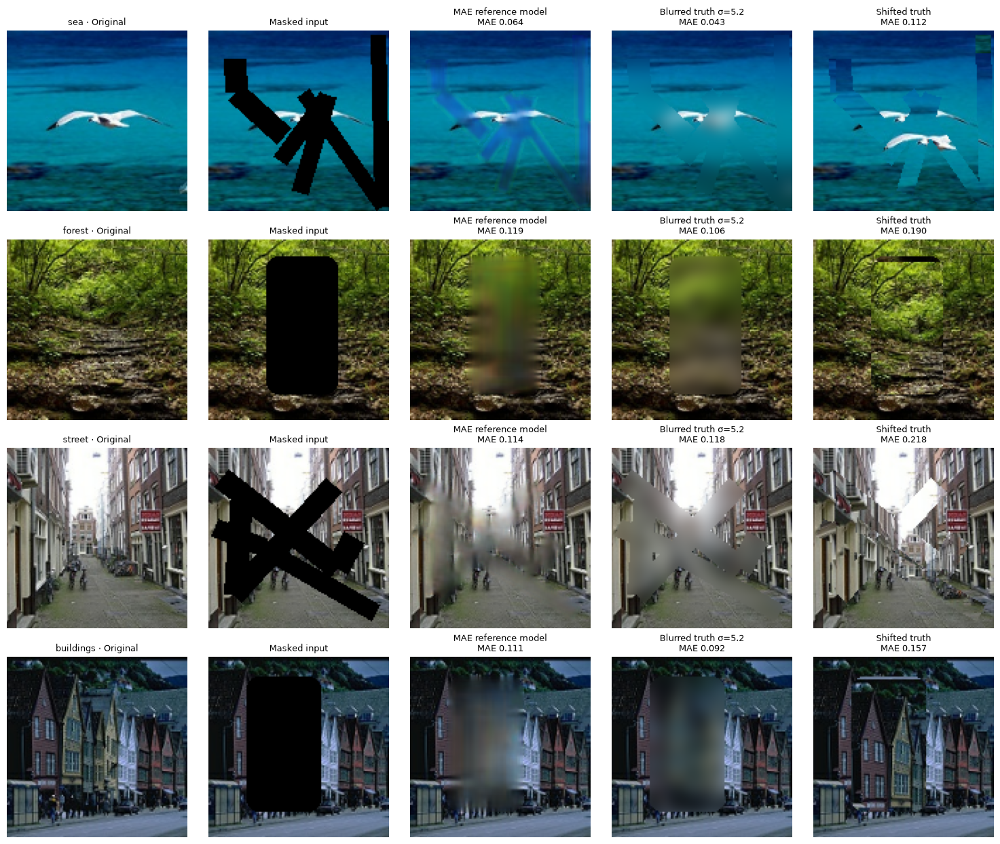

In [ ]:
reference_sigma = l1_ceiling.loc[reference_name, "equivalent_blur_sigma"]
reference_blur = compose(gaussian_blur(eval_originals, reference_sigma))

coverage = eval_masks.mean(axis=(1, 2, 3))
examples = [
    int(eval_manifest.index[eval_manifest["category"] == category][
        np.argmax(coverage[eval_manifest["category"] == category])
    ])
    for category in ["sea", "forest", "street", "buildings"]
]

columns = [
    ("Original", eval_originals),
    ("Masked input", eval_visible),
    ("MAE reference model", method_results[reference_name]),
    (f"Blurred truth σ={reference_sigma:.1f}", reference_blur),
    ("Shifted truth", oracle_results["Shifted truth (16 px)"]),
]

fig, axes = plt.subplots(len(examples), len(columns), figsize=(15, 12.5))
mae_by_name = {
    "MAE reference model": masked_mae_per_image(
        method_results[reference_name]
    ),
    f"Blurred truth σ={reference_sigma:.1f}": masked_mae_per_image(
        reference_blur
    ),
    "Shifted truth": masked_mae_per_image(
        oracle_results["Shifted truth (16 px)"]
    ),
}

for row, index in enumerate(examples):
    for col, (title, images) in enumerate(columns):
        ax = axes[row, col]
        ax.imshow(np.clip(images[index], 0, 1))
        label = title
        if title in mae_by_name:
            label += f"\nMAE {mae_by_name[title][index]:.3f}"
        if col == 0:
            label = f"{eval_manifest.loc[index, 'category']} · {title}"
        ax.set_title(label, fontsize=9)
        ax.axis("off")

plt.tight_layout()
plt.show()

### Metric and L1-Ceiling Results

**Pixel error is dominated by texture the model cannot place.** The MAE
reference model's masked MAE of 0.0932 equals that of the true image
blurred with σ ≈ 5.2 pixels. High-frequency error (0.0627) exceeds
low-frequency error (0.0517). A fill with no texture at all has a
high-frequency error of about 0.070 (σ = 12 oracle), and the model contains
about one fifth of the true high-frequency energy (texture ratio 0.21).
Lowering high-frequency error further requires texture at the exact true
position; texture in the wrong position increases it (shifted truth: 0.1065).

**The remaining L1 margin is limited.** The σ = 2 oracle has the same
amount of texture as the model (texture ratio 0.22) but nearly correct
colors and layout. Its MAE is 0.0667. At the model's current texture level,
perfect colors and layout would therefore lower MAE by roughly 28% at most,
and would not add texture.

**Colors and layout also deviate.** At equal MAE, the model's low-frequency
error is 32% higher than the blur oracle's (0.0517 vs 0.0391). Part of its
error is not explained by smoothing alone; the tinted streaks in the sea
example are one visible case.

**MAE and distribution metrics disagree.** The shifted truth is the worst
fill by MAE (0.206, worse than a constant color) yet has the lowest KID of
any non-trivial fill (2.20). The L1 + GAN model has higher MAE than the
reference on 95% of images (+0.0113), but lower perceptual distance
(−0.042, 95% CI [−0.056, −0.028]), lower KID in 96% of shared subsets, and
a texture ratio of 0.75. Its additional MAE comes mainly from high-frequency
error (0.0767 vs 0.0627); low-frequency error rises only from 0.0517 to 0.0537.

**The perceptual trial was not neutral.** MAE was unchanged, but perceptual
distance decreased on 82% of images (95% CI [−0.024, −0.016]) and KID was
lower in every shared subset. The feature-distance result is partly
circular, because the training loss and the metric both use VGG16; KID uses
InceptionV3 and does not share that dependence. The earlier four-image
inspection did not detect this small but consistent change.

OpenCV Telea is worse than every trained model on all three metrics.

**Implications.** More masked-L1 optimization, through longer training or
more capacity, can at most reduce error toward the low-frequency floor and
does not reward texture. The objective, not model size, limits visual
quality. Future experiments should be judged by perceptual distance, KID,
and blind ratings, with masked MAE and low-frequency error kept as controls
for color and layout.

**Limitations.** These are development-set results: the same validation
images and masks guided checkpoint selection. The perceptual distance is
the unlearned LPIPS variant. KID uses 128-pixel images upsampled for
InceptionV3 and is only comparable within this notebook. The blind ratings
are still pending and remain the direct test of visual preference.

## Experiment: Two-Stage Refinement with Texture-Oriented Losses

The metric diagnostic showed that the MAE reference model behaves like a
strongly blurred version of the truth, and that further masked-L1 training
can improve pixel error only modestly without adding texture.

Coarse-to-fine inpainting networks (DeepFill v1/v2) address this with a
second stage that refines a coarse fill. Their gains come from the
refinement stage's objective and operators, not from stacking networks:

- **Gated convolutions** (Yu et al., 2019) learn a soft per-pixel gate,
  so features computed from filled pixels are not treated as observed ones.
- **Perceptual and style losses** (Johnson et al., 2016; Liu et al., 2018)
  compare deep features and their second-order statistics, rewarding
  texture with the right character even when it is not pixel-aligned.
- **SN-PatchGAN** (Yu et al., 2019) judges local patches of the composed
  image with a spectrally normalized discriminator.

This experiment freezes the MAE reference model as the coarse stage and
trains two refiners with identical architecture, initialization, data,
masks, and update budget:

- **L1 refiner (control):** masked L1 only.
- **Texture refiner:** masked L1 + perceptual + masked style + adversarial.

The control separates the effect of the objective from the effect of
adding a second network. The hypothesis is that the texture refiner lowers
KID and perceptual distance relative to both the coarse model and the
control, at a limited cost in masked MAE. Run the metric section first:
this section reuses its validation setup and evaluation functions.

### Training Data and the Frozen Coarse Stage

Use the 6,000 training images from the snapshot manifest and the same
mixed-mask generator used to train the coarse model. Batches are rebuilt
deterministically from the global step with new seeds, so both refiners
receive identical images and masks at every update.

The coarse model is loaded once and never updated. Its composed output,
original pixels outside the hole and coarse fill inside, is the refiners'
input.

In [ ]:
import time

from PIL import Image, ImageDraw
from tensorflow.keras import layers

required_names = [
    "EVAL_RECORD_DIR", "MODEL_DIR", "PROJECT_ROOT", "load_eval_image",
    "eval_inputs", "eval_masks", "eval_originals", "vgg_preprocess",
    "masked_mae_per_image", "feature_distance", "frequency_errors",
    "inception_features", "kernel_inception_distance", "real_inception",
    "kid_estimates", "per_image_metrics", "metric_summary",
    "method_results", "eval_visible", "examples",
]
missing = [name for name in required_names if name not in globals()]
if missing:
    raise RuntimeError(f"Run the metric section first. Missing: {missing}")

keras.utils.set_random_seed(2040)

REFINE_DIR = EVAL_RECORD_DIR / "refinement"
REFINE_DIR.mkdir(exist_ok=True)
REFINE_BATCH_SIZE = 16

refine_manifest = pd.read_csv(EVAL_RECORD_DIR / "train_6000.csv")
refine_paths = [PROJECT_ROOT / path for path in refine_manifest["path"]]
refine_steps_per_epoch = -(-len(refine_paths) // REFINE_BATCH_SIZE)


def create_mixed_mask(rng):
    # Identical to the mixed-mask generator used to train the coarse model.
    mask = Image.new("L", (128, 128), 0)
    brush = ImageDraw.Draw(mask)
    kind = rng.choice(["strokes", "block", "silhouette"])

    if kind == "strokes":
        for _ in range(rng.integers(1, 4)):
            points = rng.integers(0, 128, size=(3, 2))
            brush.line(
                [tuple(map(int, point)) for point in points],
                fill=255,
                width=int(rng.integers(6, 18)),
            )
    else:
        width = int(rng.integers(24, 55))
        height = int(rng.integers(45, 105))
        x = int(rng.integers(0, 129 - width))
        y = int(rng.integers(0, 129 - height))

        if kind == "block":
            brush.rounded_rectangle(
                (x, y, x + width - 1, y + height - 1),
                radius=8,
                fill=255,
            )
        else:
            silhouette = Image.new("L", (64, 128), 0)
            body = ImageDraw.Draw(silhouette)
            body.ellipse((23, 0, 41, 22), fill=255)
            body.rounded_rectangle((15, 22, 49, 80), radius=8, fill=255)
            body.line([(17, 30), (5, 77)], fill=255, width=10)
            body.line([(47, 30), (59, 77)], fill=255, width=10)
            body.line([(24, 75), (20, 127)], fill=255, width=13)
            body.line([(40, 75), (44, 127)], fill=255, width=13)
            silhouette = silhouette.resize(
                (width, height), Image.Resampling.NEAREST
            )
            mask.paste(silhouette, (x, y))

    return np.asarray(mask, dtype=np.float32)[..., None] / 255


def refine_batch(step):
    epoch, batch_index = divmod(step, refine_steps_per_epoch)
    order = np.random.default_rng(
        np.random.SeedSequence([2040, epoch])
    ).permutation(len(refine_paths))
    start = batch_index * REFINE_BATCH_SIZE
    indices = order[start:start + REFINE_BATCH_SIZE]

    images = np.stack([load_eval_image(refine_paths[i]) for i in indices])
    mask_rng = np.random.default_rng(np.random.SeedSequence([2041, step]))
    masks = np.stack([create_mixed_mask(mask_rng) for _ in indices])

    return (
        tf.convert_to_tensor(images, dtype=tf.float32),
        tf.convert_to_tensor(masks, dtype=tf.float32),
    )


coarse_model = keras.models.load_model(
    MODEL_DIR / "best_deep_unet_6000_tuned.keras", compile=False
)
coarse_model.trainable = False


@tf.function
def coarse_composite(images, masks):
    visible = images * (1 - masks)
    prediction = coarse_model(
        tf.concat([visible, masks], axis=-1), training=False
    )
    return visible + prediction * masks


probe_images, probe_masks = refine_batch(0)
probe_coarse = coarse_composite(probe_images, probe_masks)

print(f"Training images: {len(refine_paths)}")
print(f"Updates per epoch: {refine_steps_per_epoch}")

Training images: 6000
Updates per epoch: 375


### Build the Gated-Convolution Refiner

Each gated convolution computes features and a sigmoid gate from the same
input and multiplies them. The encoder downsamples to 32 × 32, dilated
gated convolutions (rates 2, 4, 8) widen the receptive field, and the
decoder upsamples with skip connections.

The refiner predicts a residual in logit space:
refined = sigmoid(logit(coarse) + residual). The last layer starts at zero,
so both refiners initially reproduce the coarse result exactly. Training
can only move away from the coarse fill, not start from noise.

In [ ]:
def gated_conv(x, filters, kernel_size=3, strides=1, dilation_rate=1,
               name=None):
    features = layers.Conv2D(
        filters, kernel_size, strides=strides,
        dilation_rate=dilation_rate, padding="same",
        name=f"{name}_features",
    )(x)
    features = layers.ELU(name=f"{name}_elu")(features)
    gate = layers.Conv2D(
        filters, kernel_size, strides=strides,
        dilation_rate=dilation_rate, padding="same",
        activation="sigmoid", name=f"{name}_gate",
    )(x)
    return layers.Multiply(name=name)([features, gate])


def build_refiner(name):
    inputs = keras.Input(shape=(128, 128, 4))

    x128 = gated_conv(inputs, 32, kernel_size=5, name="enc128")
    x = gated_conv(x128, 64, strides=2, name="down64")
    x64 = gated_conv(x, 64, name="enc64")
    x = gated_conv(x64, 128, strides=2, name="down32")
    x = gated_conv(x, 128, name="enc32")

    for rate in [2, 4, 8]:
        x = gated_conv(x, 128, dilation_rate=rate, name=f"dilated{rate}")

    x = gated_conv(x, 128, name="dec32")
    x = layers.UpSampling2D(name="up64")(x)
    x = layers.Concatenate(name="skip64")([x, x64])
    x = gated_conv(x, 64, name="dec64")
    x = layers.UpSampling2D(name="up128")(x)
    x = layers.Concatenate(name="skip128")([x, x128])
    x = gated_conv(x, 32, name="dec128")

    residual = layers.Conv2D(
        3, 3, padding="same",
        kernel_initializer="zeros", bias_initializer="zeros",
        name="residual",
    )(x)
    return keras.Model(inputs, residual, name=name)


def refine(refiner, coarse, masks, training=False):
    clipped = tf.clip_by_value(coarse, 1e-3, 1 - 1e-3)
    logits = tf.math.log(clipped) - tf.math.log1p(-clipped)
    residual = refiner(
        tf.concat([coarse, masks], axis=-1), training=training
    )
    refined = tf.sigmoid(logits + residual)
    # Original pixels outside the hole are always preserved.
    return coarse * (1 - masks) + refined * masks


control_refiner = build_refiner("refiner_l1_control")
texture_refiner = build_refiner("refiner_texture")
texture_refiner.set_weights(control_refiner.get_weights())

identity_gap = float(tf.reduce_max(tf.abs(
    refine(texture_refiner, probe_coarse, probe_masks) - probe_coarse
)))
assert identity_gap < 2e-3, identity_gap

print(f"Refiner parameters: {control_refiner.count_params():,}")
print(f"Maximum initial change from the coarse result: {identity_gap:.1e}")

Refiner parameters: 2,018,403
Maximum initial change from the coarse result: 6.0e-08


### Build the Spectrally Normalized Patch Discriminator

The discriminator receives a composed image and its hole mask and outputs
an 8 × 8 grid of real/fake scores. Spectral normalization bounds each
layer's Lipschitz constant, which stabilizes adversarial training
(Miyato et al., 2018). The previous adversarial experiment used no such
constraint.

Only patches whose receptive fields overlap the hole are scored. Patches
outside it are identical for real and composed images and carry no signal.

In [ ]:
def build_patch_discriminator():
    inputs = keras.Input(shape=(128, 128, 4))
    x = inputs

    for filters in [64, 128, 256, 256]:
        x = layers.SpectralNormalization(
            layers.Conv2D(filters, 5, strides=2, padding="same")
        )(x)
        x = layers.LeakyReLU(negative_slope=0.2)(x)

    scores = layers.SpectralNormalization(
        layers.Conv2D(1, 3, padding="same")
    )(x)
    return keras.Model(inputs, scores, name="sn_patch_discriminator")


def patch_weights_from_mask(masks):
    # Match the discriminator's downsampling and receptive field.
    weights = masks
    for _ in range(4):
        weights = tf.nn.max_pool2d(weights, ksize=5, strides=2, padding="SAME")
    return tf.nn.max_pool2d(weights, ksize=3, strides=1, padding="SAME")


def patch_mean(values, weights):
    return tf.math.divide_no_nan(
        tf.reduce_sum(values * weights), tf.reduce_sum(weights)
    )


refine_discriminator = build_patch_discriminator()
probe_scores = refine_discriminator(
    tf.concat([probe_coarse, probe_masks], axis=-1)
)
assert probe_scores.shape[1:] == patch_weights_from_mask(probe_masks).shape[1:]

print(f"Discriminator parameters: {refine_discriminator.count_params():,}")
print(f"Score grid: {tuple(probe_scores.shape[1:3])}")

Discriminator parameters: 2,672,514
Score grid: (8, 8)


### Define the Texture-Oriented Losses

- **Masked L1:** mean absolute error over hole pixels, as before.
- **Perceptual:** L1 distance between frozen VGG16 activations (pool1–3)
  of the composed and original images, weighted by the hole mask resized
  to each feature map.
- **Masked style:** L1 distance between Gram matrices of those activations,
  computed over the hole region only. A Gram matrix records which feature
  channels occur together, independently of position, so it measures
  texture character rather than pixel alignment.
- **Adversarial:** hinge loss on hole patches.

The evaluation metric section uses VGG16 convolution outputs; this loss uses
VGG16 pooling outputs. They are related, so the perceptual-distance
comparison is not independent for the texture refiner. KID is.

In [ ]:
vgg_loss_base = keras.applications.VGG16(
    include_top=False, weights="imagenet", input_shape=(128, 128, 3)
)
loss_features = keras.Model(
    vgg_loss_base.input,
    [vgg_loss_base.get_layer(name).output
     for name in ["block1_pool", "block2_pool", "block3_pool"]],
)
loss_features.trainable = False


def hole_l1(images, results, masks):
    return tf.math.divide_no_nan(
        tf.reduce_sum(tf.abs(images - results) * masks),
        3.0 * tf.reduce_sum(masks),
    )


def perceptual_and_style(truth_features, result_features, masks):
    perceptual = 0.0
    style = 0.0

    for truth, result in zip(truth_features, result_features):
        weights = tf.image.resize(
            masks, tf.shape(truth)[1:3], method="area"
        )
        channels = tf.cast(tf.shape(truth)[-1], tf.float32)

        perceptual += tf.math.divide_no_nan(
            tf.reduce_sum(tf.abs(truth - result) * weights),
            tf.reduce_sum(weights) * channels,
        )

        # Gram matrices over the hole region of each image.
        area = tf.reduce_sum(weights, axis=[1, 2, 3])[:, None, None]
        normalizer = area * channels + 1e-6
        truth_gram = tf.einsum(
            "bhwc,bhwd->bcd", truth * weights, truth
        ) / normalizer
        result_gram = tf.einsum(
            "bhwc,bhwd->bcd", result * weights, result
        ) / normalizer
        style += tf.reduce_mean(tf.abs(truth_gram - result_gram))

    return perceptual / 3.0, style / 3.0


def hinge_discriminator_loss(real_scores, fake_scores, weights):
    return (
        patch_mean(tf.nn.relu(1.0 - real_scores), weights)
        + patch_mean(tf.nn.relu(1.0 + fake_scores), weights)
    )

### Calibrate the Reconstruction Weights

The literature's loss weights depend on how each term is normalized and do
not transfer between implementations. Instead, measure on four training
batches the gradient norm of each term with respect to the refined image,
starting from the identity refiner.

Choose the perceptual and style weights so that each weighted gradient
norm equals that of masked L1. Pixel error, feature error, and texture
statistics then contribute comparably at the start of training. This is a
heuristic starting point, not an optimized balance.

In [ ]:
calibration_rows = []

for step in range(4):
    images, masks = refine_batch(step)
    coarse = coarse_composite(images, masks)
    truth_features = loss_features(vgg_preprocess(images), training=False)

    with tf.GradientTape(persistent=True) as tape:
        tape.watch(coarse)
        result = refine(texture_refiner, coarse, masks)
        l1 = hole_l1(images, result, masks)
        perceptual, style = perceptual_and_style(
            truth_features,
            loss_features(vgg_preprocess(result), training=False),
            masks,
        )

    calibration_rows.append({
        "l1": float(l1),
        "perceptual": float(perceptual),
        "style": float(style),
        "l1_grad": float(tf.norm(tape.gradient(l1, coarse))),
        "perceptual_grad": float(tf.norm(tape.gradient(perceptual, coarse))),
        "style_grad": float(tf.norm(tape.gradient(style, coarse))),
    })
    del tape

calibration = pd.DataFrame(calibration_rows)
assert (calibration[["l1_grad", "perceptual_grad", "style_grad"]] > 0).all().all()

PERCEPTUAL_WEIGHT = float(
    (calibration["l1_grad"] / calibration["perceptual_grad"]).mean()
)
STYLE_WEIGHT = float(
    (calibration["l1_grad"] / calibration["style_grad"]).mean()
)

display(calibration.round(6))
print(f"Perceptual weight: {PERCEPTUAL_WEIGHT:.4g}")
print(f"Style weight: {STYLE_WEIGHT:.4g}")

,l1,perceptual,style,l1_grad,perceptual_grad,style_grad
0,0.087225,257.106659,690.448792,0.003265,15.229470,37.658665
1,0.066220,193.686081,501.778198,0.003076,15.338514,34.583736
2,0.104036,291.122314,793.171936,0.002925,12.993695,29.045321
3,0.080662,244.784058,654.672302,0.003144,14.599402,39.881207


Perceptual weight: 0.0002139
Style weight: 8.88e-05


### Define Matched Training Updates

Each step uses one batch for every network:

1. Update the L1 refiner with masked L1.
2. Update the discriminator on real images and the texture refiner's
   current composed output.
3. Update the texture refiner with the reconstruction losses plus the
   adversarial term.

The previous adversarial run used a fixed coefficient, and the adversarial
share of the gradient drifted from 0.2 to above 1. Here the coefficient is
adaptive, in the spirit of Esser et al. (2021): at every step it is set so
that the adversarial gradient norm with respect to the composed output is
a fixed fraction, ADV_RATIO, of the reconstruction gradient norm. This is
the same ratio monitored in the earlier adversarial experiment.

Both gradients are taken with respect to the output image and combined
before a single backward pass through the refiner.

In [ ]:
ADV_RATIO = 0.5
REFINE_LEARNING_RATE = 1e-4

control_optimizer = keras.optimizers.Adam(
    REFINE_LEARNING_RATE, beta_1=0.5, beta_2=0.999
)
texture_optimizer = keras.optimizers.Adam(
    REFINE_LEARNING_RATE, beta_1=0.5, beta_2=0.999
)
discriminator_optimizer = keras.optimizers.Adam(
    REFINE_LEARNING_RATE, beta_1=0.5, beta_2=0.999
)

@tf.function
def refine_train_step(images, masks):
    coarse = coarse_composite(images, masks)
    weights = patch_weights_from_mask(masks)
    truth_features = loss_features(vgg_preprocess(images), training=False)

    # 1. L1 control.
    with tf.GradientTape() as tape:
        control_result = refine(control_refiner, coarse, masks, training=True)
        control_l1 = hole_l1(images, control_result, masks)
    gradients = tape.gradient(control_l1, control_refiner.trainable_variables)
    control_optimizer.apply_gradients(
        zip(gradients, control_refiner.trainable_variables)
    )

    # 2. Discriminator.
    fake = tf.stop_gradient(refine(texture_refiner, coarse, masks))
    with tf.GradientTape() as tape:
        real_scores = refine_discriminator(
            tf.concat([images, masks], axis=-1), training=True
        )
        fake_scores = refine_discriminator(
            tf.concat([fake, masks], axis=-1), training=True
        )
        d_loss = hinge_discriminator_loss(real_scores, fake_scores, weights)
    gradients = tape.gradient(d_loss, refine_discriminator.trainable_variables)
    discriminator_optimizer.apply_gradients(
        zip(gradients, refine_discriminator.trainable_variables)
    )

    # 3. Texture refiner.
    with tf.GradientTape(persistent=True) as tape:
        result = refine(texture_refiner, coarse, masks, training=True)
        l1 = hole_l1(images, result, masks)
        perceptual, style = perceptual_and_style(
            truth_features,
            loss_features(vgg_preprocess(result), training=False),
            masks,
        )
        reconstruction = (
            l1 + PERCEPTUAL_WEIGHT * perceptual + STYLE_WEIGHT * style
        )
        generated_scores = refine_discriminator(
            tf.concat([result, masks], axis=-1), training=False
        )
        adversarial = -patch_mean(generated_scores, weights)

    reconstruction_gradient = tape.gradient(reconstruction, result)
    adversarial_gradient = tape.gradient(adversarial, result)
    adv_weight = tf.clip_by_value(
        ADV_RATIO * tf.norm(reconstruction_gradient)
        / (tf.norm(adversarial_gradient) + 1e-12),
        0.0, 1e4,
    )

    variables = texture_refiner.trainable_variables
    gradients = tape.gradient(
        result, variables,
        output_gradients=reconstruction_gradient
        + adv_weight * adversarial_gradient,
    )
    del tape
    texture_optimizer.apply_gradients(zip(gradients, variables))

    return {
        "control_l1": control_l1,
        "texture_l1": l1,
        "perceptual": perceptual,
        "style": style,
        "adversarial": adversarial,
        "adv_weight": adv_weight,
        "discriminator_loss": d_loss,
        "real_score": patch_mean(real_scores, weights),
        "fake_score": patch_mean(fake_scores, weights),
    }

### Save and Resume Training State

Store both refiners, the discriminator, the three optimizers, the completed
step count, and the calibrated weights. If a checkpoint exists, training
resumes from it and the step log is truncated to match.

In [ ]:
REFINE_CHECKPOINT_DIR = MODEL_DIR / "refinement"
REFINE_LOG_PATH = REFINE_DIR / "training_log.csv"

refine_completed_steps = tf.Variable(0, dtype=tf.int64, trainable=False)
refine_loss_weights = tf.Variable(
    [PERCEPTUAL_WEIGHT, STYLE_WEIGHT, ADV_RATIO],
    dtype=tf.float32, trainable=False,
)

refine_checkpoint = tf.train.Checkpoint(
    step=refine_completed_steps,
    loss_weights=refine_loss_weights,
    control=control_refiner,
    texture=texture_refiner,
    discriminator=refine_discriminator,
    control_optimizer=control_optimizer,
    texture_optimizer=texture_optimizer,
    discriminator_optimizer=discriminator_optimizer,
)
refine_manager = tf.train.CheckpointManager(
    refine_checkpoint, str(REFINE_CHECKPOINT_DIR), max_to_keep=3
)

if refine_manager.latest_checkpoint:
    refine_checkpoint.restore(refine_manager.latest_checkpoint)
    restored = refine_loss_weights.numpy()
    if not np.allclose(restored, [PERCEPTUAL_WEIGHT, STYLE_WEIGHT, ADV_RATIO]):
        raise ValueError(
            f"Checkpoint loss weights {restored} differ from the calibration."
        )
    refine_log = pd.read_csv(REFINE_LOG_PATH)
    refine_log = refine_log[
        refine_log["step"] <= int(refine_completed_steps.numpy())
    ].to_dict("records")
    print(f"Resumed at step {int(refine_completed_steps.numpy())}")
else:
    refine_log = []
    print("Starting from the identity refiners.")


def run_refinement(until_step, report_every=50):
    start_time = time.perf_counter()
    first_step = int(refine_completed_steps.numpy())

    for step in range(first_step, until_step):
        images, masks = refine_batch(step)
        values = refine_train_step(images, masks)

        refine_log.append({
            "step": step + 1,
            **{name: float(value) for name, value in values.items()},
        })
        refine_completed_steps.assign(step + 1)

        if (step + 1) % report_every == 0 or step + 1 == until_step:
            window = pd.DataFrame(refine_log[-report_every:])
            per_step = (time.perf_counter() - start_time) / (step + 1 - first_step)
            print(
                f"Steps {int(window['step'].min())}–{step + 1} | "
                f"L1 control: {window['control_l1'].mean():.4f} | "
                f"Texture L1: {window['texture_l1'].mean():.4f} | "
                f"Perc: {window['perceptual'].mean():.3f} | "
                f"Style: {window['style'].mean():.4f} | "
                f"D: {window['discriminator_loss'].mean():.3f} | "
                f"Adv weight: {window['adv_weight'].mean():.3g} | "
                f"{per_step:.2f} s/step"
            )
            pd.DataFrame(refine_log).to_csv(REFINE_LOG_PATH, index=False)

        if (step + 1) % 250 == 0 or step + 1 == until_step:
            refine_manager.save(checkpoint_number=step + 1)

Starting from the identity refiners.


### Run a 100-Update Pilot

Check that losses are finite, the discriminator is learning, the adaptive
weight stays bounded, and both refiners begin to move away from the coarse
result. Measure time per update to set the full training budget.

In [ ]:
run_refinement(100, report_every=25)

Steps 1–25 | L1 control: 0.0939 | Texture L1: 0.0939 | Perc: 273.338 | Style: 729.7259 | D: 1.993 | Adv weight: 1.03 | 2.01 s/step


Steps 26–50 | L1 control: 0.0952 | Texture L1: 0.0952 | Perc: 278.208 | Style: 750.2038 | D: 1.979 | Adv weight: 0.508 | 1.89 s/step


Steps 51–75 | L1 control: 0.0959 | Texture L1: 0.0961 | Perc: 275.140 | Style: 733.4616 | D: 1.919 | Adv weight: 0.183 | 1.85 s/step


Steps 76–100 | L1 control: 0.0934 | Texture L1: 0.0938 | Perc: 273.770 | Style: 727.4412 | D: 1.900 | Adv weight: 0.138 | 1.83 s/step


### Inspect the Pilot on Fixed Validation Examples

Use the highest-coverage validation image of each category, as in the
metric section. Compare the coarse fill with both refiners after the same
number of updates. Look for new texture, color drift, and repeated patterns.

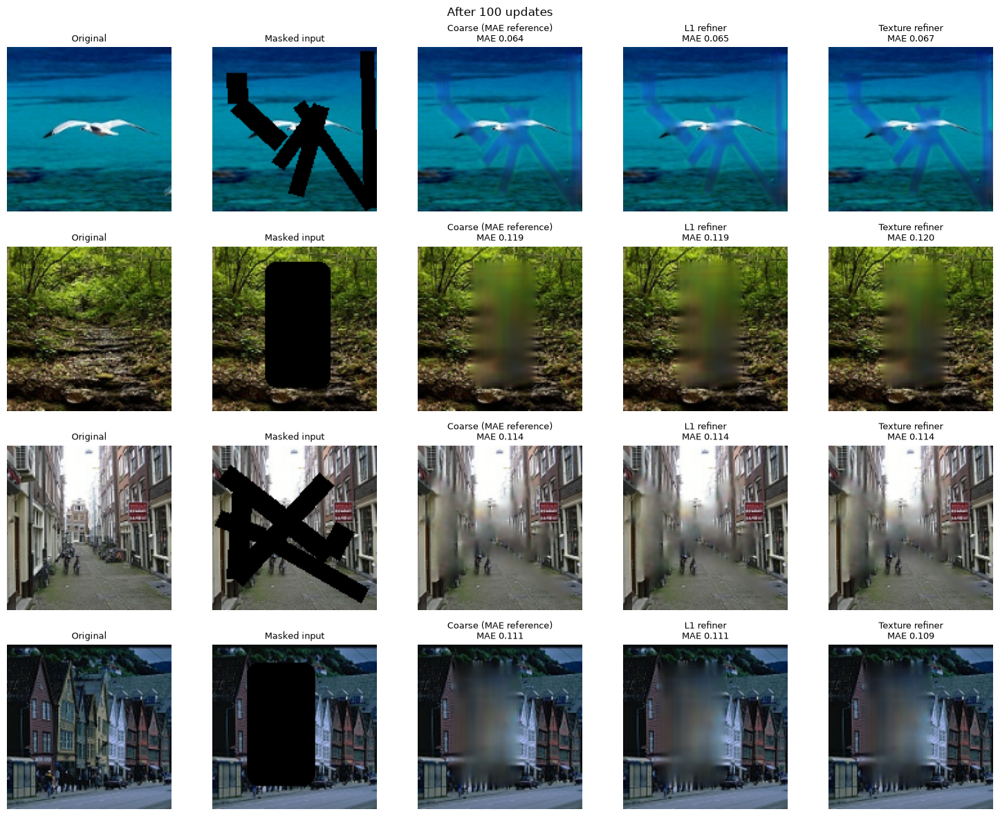

In [ ]:
def refine_validation(refiner, batch_size=50):
    coarse_results = method_results["Deep U-Net (MAE reference)"]
    return np.concatenate([
        refine(
            refiner,
            tf.constant(coarse_results[start:start + batch_size]),
            tf.constant(eval_masks[start:start + batch_size]),
        ).numpy()
        for start in range(0, len(coarse_results), batch_size)
    ])


def show_refinement(results_by_name, indices, title):
    columns = [
        ("Original", eval_originals),
        ("Masked input", eval_visible),
        *results_by_name.items(),
    ]
    fig, axes = plt.subplots(
        len(indices), len(columns), figsize=(3 * len(columns), 3 * len(indices))
    )
    column_mae = {
        name: masked_mae_per_image(images)
        for name, images in results_by_name.items()
    }
    for row, index in enumerate(indices):
        for col, (name, images) in enumerate(columns):
            ax = axes[row, col]
            ax.imshow(np.clip(images[index], 0, 1))
            label = name
            if name in column_mae:
                label += f"\nMAE {column_mae[name][index]:.3f}"
            ax.set_title(label, fontsize=9)
            ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


pilot_results = {
    "Coarse (MAE reference)": method_results["Deep U-Net (MAE reference)"],
    "L1 refiner": refine_validation(control_refiner),
    "Texture refiner": refine_validation(texture_refiner),
}
show_refinement(
    pilot_results, examples,
    f"After {int(refine_completed_steps.numpy())} updates",
)

### Pilot Observations

After 100 updates per arm:

- All losses are finite. The discriminator hinge loss fell from 1.99 to
  1.90, so it has begun to separate real images from refined composites.
- The adaptive adversarial coefficient fell from about 1.0 to 0.14 as the
  discriminator's gradients grew. By construction, the adversarial share of
  the output gradient stayed at ADV_RATIO = 0.5.
- Both refiners remain close to the coarse result, as expected from the
  zero-initialized output layer and a learning rate of 1e-4. Training-batch
  L1 is nearly identical across arms (0.0934 and 0.0938 in the last window).
- One update of all three networks takes about 1.8 s on the M5 GPU, so the
  3,000-update budget (8 epochs) requires roughly 90 minutes.

The pilot does not yet indicate whether the texture objective helps.

### Complete the Fixed Training Budget

Continue both refiners to the full budget without changing loss weights,
learning rates, or the data schedule. Training resumes from the latest
checkpoint if interrupted.

Judge the result with the predefined metrics, not by repeated inspection of
the same examples during training.

In [ ]:
REFINE_STEPS = 3000
run_refinement(REFINE_STEPS, report_every=250)

control_refiner.save(MODEL_DIR / "refiner_l1_control.keras")
texture_refiner.save(MODEL_DIR / "refiner_texture.keras")
print(f"Completed updates per refiner: {int(refine_completed_steps.numpy())}")

Steps 1–250 | L1 control: 0.0941 | Texture L1: 0.0945 | Perc: 273.493 | Style: 725.3242 | D: 1.864 | Adv weight: 0.234 | 1.75 s/step
Steps 251–500 | L1 control: 0.0927 | Texture L1: 0.0985 | Perc: 275.487 | Style: 613.0839 | D: 1.789 | Adv weight: 0.0525 | 1.73 s/step
Steps 501–750 | L1 control: 0.0939 | Texture L1: 0.1028 | Perc: 277.979 | Style: 554.1761 | D: 1.813 | Adv weight: 0.0517 | 1.72 s/step
Steps 751–1000 | L1 control: 0.0941 | Texture L1: 0.1031 | Perc: 275.512 | Style: 534.6995 | D: 1.788 | Adv weight: 0.0505 | 1.72 s/step
Steps 1001–1250 | L1 control: 0.0944 | Texture L1: 0.1047 | Perc: 273.769 | Style: 501.3278 | D: 1.844 | Adv weight: 0.0469 | 1.72 s/step
Steps 1251–1500 | L1 control: 0.0940 | Texture L1: 0.1055 | Perc: 271.292 | Style: 449.3431 | D: 1.891 | Adv weight: 0.0495 | 1.72 s/step
Steps 1501–1750 | L1 control: 0.0936 | Texture L1: 0.1053 | Perc: 269.830 | Style: 428.2639 | D: 1.907 | Adv weight: 0.0556 | 1.72 s/step
Steps 1751–2000 | L1 control: 0.0941 | Textu

### Training Curves

Plot 100-update moving averages. Both arms' masked L1 share one axis; the
texture arm's other terms and the discriminator are shown separately
because their scales differ.

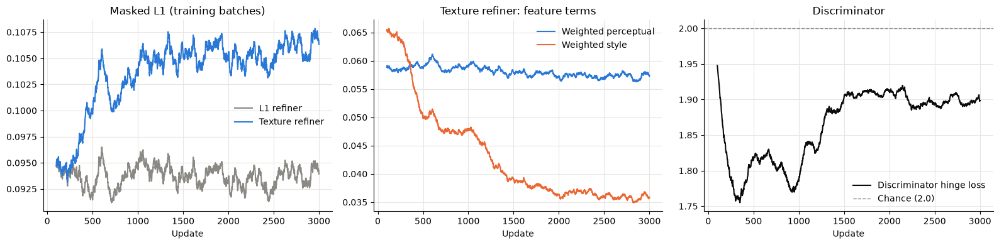

In [ ]:
log_frame = pd.DataFrame(refine_log).set_index("step").rolling(100).mean()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(log_frame["control_l1"], label="L1 refiner", color="#8a8984")
axes[0].plot(log_frame["texture_l1"], label="Texture refiner", color="#2a78d6")
axes[0].set_title("Masked L1 (training batches)")
axes[0].legend(frameon=False)

axes[1].plot(log_frame["perceptual"] * PERCEPTUAL_WEIGHT, label="Weighted perceptual", color="#2a78d6")
axes[1].plot(log_frame["style"] * STYLE_WEIGHT, label="Weighted style", color="#eb6834")
axes[1].set_title("Texture refiner: feature terms")
axes[1].legend(frameon=False)

axes[2].plot(log_frame["discriminator_loss"], label="Discriminator hinge loss", color="#0b0b0b")
axes[2].axhline(2.0, color="#8a8984", linestyle="--", linewidth=1, label="Chance (2.0)")
axes[2].set_title("Discriminator")
axes[2].legend(frameon=False)

for ax in axes:
    ax.set_xlabel("Update")
    ax.grid(color="#e6e5e0", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

### Evaluate Both Refiners

Apply the metric section's evaluation to the refined validation set:
masked MAE, frequency components, perceptual distance, and KID with the
same paired subsets. Compare each refiner with the coarse MAE reference
image by image.

In [ ]:
refined_results = {
    "L1 refiner": refine_validation(control_refiner),
    "Texture refiner": refine_validation(texture_refiner),
}

reference_rows = per_image_metrics[
    per_image_metrics["method"] == "Deep U-Net (MAE reference)"
].set_index("image_index")
bootstrap_index = np.random.default_rng(2034).integers(
    0, len(reference_rows), size=(2000, len(reference_rows))
)

refine_summary_rows = []
refine_paired_rows = []

for name, results in refined_results.items():
    mae = masked_mae_per_image(results)
    low_error, high_error, texture_ratio = frequency_errors(results)
    distance = feature_distance(results)
    kid_estimates[name] = kernel_inception_distance(
        real_inception, inception_features(results)
    )

    refine_summary_rows.append({
        "method": name,
        "masked_mae": mae.mean(),
        "feature_distance": distance.mean(),
        "kid_x1000": 1000 * kid_estimates[name].mean(),
        "kid_x1000_std": 1000 * kid_estimates[name].std(),
        "low_freq_error": low_error.mean(),
        "high_freq_error": high_error.mean(),
        "texture_ratio_median": np.nanmedian(texture_ratio),
    })

    paired = {"method": name}
    for metric, values in [("masked_mae", mae), ("feature_distance", distance)]:
        difference = values - reference_rows[metric].to_numpy()
        low, high = np.percentile(
            difference[bootstrap_index].mean(axis=1), [2.5, 97.5]
        )
        paired[f"{metric} Δ"] = difference.mean()
        paired[f"{metric} 95% CI"] = f"[{low:+.4f}, {high:+.4f}]"
        paired[f"{metric} images better"] = f"{(difference < 0).mean():.0%}"
    kid_difference = 1000 * (
        kid_estimates[name] - kid_estimates["Deep U-Net (MAE reference)"]
    )
    paired["KID×1000 Δ"] = kid_difference.mean()
    paired["KID subsets lower"] = f"{(kid_difference < 0).mean():.0%}"
    refine_paired_rows.append(paired)

comparison_names = [
    "Deep U-Net (MAE reference)", "L1 + GAN (1,500 updates)", "OpenCV Telea"
]
refine_summary = pd.concat([
    metric_summary.loc[comparison_names].drop(columns="kind"),
    pd.DataFrame(refine_summary_rows).set_index("method"),
])
refine_paired = pd.DataFrame(refine_paired_rows).set_index("method")

refine_summary.to_csv(REFINE_DIR / "metric_summary.csv")
refine_paired.to_csv(REFINE_DIR / "paired_vs_reference.csv")

with pd.option_context("display.width", 200, "display.max_columns", 20):
    display(refine_summary.round(4))
    display(refine_paired.round(4))

,masked_mae,feature_distance,kid_x1000,kid_x1000_std,low_freq_error,high_freq_error,texture_ratio_median
method,,,,,,,
Deep U-Net (MAE reference),0.0932,0.8803,4.7893,2.2259,0.0517,0.0627,0.2146
"L1 + GAN (1,500 updates)",0.1045,0.8383,2.8346,2.3573,0.0537,0.0767,0.7481
OpenCV Telea,0.1053,1.0610,13.3130,3.5004,0.0625,0.0665,0.2347
L1 refiner,0.0930,0.8758,4.6346,2.2321,0.0515,0.0626,0.2098
Texture refiner,0.1044,0.7057,-0.1895,1.9799,0.0531,0.0767,0.8301


,masked_mae Δ,masked_mae 95% CI,masked_mae images better,feature_distance Δ,feature_distance 95% CI,feature_distance images better,KID×1000 Δ,KID subsets lower
method,,,,,,,,
L1 refiner,-0.0003,"[-0.0004, -0.0002]",61%,-0.0045,"[-0.0064, -0.0028]",58%,-0.1547,92%
Texture refiner,0.0111,"[+0.0103, +0.0119]",5%,-0.1746,"[-0.1898, -0.1598]",92%,-4.9787,100%


### Visual Comparison after the Full Budget

Show the same four examples with the coarse model, both refiners, and the
earlier L1 + GAN generator. These examples are illustrative; the metrics
and a blind review on the 60-image panel are the basis for conclusions.

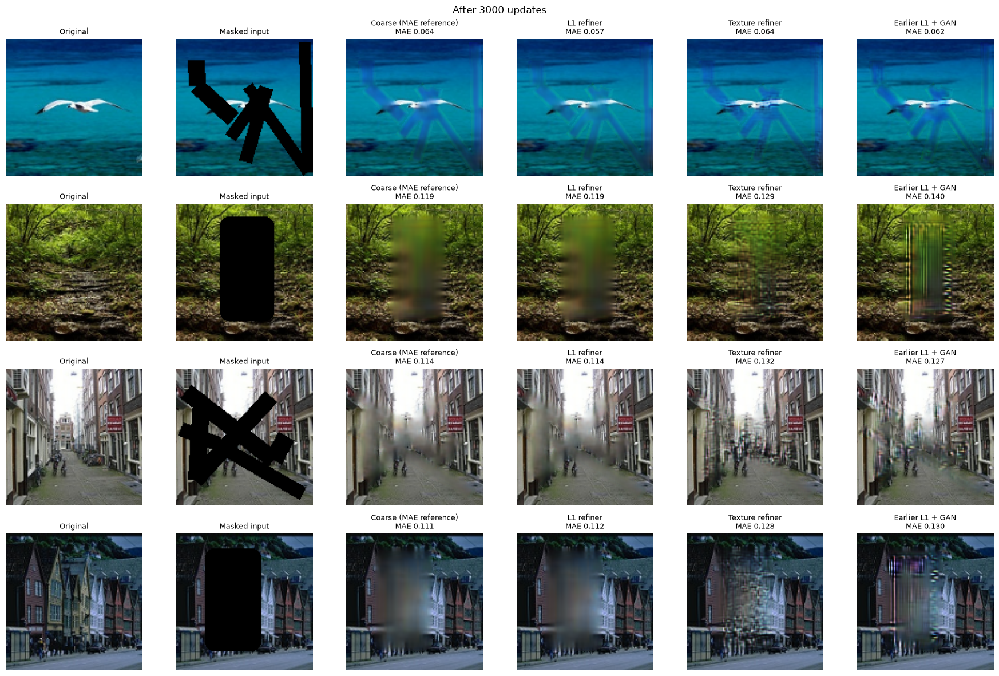

In [ ]:
show_refinement(
    {
        "Coarse (MAE reference)": method_results["Deep U-Net (MAE reference)"],
        "L1 refiner": refined_results["L1 refiner"],
        "Texture refiner": refined_results["Texture refiner"],
        "Earlier L1 + GAN": method_results["L1 + GAN (1,500 updates)"],
    },
    examples,
    f"After {int(refine_completed_steps.numpy())} updates",
)

### Refinement Results

All numbers are on the 400 validation images with the metric section's
masks. Differences are relative to the coarse MAE reference, paired by
image (bootstrap 95% CI) or by KID subset.

**A second L1 network adds almost nothing.** The L1 refiner lowers masked
MAE by 0.0003 (0.3%) and perceptual distance by 0.0045, both small though
consistent. With 2 M additional parameters, the result supports the earlier
conclusion that the L1 objective, not model capacity, limits quality.

**The texture refiner changes the distribution of fills.** Perceptual
distance falls from 0.880 to 0.706 (−0.175, 95% CI [−0.190, −0.160]),
lower on 92% of images. KID×1000 falls from 4.79 to −0.19 ± 1.98, lower in
all 100 paired subsets. KID is unbiased and can be negative; a value near
zero means the refined composites cannot be distinguished from real images
at this sample size and resolution. The texture ratio rises from 0.21 to
0.83, close to the true texture energy (1.0).

**Pixel error rises as expected.** Masked MAE increases by 0.0111 and is
higher on 95% of images. The increase is almost entirely high-frequency
(0.0627 → 0.0767); low-frequency error changes only from 0.0517 to 0.0531.
The refiner adds texture that is not at the true position, as the L1-ceiling
analysis predicted for any texture-producing model.

**Compared with the earlier L1 + GAN generator** at the same MAE (0.1044 vs
0.1045), the texture refiner has lower perceptual distance (0.706 vs 0.838)
and lower KID (−0.19 vs 2.83). These are summary values; this pair was not
tested image by image.

**Training dynamics.** Style loss fell 44% (725 → 403) and was still
decreasing slowly at the end; perceptual loss fell only 2% (273 → 267).
The discriminator hinge loss rose from a minimum of about 1.76 near update
300 to about 1.90, close to the chance value of 2.0, so late in training
the discriminator separates real and refined images only weakly. The
adaptive adversarial weight stayed near 0.05.

**Visible artifacts remain.** In the forest example the refiner produces
foliage-like texture without the vertical stripes of the earlier GAN. On
building facades it produces a blocky mosaic with colour fringing, and the
street example shows vertical streaks. Possible causes, not yet tested: the
Gram style loss matches feature statistics without their spatial
arrangement; the decoder's nearest-neighbour upsampling (×4 from 32 pixels);
and the weak late-stage discriminator. The tinted streaks in the sea
example come from the coarse stage and remain in every method; the refiner
does not correct low-frequency colour errors.

**Limitations.** The texture arm's perceptual and style losses use VGG16,
as does the perceptual-distance metric, so part of that improvement is
circular. KID uses InceptionV3 and is the independent evidence. These are
development-set results, and the illustrative examples were chosen by mask
coverage, not at random. The blind review on the 60-image panel remains
the direct test of whether the measured gain outweighs the visible
artifacts.
